# AI Technologies (Basic Course) · Notebook 03
## Topic 2. Digital image and preprocessing of frames in electro-optical systems

| Lesson | Type, duration | Title |
|---|---|---|
| **2.1** | Lecture, 2 h | Digital image and video stream of electro-optical surveillance devices |
| **2.2** | Group class, 2 h | Stages of preprocessing of video frame data |

Course: *AI Technologies (Basic Course)*, AIT-BC · Content module 1 · Kruty Heroes Military Institute of Telecommunications and Information Technology, Kyiv, 2026.

**How to work with this notebook**

1. Run the cells from top to bottom: *Runtime → Run all*, or `Shift+Enter` cell by cell. Section 0 is always run first; after a restart of the runtime it is run again.
2. Each code cell is preceded by a text cell that describes the block: purpose, parameters, formulas and what to observe.
3. Parameters are set in the form of a code cell (sliders, drop-down lists, check boxes). Cells marked **[auto]** in the title run again automatically after every change of a parameter.
4. The code of a form cell is hidden; a double click on the form (or *View → Show/hide code*) opens it.
5. A GPU is optional. Block 2.1.4-A uses it, when it is available, for the timing of a convolutional neural network (*Runtime → Change runtime type → T4 GPU*).

**Data.** All demonstrations work on real images and videos of open data sets with manual annotation (block 0.2): visible images of camera drones over cities (VisDrone), synchronised visible and thermal sequences of a DJI Mavic 3T with tracked vehicles (M3OT), pixel-aligned visible and thermal pairs of a UAV over city roads with pixel labels (Kust4K), thermal images and videos of a reconnaissance UAV (HIT-UAV) and images of a ground vehicle with pixel labels (GOOSE). The notebook downloads only the files it uses (about 80 MB). Effects that recorded data cannot show with a known reference — the lens of an FPV camera, the radio channel, noise of a given level — are modelled on real frames; the modelled part is stated in each block. Block 0.3 loads a frame of the participant's own for selected blocks.

**Contents**

- **0. Preparation** — 0.1 environment check · 0.2 course library and data sets · 0.3 own frame (optional)
- **Lesson 2.1 (lecture)**
  - 2.1.1 Structure of a digital image as a multidimensional array (tensor)
  - 2.1.2 Colour models RGB, HSV and grey and their use in the video systems of UGVs and UAVs
  - 2.1.3 Formation of the video frame of an FPV drone: optical system, platform motion, radio channel
  - 2.1.4 Resolution, frame rate and computational load
- **Lesson 2.2 (group class)**
  - 2.2.1 Typical degradation factors of the video signal
  - 2.2.2 Noise reduction with Gaussian Blur and Median Blur
  - 2.2.3 CLAHE for night and thermal frames
  - 2.2.4 Change of the geometric parameters of a frame for real-time processing
  - 2.2.5 Letterbox transformation and the standard input of neural network models
- **Summary**: control questions, glossary, data sources and licences

---
# 0. Preparation

### Block 0.1. Environment check

**Purpose.** To record the software and hardware environment of the experiments: the Python version, the versions of the libraries and the available accelerator. The record makes the results reproducible.

**Parameters.** None.

In [1]:
#@title 0.1 Environment check { display-mode: "form" }
import sys, os, platform, time, json, math, importlib, shutil, subprocess
import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

try:
    import torch
    TORCH_VERSION = torch.__version__
    CUDA_OK = torch.cuda.is_available()
    GPU_NAME = torch.cuda.get_device_name(0) if CUDA_OK else None
except ImportError:
    torch, TORCH_VERSION, CUDA_OK, GPU_NAME = None, "not installed", False, None

WORK_DIR = "/content" if IN_COLAB else os.getcwd()
env_table = pd.DataFrame([
    ("Environment", "Google Colab" if IN_COLAB else "local Jupyter"),
    ("Python", platform.python_version()),
    ("Operating system", platform.platform(terse=True)),
    ("CPU cores", os.cpu_count()),
    ("NumPy", np.__version__),
    ("OpenCV", cv2.__version__),
    ("Matplotlib", matplotlib.__version__),
    ("pandas", pd.__version__),
    ("PyTorch", TORCH_VERSION),
    ("GPU", GPU_NAME or "not available (CPU runtime)"),
    ("Working directory", WORK_DIR),
], columns=["Item", "Value"]).set_index("Item")
display(env_table)

,Value
Item,
Environment,local Jupyter
Python,3.12.15
Operating system,Windows-11
CPU cores,16
NumPy,2.5.4
OpenCV,5.0.0
Matplotlib,3.11.2
pandas,3.1.0
PyTorch,2.14.1+cpu


### Block 0.2. Course library and real data sets

**Purpose.** To install the course library `aitbc` (version 2.2.0 adds the functions of Topic 2) and to connect the five open data sets of the course.

| Data set | Platform and sensor | Blocks |
|---|---|---|
| **VisDrone2019-DET** (validation part) | camera drones over cities, oblique and vertical views, boxes of pedestrians and vehicles | 2.1.1, 2.1.3, 2.1.4, 2.2.2, 2.2.4, 2.2.5 |
| **M3OT** | DJI Mavic 3T at 100–120 m: visible and thermal sequences, 10 frames per second, vehicles with track identifiers | 2.1.1, 2.1.4, 2.2.1, 2.2.3, 2.2.5 |
| **Kust4K** | UAV hexacopter: pixel-aligned visible and thermal pairs 640 × 512, day and night, pixel labels of 8 classes | 2.1.1, 2.1.2, 2.2.1, 2.2.3 |
| **HIT-UAV** | DJI Matrice M210 V2 with a DJI Zenmuse XT2 thermal camera: images and videos, boxes of persons and vehicles | 2.1.1, 2.1.3, 2.2.1, 2.2.2, 2.2.3 |
| **GOOSE** (validation part) | ground vehicle with a front camera, pixel labels of 64 classes | 2.1.2, 2.1.3, 2.2.1, 2.2.5 |

Palettes of the thermal images: HIT-UAV — white-hot (warm = bright); M3OT — black-hot (warm = dark; established from the scene in Notebook 02, task 1.3.4); Kust4K — colour palette from purple (cold) to yellow (warm). The brightness is a relative thermal brightness after the automatic gain control of the camera, not a calibrated temperature.

**What the code does.** Writes the module `aitbc.py` into the working directory, imports it, reads the annotation tables and, with `PREFETCH_ALL`, downloads the frames of the notebook into the cache. Large archives are not downloaded completely: the library reads only the required files from them (HTTP range requests). The function `load_frame(source, number)` defined here returns a real frame of a data set with its annotation; the blocks of the lessons use it.

**Parameters.**
- `CACHE_LOCATION` — session disk (the cache is lost when the session ends) or Google Drive (the cache is kept, Colab asks for access to the Google account).
- `PREFETCH_ALL` — download all frames of the notebook now (about 80 MB); otherwise every block downloads its frames on first use.

In [2]:
#@title 0.2 Course library and real data sets (run once) { display-mode: "form" }
CACHE_LOCATION = "session disk (/content/aitbc_data)" #@param ["session disk (/content/aitbc_data)", "Google Drive (MyDrive/AITBC/data_cache)"]
PREFETCH_ALL = True #@param {type:"boolean"}

LIB_SOURCE = r'''"""
aitbc - course library of "AI Technologies (Basic Course)" (AIT-BC).

Kruty Heroes Military Institute of Telecommunications and Information Technology,
Kyiv, 2026.

All demonstrations of the course use REAL open data sets recorded by UAVs and
ground vehicles. Only the files that a block needs are downloaded: large archives
are read selectively with HTTP range requests, and every file is cached in
DATA_ROOT (a Google Drive folder keeps the cache between sessions).

Data sets
---------
HIT-UAV   2898 thermal (LWIR) images 640x512 and 5 thermal videos. DJI Matrice
          M210 V2 with a Zenmuse XT2 camera (25 mm lens, field of view 25 x 20 deg),
          flight altitude 60-130 m, camera angle 30-90 deg, day and night. Boxes of
          Person, Car, Bicycle, OtherVehicle, DontCare.
          Suo J. et al. Scientific Data 10, 227 (2023). Licence CC BY 4.0.
Kust4K    4024 pixel-aligned visible (RGB) and thermal (TIR) image pairs 640x512
          from a hexacopter over urban roads, day and night; pixel labels of 8 classes.
          Scientific Data 12, 1701 (2025). Licence CC BY 4.0.
VisDrone  RGB images of drones over cities (VisDrone2019-DET validation part,
          548 images) with boxes of pedestrians, vehicles and other objects.
          Zhu P. et al. IEEE TPAMI 44(11), 7380-7399 (2022).
GOOSE     camera images of a ground vehicle on roads, field tracks, in forests and on
          a training area, with pixel labels of 64 classes (validation part, 962 images).
          IEEE ICRA 2024. Licence CC BY-SA 4.0.
M3OT      synchronised visible and thermal image sequences of two DJI Mavic 3T drones
          (100-120 m, 10 fps, 640x512, day, dusk, night) with vehicle tracks.
          Nie Z. et al. Scientific Data 12, 1927 (2025). Licence CC BY 4.0.

Units: metres, seconds, degrees. Images are NumPy arrays H x W (grey) or H x W x 3 (RGB).
"""

__version__ = "2.2.0"

import csv
import io
import json
import math
import os
import struct
import time
import urllib.error
import urllib.request
import zlib
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import cv2

DATA_ROOT = os.environ.get("AITBC_DATA") or (
    "/content/aitbc_data" if os.path.isdir("/content") else os.path.abspath("aitbc_data"))


def set_data_root(path):
    """Set the folder of the download cache (for example a folder on Google Drive)."""
    global DATA_ROOT
    DATA_ROOT = os.path.abspath(path)
    os.makedirs(DATA_ROOT, exist_ok=True)
    return DATA_ROOT


def _cache(*parts):
    p = os.path.join(DATA_ROOT, *parts)
    os.makedirs(os.path.dirname(p), exist_ok=True)
    return p


def cache_size():
    """Number of files and size of the download cache, MB."""
    n, s = 0, 0
    for dp, _, fn in os.walk(DATA_ROOT):
        for f in fn:
            n += 1
            s += os.path.getsize(os.path.join(dp, f))
    return n, s / 1e6


# =============================================================================
# 1. Downloading
# =============================================================================
class _HTTPSRedirect(urllib.request.HTTPRedirectHandler):
    """Follow redirects, keep the Range header and upgrade http:// targets to https://."""

    def redirect_request(self, req, fp, code, msg, headers, newurl):
        if newurl.startswith("http://"):
            newurl = "https://" + newurl[len("http://"):]
        new = super().redirect_request(req, fp, code, msg, headers, newurl)
        if new is not None and req.has_header("Range"):
            new.add_header("Range", req.get_header("Range"))
        return new


_OPENER = urllib.request.build_opener(_HTTPSRedirect)
_OPENER.addheaders = [("User-Agent", "aitbc-course/2.0")]


def _urlopen(url, headers=None, timeout=60, retries=4):
    """Open url with retries; a new Request object is built for every attempt."""
    err = None
    for k in range(retries):
        try:
            return _OPENER.open(urllib.request.Request(url, headers=dict(headers or {})), timeout=timeout)
        except urllib.error.HTTPError as e:
            if e.code in (400, 401, 403, 404, 416):
                raise
            err = e
        except Exception as e:                      # network error: retry after a pause
            err = e
        time.sleep(1.5 * (k + 1))
    raise err


def fetch(url, path, timeout=120):
    """Download url to path; nothing is done when the file is already in the cache."""
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    tmp = path + ".part"
    with _urlopen(url, timeout=timeout) as r, open(tmp, "wb") as fh:
        while True:
            b = r.read(1 << 20)
            if not b:
                break
            fh.write(b)
    os.replace(tmp, path)
    return path


def fetch_many(jobs, threads=8):
    """jobs: list of (url, path); parallel download, returns the list of paths."""
    with ThreadPoolExecutor(threads) as ex:
        return list(ex.map(lambda j: fetch(*j), jobs))


class _RangeFile(io.RawIOBase):
    """Seekable read-only file over HTTP range requests (reads the directory of a remote zip)."""

    def __init__(self, url, chunk=1 << 17, timeout=60):
        self.url, self.chunk, self.timeout = url, chunk, timeout
        r = _urlopen(url, {"Range": "bytes=0-0"}, timeout)
        cr = r.headers.get("Content-Range")
        r.read()
        if r.status != 206 or not cr:
            raise IOError(f"the server of {url} does not support range requests")
        self.size = int(cr.split("/")[-1])
        self.pos, self.buf_start, self.buf = 0, 0, b""

    def readable(self):
        return True

    def seekable(self):
        return True

    def tell(self):
        return self.pos

    def seek(self, off, whence=0):
        self.pos = off if whence == 0 else (self.pos + off if whence == 1 else self.size + off)
        return self.pos

    def read(self, n=-1):
        if n is None or n < 0:
            n = self.size - self.pos
        n = min(n, self.size - self.pos)
        if n <= 0:
            return b""
        if not (self.buf_start <= self.pos and self.pos + n <= self.buf_start + len(self.buf)):
            start = self.pos
            end = min(self.size, start + max(n, self.chunk)) - 1
            self.buf = _urlopen(self.url, {"Range": f"bytes={start}-{end}"}, self.timeout).read()
            self.buf_start = start
        off = self.pos - self.buf_start
        out = self.buf[off:off + n]
        self.pos += len(out)
        return out

    def readinto(self, b):
        d = self.read(len(b))
        b[:len(d)] = d
        return len(d)


class RemoteZip:
    """Selective reading of members of a large remote zip archive: only the central
    directory and the requested members are transferred; members are cached on disk."""

    def __init__(self, url, cache_name):
        import zipfile
        self.url, self.cache_name = url, cache_name
        idx_path = _cache("_index", cache_name + ".json")
        if os.path.exists(idx_path):
            with open(idx_path) as fh:
                self.index = json.load(fh)
        else:
            zf = zipfile.ZipFile(_RangeFile(url))
            self.index = {i.filename: (i.header_offset, i.compress_size, i.file_size, i.compress_type)
                          for i in zf.infolist() if not i.filename.endswith("/")}
            with open(idx_path, "w") as fh:
                json.dump(self.index, fh)

    def namelist(self):
        return list(self.index)

    def _fetch_member(self, name):
        path = _cache(self.cache_name, name)
        if os.path.exists(path):
            return path
        off, csize, usize, ctype = self.index[name]
        raw = _urlopen(self.url, {"Range": f"bytes={off}-{off + 30 + 1024 + csize}"}).read()
        if raw[:4] != b"PK\x03\x04":
            raise IOError(f"bad local header of {name}")
        n, m = struct.unpack("<HH", raw[26:30])
        data = raw[30 + n + m: 30 + n + m + csize]
        if ctype == 8:
            data = zlib.decompressobj(-15).decompress(data)
        elif ctype != 0:
            raise IOError(f"unsupported compression {ctype} in {name}")
        if len(data) != usize:
            raise IOError(f"incomplete member {name}")
        with open(path + ".part", "wb") as fh:
            fh.write(data)
        os.replace(path + ".part", path)
        return path

    def get(self, names, threads=8):
        """Download members (a name or a list of names); returns local path(s)."""
        single = isinstance(names, str)
        names = [names] if single else list(names)
        with ThreadPoolExecutor(threads) as ex:
            paths = list(ex.map(self._fetch_member, names))
        return paths[0] if single else paths


def _rgb(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise IOError(f"cannot read {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


# =============================================================================
# 2. Data sets
# =============================================================================
class HITUAV:
    """HIT-UAV: thermal images and videos of a DJI Matrice M210 V2 with a Zenmuse XT2.

    File name T_HHH_AA_W_NNNNN: T = 0 day / 1 night, HHH = flight altitude, m,
    AA = camera angle, deg (90 = vertical view), W = 0 sunny / 1 rainy.
    Images are 8-bit white-hot (warm = bright) after the automatic gain control
    of the camera: brightness is a relative, not a calibrated, temperature."""

    PALETTE = "white-hot"
    BASE = "https://raw.githubusercontent.com/suojiashun/HIT-UAV-Infrared-Thermal-Dataset/main/"
    CLASSES = ("Person", "Car", "Bicycle", "OtherVehicle", "DontCare")
    COLORS = {"Person": (0, 229, 255), "Car": (255, 235, 59), "Bicycle": (118, 255, 3),
              "OtherVehicle": (255, 152, 0), "DontCare": (190, 190, 190)}
    CAMERA = dict(model="DJI Zenmuse XT2, uncooled VOx microbolometer", width=640, height=512,
                  focal_mm=25.0, pixel_pitch_um=17.0, hfov_deg=25.0, vfov_deg=20.0, band_um="7.5-13.5")
    EXAMPLES = ('1_60_30_0_00047.jpg', '0_60_60_0_01734.jpg', '1_70_90_0_07776.jpg', '0_100_50_0_08162.jpg', '1_120_90_0_06161.jpg', '0_130_40_0_05603.jpg', '1_90_70_0_04990.jpg', '0_110_80_0_08518.jpg')
    VIDEOS = {"60m-30_1.mov": "60 m, camera angle 30 deg: people on a sports ground",
              "60m-40_3.mov": "60 m, 40 deg: cars on a parking lot",
              "70m-90_1.mov": "70 m, 90 deg (vertical view): people on a square",
              "120m-30_3.mov": "120 m, 30 deg: road along buildings",
              "130m-60_3.mov": "130 m, 60 deg: parking lot and roads"}

    def __init__(self, splits=("train", "val", "test")):
        import pandas as pd
        imgs, objs = [], []
        jobs = [(self.BASE + f"normal_json/annotations/{sp}.json", _cache("hituav", "annotations", sp + ".json"))
                for sp in splits]
        for sp, path in zip(splits, fetch_many(jobs, 3)):
            with open(path) as fh:
                d = json.load(fh)
            cat = {c["id"]: c["name"] for c in d["categories"]}
            id2f = {}
            for im in d["images"]:
                fn = im.get("filename") or im.get("file_name")
                id2f[im["id"]] = fn
                t, h, a, w = fn.split("_")[:4]
                imgs.append(dict(file=fn, split=sp, night=t == "1", altitude=int(h), angle=int(a), rainy=w == "1"))
            for an in d.get("annotation", d.get("annotations", [])):
                x, y, w, h = an["bbox"]
                objs.append(dict(ann_id=an["id"], file=id2f[an["image_id"]], cls=cat[an["category_id"]],
                                 x1=float(x), y1=float(y), x2=float(x + w), y2=float(y + h)))
        # oriented boxes [xc, yc, w, h, angle]: true width and length of rotated objects
        rjobs = [(self.BASE + f"rotate_json/annotations/{sp}.json", _cache("hituav", "annotations", "rot_" + sp + ".json"))
                 for sp in splits]
        rot = {}
        for path in fetch_many(rjobs, 3):
            with open(path) as fh:
                d = json.load(fh)
            for an in d.get("annotations", d.get("annotation", [])):
                b = an["bbox"]
                rot[an["id"]] = (min(b[2], b[3]), max(b[2], b[3]), b[4] if len(b) > 4 else 0.0)
        self.images = pd.DataFrame(imgs).sort_values("file").reset_index(drop=True)
        o = pd.DataFrame(objs)
        o["w"], o["h"] = o.x2 - o.x1, o.y2 - o.y1
        o["width_px"] = o.ann_id.map(lambda i: rot.get(i, (np.nan,) * 3)[0])     # oriented box: short side
        o["length_px"] = o.ann_id.map(lambda i: rot.get(i, (np.nan,) * 3)[1])    # oriented box: long side
        self.objects = o.merge(self.images[["file", "night", "altitude", "angle"]], on="file", how="left")
        self._split = dict(zip(self.images.file, self.images.split))
        self._groups = {f: g for f, g in self.objects.groupby("file")}
        counts = self.objects.pivot_table(index="file", columns="cls", values="x1", aggfunc="count", fill_value=0)
        self.images = self.images.merge(counts, left_on="file", right_index=True, how="left").fillna(0)

    def _url(self, f):
        return self.BASE + f"normal_json/{self._split[f]}/{f}"

    def path(self, file):
        return fetch(self._url(file), _cache("hituav", self._split[file], file))

    def prefetch(self, files, threads=8):
        return fetch_many([(self._url(f), _cache("hituav", self._split[f], f)) for f in files], threads)

    def load(self, file):
        """Thermal image (H x W uint8) and the list of annotated objects."""
        img = cv2.imread(self.path(file), cv2.IMREAD_GRAYSCALE)
        g = self._groups.get(file)
        objs = [] if g is None else [dict(cls=r.cls, box=[r.x1, r.y1, r.x2, r.y2]) for r in g.itertuples()]
        return img, objs

    def video(self, name):
        return fetch(self.BASE + "video_sample/" + name, _cache("hituav", "video", name))

    @staticmethod
    def video_geometry(name):
        """Flight altitude, m, and camera angle, deg, from a video name such as '60m-30_1.mov'."""
        alt, rest = name.split("m-")
        return int(alt), int(rest.split("_")[0])

    def gsd(self, altitude, angle=90):
        """Ground sampling distance at the image centre, m/px (formula of Lesson 1.1)."""
        rng = altitude / max(math.sin(math.radians(angle)), 1e-3)
        return 2 * rng * math.tan(math.radians(self.CAMERA["hfov_deg"]) / 2) / self.CAMERA["width"]


class Kust4K:
    """Kust4K: pixel-aligned RGB and thermal (TIR) pairs 640x512 of a hexacopter
    HET-3021C over urban roads, day (id ...D) and night (id ...N), with pixel labels.

    The thermal images are pseudo-colour (palette from purple = cold to yellow = warm);
    tir_gray is their luminance, a relative thermal brightness. The data set contains
    frames with SIMULATED failures (visible channel set to zero, thermal channel
    blurred) made by its authors; they are excluded from the curated lists below."""

    PALETTE = "pseudo-colour (purple = cold, yellow = warm)"
    URL = "https://ndownloader.figshare.com/files/{}"
    FILES = {"rgb": 55979147, "tir": 55979165, "seg": 55979159}
    CLASSES = ("unlabelled", "road", "building", "motorcycle", "car", "truck", "tree", "person", "traffic facilities")
    COLORS = np.array([(0, 0, 0), (150, 150, 150), (229, 57, 53), (255, 152, 0), (255, 235, 59),
                       (236, 64, 122), (46, 160, 67), (0, 229, 255), (30, 136, 229)], np.uint8)
    OBJECTS = (3, 4, 5, 7)
    CAMERA = dict(platform="hexacopter HET-3021C", tir_focal_mm=9.1, tir_pixel_um=12.0,
                  rgb="1920x1080, f = 8 mm, registered to the thermal image and resized to 640x512")
    DAY = ("00720D", "00719D", "00031D", "01944D", "00851D", "00580D", "00990D", "00355D", "02094D", "02293D")
    NIGHT = ("02566N", "02807N", "02921N", "03135N", "03685N", "03895N", "03780N", "04004N", "02867N", "02599N")

    def __init__(self):
        self._z = {}

    def _zip(self, key):
        if key not in self._z:
            self._z[key] = RemoteZip(self.URL.format(self.FILES[key]), "kust4k_" + key)
        return self._z[key]

    def prefetch(self, ids, threads=6):
        names = [i + ".png" for i in ids]
        with ThreadPoolExecutor(3) as ex:
            list(ex.map(lambda k: self._zip(k).get(names, threads), ("rgb", "tir", "seg")))

    def pair(self, fid):
        """dict(id, night, rgb, tir, tir_gray, labels) for a frame id such as '00720D'."""
        self.prefetch([fid])
        name = fid + ".png"
        rgb = _rgb(self._zip("rgb").get(name))
        tir = _rgb(self._zip("tir").get(name))
        lab = cv2.imread(self._zip("seg").get(name), cv2.IMREAD_UNCHANGED)
        return dict(id=fid, night=fid.endswith("N"), rgb=rgb, tir=tir,
                    tir_gray=cv2.cvtColor(tir, cv2.COLOR_RGB2GRAY), labels=lab)


class VisDrone:
    """VisDrone2019-DET validation part: RGB images of drones with object boxes.
    Annotation line: x, y, w, h, score, category, truncation, occlusion."""

    URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-val.zip"
    CLASSES = ("ignored region", "pedestrian", "people", "bicycle", "car", "van", "truck", "tricycle",
               "awning-tricycle", "bus", "motor", "others")
    COLORS = {"pedestrian": (0, 229, 255), "people": (0, 176, 255), "bicycle": (118, 255, 3), "car": (255, 235, 59),
              "van": (255, 193, 7), "truck": (255, 152, 0), "tricycle": (186, 104, 200),
              "awning-tricycle": (156, 39, 176), "bus": (244, 67, 54), "motor": (236, 64, 122)}

    CURATED = ('0000213_03920_d_0000243', '0000291_03801_d_0000887', '0000117_00112_d_0000087', '0000001_08414_d_0000013', '0000155_00401_d_0000001', '0000193_01705_d_0000112', '0000295_02400_d_0000033', '0000289_04601_d_0000834', '0000215_00000_d_0000256', '0000327_04001_d_0000731')

    def __init__(self):
        self.z = RemoteZip(self.URL, "visdrone_val")

    def names(self):
        return sorted(n.split("/")[-1][:-4] for n in self.z.namelist() if n.endswith(".jpg"))

    def _members(self, name):
        return [f"VisDrone2019-DET-val/images/{name}.jpg", f"VisDrone2019-DET-val/annotations/{name}.txt"]

    def prefetch(self, names, threads=8):
        self.z.get([m for n in names for m in self._members(n)], threads)

    def load(self, name):
        """RGB image and the list of objects (ignored regions and 'others' are skipped)."""
        pi, pa = self.z.get(self._members(name))
        objs = []
        with open(pa) as fh:
            for line in fh:
                v = line.strip().strip(",").split(",")
                if len(v) < 8:
                    continue
                x, y, w, h, _, c, trunc, occ = (int(float(s)) for s in v[:8])
                if c in (0, 11):
                    continue
                objs.append(dict(cls=self.CLASSES[c], box=[x, y, x + w, y + h], truncation=trunc, occlusion=occ))
        return _rgb(pi), objs


class M3OT:
    """M3OT: synchronised visible (RGB) and thermal (IR) image sequences of two DJI Mavic 3T
    drones flying at 100-120 m (10 frames per second, 640 x 512 px), day, dusk and night, with
    multi-object tracking annotation of vehicles (MOT format: frame, id, x, y, w, h, flag, class,
    confidence). The track identifiers are the same in the RGB and IR sequences of one drone.
    The two channels were aligned by the authors with an affine transform; a residual spatial
    offset of several pixels and a time offset of up to several frames remain (Lesson 1.4).

    The IR frames are 8-bit grey images in the BLACK-HOT palette (warm = dark). The data
    descriptor does not state the palette; it is established from the scene: in all nine
    sequences of drone 1 the road surface is darker than vegetation by day, at dusk and at night,
    while asphalt is, as a rule, the warmer surface (Lesson 1.3, task 1.3.4). Vehicles are
    bright, i.e. cooler than the road. to_white_hot() gives the white-hot convention of HIT-UAV."""

    PALETTE = "black-hot"
    URL = "https://ndownloader.figshare.com/files/52023875"
    CAMERA = dict(platform="DJI Mavic 3T", altitude_m="100-120", fps=10, width=640, height=512,
                  rgb="telephoto camera, f = 29.85 mm (35 mm equivalent 162 mm), frames registered to IR",
                  ir="uncooled thermal camera 640 x 512, f = 9.1 mm (35 mm equivalent 40 mm)")
    SEQUENCES = {"1-01": "day, suburban road", "1-02": "night, city crossroads", "1-03": "day, city road",
                 "1-04": "day, suburban highway", "1-05": "day, crossroads", "1-06": "dusk, highway",
                 "1-07": "day, crossroads", "1-08": "dusk, crossroads", "1-09": "day, city street with parked cars"}

    def __init__(self):
        self.z = RemoteZip(self.URL, "m3ot")
        self._seq = {}
        for n in self.z.namelist():
            parts = n.split("/")        # M3OT/<drone>/<rgb|ir>/<split>/<sequence>/img1/<frame>.PNG
            if len(parts) == 7 and parts[5] == "img1":
                self._seq.setdefault((parts[4].rstrip("T"), parts[2]), []).append(n)
        for k in self._seq:
            self._seq[k].sort()

    def sequences(self):
        return sorted({k[0] for k in self._seq})

    def n_frames(self, seq, channel="rgb"):
        return len(self._seq[(seq, channel)])

    def frame_names(self, seq, channel="rgb", start=0, count=None, step=1):
        names = self._seq[(seq, channel)]
        end = len(names) if count is None else min(len(names), start + count * step)
        return names[start:end:step]

    def prefetch(self, seq, channel="rgb", start=0, count=None, step=1, threads=8):
        return self.z.get(self.frame_names(seq, channel, start, count, step), threads)

    def frames(self, seq, channel="rgb", start=0, count=None, step=1):
        """List of RGB images (H x W x 3) of a sequence; IR frames are grey images in 3 equal channels."""
        return [_rgb(p) for p in self.prefetch(seq, channel, start, count, step)]

    def tracks(self, seq, channel="rgb"):
        """Annotation table: frame (from 1), id, x, y, w, h, cx, cy."""
        import pandas as pd
        names = self._seq[(seq, channel)]
        gt = names[0].rsplit("/img1/", 1)[0] + "/gt/gt.txt"
        g = pd.read_csv(self.z.get(gt), header=None, names=["frame", "id", "x", "y", "w", "h", "flag", "cls", "conf"])
        g["cx"], g["cy"] = g.x + g.w / 2, g.y + g.h / 2
        return g[["frame", "id", "x", "y", "w", "h", "cx", "cy"]]

    def objects(self, table, frame):
        """Objects of one frame in the format of draw_boxes."""
        t = table[table.frame == frame]
        return [dict(cls="vehicle", id=int(r.id), box=[r.x, r.y, r.x + r.w, r.y + r.h]) for r in t.itertuples()]


class GOOSE:
    """GOOSE: front camera of a ground vehicle (2048x1000) with pixel labels of 64 classes."""

    URL = "https://goose-dataset.de/storage/goose_2d_val.zip"
    TRAVERSABLE = ("asphalt", "cobble", "gravel", "soil", "low_grass", "moss", "leaves", "snow",
                   "road_marking", "pedestrian_crossing", "sidewalk", "bikeway")
    CONDITIONAL = ("high_grass", "crops", "debris", "tree_root")
    IGNORE = ("undefined", "sky", "ego_vehicle", "outlier")
    CURATED = (
        'labels/val/2022-07-22_flight/2022-07-22_flight__0078_1658494246011438339_labelids.png',
        'labels/val/2022-07-22_flight/2022-07-22_flight__0158_1658494465090456964_labelids.png',
        'labels/val/2022-08-30_siegertsbrunn_feldwege/2022-08-30_siegertsbrunn_feldwege__0528_1661860582736903436_labelids.png',
        'labels/val/2022-08-30_siegertsbrunn_feldwege/2022-08-30_siegertsbrunn_feldwege__0551_1661860697315889089_labelids.png',
        'labels/val/2022-09-21_garching_uebungsplatz_2/2022-09-21_garching_uebungsplatz_2__0002_1663755194931038715_labelids.png',
        'labels/val/2022-09-21_garching_uebungsplatz_2/2022-09-21_garching_uebungsplatz_2__0038_1663755353192423465_labelids.png',
        'labels/val/2023-03-03_garching_2/2023-03-03_garching_2__0114_1677850404544550420_labelids.png',
        'labels/val/2023-03-03_garching_2/2023-03-03_garching_2__0156_1677850669766430912_labelids.png',
        'labels/val/2022-12-07_aying_hills/2022-12-07_aying_hills__0007_1670420722571435228_labelids.png',
        'labels/val/2022-12-07_aying_hills/2022-12-07_aying_hills__0057_1670421449778652057_labelids.png',
        'labels/val/2022-12-07_aying_hills/2022-12-07_aying_hills__0037_1670421230548919820_labelids.png',
        'labels/val/2023-05-15_neubiberg_rain/2023-05-15_neubiberg_rain__0650_1684157928693659670_labelids.png',
    )

    def __init__(self):
        self.z = RemoteZip(self.URL, "goose_val")
        self.names, self.colors = {}, {}
        with open(self.z.get("goose_label_mapping.csv"), newline="") as fh:
            for row in csv.DictReader(fh):
                k = int(row["label_key"])
                h = row["hex"].lstrip("#")
                self.names[k] = row["class_name"]
                self.colors[k] = tuple(int(h[i:i + 2], 16) for i in (0, 2, 4))
        self.lut = np.zeros((256, 3), np.uint8)
        for k, c in self.colors.items():
            self.lut[k] = c
        self.id_of = {v: k for k, v in self.names.items()}

    def frames(self):
        return sorted(n for n in self.z.namelist() if n.endswith("_labelids.png"))

    @staticmethod
    def _image_member(label_member):
        return label_member.replace("labels/", "images/").replace("_labelids.png", "_windshield_vis.png")

    def prefetch(self, members, threads=6):
        self.z.get([m for lm in members for m in (self._image_member(lm), lm)], threads)

    def load(self, label_member, scale=0.5):
        """RGB image and label map (both resized by `scale`)."""
        pi, pl = self.z.get([self._image_member(label_member), label_member])
        img, lab = _rgb(pi), cv2.imread(pl, cv2.IMREAD_UNCHANGED)
        if scale != 1:
            w, h = int(img.shape[1] * scale), int(img.shape[0] * scale)
            img = cv2.resize(img, (w, h), interpolation=cv2.INTER_AREA)
            lab = cv2.resize(lab, (w, h), interpolation=cv2.INTER_NEAREST)
        return img, lab

    def traversability(self, lab):
        """0 = ignored (sky, own vehicle), 1 = traversable, 2 = conditionally traversable, 3 = obstacle."""
        lut = np.full(256, 3, np.uint8)
        for group, v in ((self.TRAVERSABLE, 1), (self.CONDITIONAL, 2), (self.IGNORE, 0)):
            for n in group:
                if n in self.id_of:
                    lut[self.id_of[n]] = v
        return lut[lab]


# =============================================================================
# 3. Camera geometry
# =============================================================================
def gsd_nadir(altitude, hfov_deg, width_px):
    """Ground sampling distance of a vertical view, m/px: GSD = 2 H tan(alpha/2) / N."""
    return 2 * altitude * math.tan(math.radians(hfov_deg) / 2) / width_px


def hfov_from_sensor(focal_mm, pixel_um, width_px):
    """Horizontal field of view, deg, from the focal length and the pixel pitch."""
    return math.degrees(2 * math.atan(width_px * pixel_um * 1e-3 / 2 / focal_mm))


# =============================================================================
# 4. Degradations of the video signal (applied to real frames)
# =============================================================================
def fractal_noise(shape, rng, octaves=5, start=3, persistence=0.5):
    """Smooth random field in [0, 1] (sum of up-sampled random grids)."""
    h, w = shape
    out = np.zeros((h, w), np.float32)
    amp, m = 1.0, max(h, w)
    for o in range(octaves):
        n = start * (2 ** o)
        grid = rng.random((max(2, int(round(n * h / m)) + 1), max(2, int(round(n * w / m)) + 1)), dtype=np.float32)
        out += amp * cv2.resize(grid, (w, h), interpolation=cv2.INTER_CUBIC)
        amp *= persistence
    out -= out.min()
    return out / max(float(out.max()), 1e-6)


def _f(img):
    return img.astype(np.float32)


def _u8(x):
    return np.clip(x, 0, 255).astype(np.uint8)


def motion_blur(img, length=9.0, angle=0.0):
    """Linear motion blur: the point spread function is a line of `length` px at `angle` deg."""
    if length < 1.5:
        return img.copy()
    size = int(math.ceil(length)) | 1
    k = np.zeros((size * 4, size * 4), np.uint8)
    c = size * 2
    dx = math.cos(math.radians(angle)) * (length - 1) * 2
    dy = -math.sin(math.radians(angle)) * (length - 1) * 2
    cv2.line(k, (int(c - dx), int(c - dy)), (int(c + dx), int(c + dy)), 255, 4, cv2.LINE_AA)
    k = cv2.resize(k.astype(np.float32), (size, size), interpolation=cv2.INTER_AREA)
    return cv2.filter2D(img, -1, k / max(k.sum(), 1e-6), borderType=cv2.BORDER_REFLECT)


def defocus(img, sigma=1.5):
    return img.copy() if sigma <= 0 else cv2.GaussianBlur(img, (0, 0), sigma)


def add_noise(img, sigma=10.0, seed=None):
    rng = np.random.default_rng(seed)
    return _u8(_f(img) + rng.normal(0, sigma, img.shape))


def low_light(img, level=0.15, gain_max=8.0, seed=None):
    """Dark scene and automatic gain: light reduced by `level`, photon and read noise added."""
    if level >= 0.999:
        return img.copy()
    rng = np.random.default_rng(seed)
    lin = (_f(img) / 255.0) ** 2.2 * level
    full_well = 3000.0
    noisy = lin + rng.standard_normal(lin.shape).astype(np.float32) * np.sqrt(lin / full_well + (4.0 / full_well) ** 2)
    gain = float(np.clip(0.16 / max(float(lin.mean()), 1e-6), 1.0, gain_max))
    return _u8(np.clip(noisy * gain, 0, 1) ** (1 / 2.2) * 255)


def haze(img, density=0.4, airlight=200.0):
    """Uniform haze: I = J t + A (1 - t), transmission t = 1 - density."""
    t = 1.0 - float(np.clip(density, 0, 0.98))
    return _u8(_f(img) * t + airlight * (1 - t))


def smoke(img, density=0.5, seed=0, color=170.0, opacity=0.92):
    """Smoke: spatially variable veil."""
    if density <= 0:
        return img.copy()
    n = fractal_noise(img.shape[:2], np.random.default_rng(seed))
    m = np.clip((n - (1.0 - density)) * 3.0, 0, 1) * opacity
    if img.ndim == 3:
        m = m[..., None]
    return _u8(_f(img) * (1 - m) + color * m)


def jpeg(img, quality=30):
    """JPEG compression artefacts."""
    if quality >= 100:
        return img.copy()
    x = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    _, buf = cv2.imencode(".jpg", x, [cv2.IMWRITE_JPEG_QUALITY, int(quality)])
    y = cv2.imdecode(buf, cv2.IMREAD_UNCHANGED)
    return y if img.ndim == 2 else cv2.cvtColor(y, cv2.COLOR_BGR2RGB)


def downscale(img, factor=0.5):
    """Loss of resolution: down-sample by `factor`, then up-sample back."""
    if factor >= 0.999:
        return img.copy()
    h, w = img.shape[:2]
    small = cv2.resize(img, (max(1, int(w * factor)), max(1, int(h * factor))), interpolation=cv2.INTER_AREA)
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)


def rolling_shutter(img, amplitude=6.0, cycles=1.5, phase=0.0):
    """Rolling-shutter distortion: every row is shifted by a sinusoid of the row number."""
    if amplitude <= 0:
        return img.copy()
    h, w = img.shape[:2]
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
    shift = amplitude * np.sin(2 * np.pi * cycles * yy / h + phase)
    return cv2.remap(img, xx + shift, yy, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)


def analog_interference(img, strength=0.5, seed=None):
    """Analog FPV video link with a weak or jammed signal: colour loss, snow, line
    noise, horizontal tearing (loss of synchronisation) and a rolling brightness bar."""
    if strength <= 0:
        return img.copy()
    rng = np.random.default_rng(seed)
    h = img.shape[0]
    x = _f(img)
    if x.ndim == 3:
        gray = x.mean(axis=2, keepdims=True)
        x = gray + (x - gray) * (1 - 0.85 * min(strength * 1.3, 1))
    x += rng.normal(0, 45 * strength, x.shape)
    for r in rng.integers(0, h, int(h * 0.06 * strength)):
        x[r] += rng.normal(70, 40) * strength
    if strength > 0.25:
        y0, band = rng.integers(0, h), int(h * 0.25 * strength)
        offs = np.cumsum(rng.normal(0, 3.0 * strength, band))
        for i in range(band):
            r = (y0 + i) % h
            x[r] = np.roll(x[r], int(offs[i] + 30 * strength), axis=0)
    bar = 1.0 + 0.3 * strength * np.sin(2 * np.pi * (np.arange(h, dtype=np.float32)[:, None] / h * 1.3 + rng.random()))
    return _u8(x * (bar if x.ndim == 2 else bar[..., None]))


def packet_loss(img, rate=0.05, block=16, seed=None):
    """Digital link with lost packets: damaged macroblock slices are filled with a smear
    of the row above or with a grey block."""
    if rate <= 0:
        return img.copy()
    rng = np.random.default_rng(seed)
    out = img.copy()
    gh, gw = img.shape[0] // block, img.shape[1] // block
    lost = rng.random((gh, gw)) < rate
    for r in range(gh):
        c = 0
        while c < gw:
            if lost[r, c]:
                run = int(rng.integers(1, max(2, gw // 3)))
                lost[r, c:c + run] = True
                c += run
            c += 1
    for r, c in zip(*np.nonzero(lost)):
        ys, xs = slice(r * block, (r + 1) * block), slice(c * block, (c + 1) * block)
        if r > 0 and rng.random() < 0.6:
            out[ys, xs] = out[r * block - 1:r * block, xs]
        else:
            out[ys, xs] = 128 if img.ndim == 2 else (60, 128, 60)
    return out


def degrade(img, sensor="visible", motion_px=0.0, motion_angle=0.0, defocus_sigma=0.0, light=1.0, noise=0.0,
            haze_density=0.0, smoke_density=0.0, rolling=0.0, scale=1.0, jpeg_quality=100, analog=0.0,
            packet=0.0, seed=0):
    """Chain of degradations in physical order: atmosphere -> optics and motion -> sensor ->
    resolution -> compression -> radio link. For the thermal sensor haze and smoke are
    attenuated (long-wave infrared passes thin smoke and haze) and low light does not apply."""
    x, ir = img, sensor == "thermal"
    if haze_density > 0:
        x = haze(x, haze_density * (0.25 if ir else 1.0), airlight=128 if ir else 200)
    if smoke_density > 0:
        x = smoke(x, smoke_density, seed=seed, color=128 if ir else 170, opacity=0.18 if ir else 0.92)
    if motion_px > 0:
        x = motion_blur(x, motion_px, motion_angle)
    if defocus_sigma > 0:
        x = defocus(x, defocus_sigma)
    if rolling > 0:
        x = rolling_shutter(x, rolling)
    if light < 1.0 and not ir:
        x = low_light(x, light, seed=seed)
    if noise > 0:
        x = add_noise(x, noise, seed=seed + 1)
    if scale < 1.0:
        x = downscale(x, scale)
    if jpeg_quality < 100:
        x = jpeg(x, jpeg_quality)
    if analog > 0:
        x = analog_interference(x, analog, seed=seed + 2)
    if packet > 0:
        x = packet_loss(x, packet, seed=seed + 3)
    return x


# =============================================================================
# 5. Measures, classical detection, tracking
# =============================================================================
def gray(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)


def psnr(ref, test):
    """Peak signal-to-noise ratio, dB."""
    mse = float(np.mean((_f(ref) - _f(test)) ** 2))
    return float("inf") if mse == 0 else 10 * math.log10(255.0 ** 2 / mse)


def ssim(ref, test):
    """Structural similarity index of grey levels (Gaussian window 11 x 11, sigma 1.5)."""
    a, b = _f(gray(ref)), _f(gray(test))
    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    blur = lambda z: cv2.GaussianBlur(z, (11, 11), 1.5)
    ma, mb = blur(a), blur(b)
    va, vb, cab = blur(a * a) - ma * ma, blur(b * b) - mb * mb, blur(a * b) - ma * mb
    return float((((2 * ma * mb + c1) * (2 * cab + c2)) / ((ma * ma + mb * mb + c1) * (va + vb + c2))).mean())


def sharpness(img):
    """Variance of the Laplacian: a measure of focus (small values = blurred image)."""
    return float(cv2.Laplacian(gray(img), cv2.CV_64F).var())


def to_white_hot(img, palette):
    """Thermal frame in the white-hot convention (warm = bright) as a 3-channel uint8 image.
    palette: "white-hot" (HIT-UAV), "black-hot" (M3OT, inverted here) or a pseudo-colour palette
    whose luminance grows with the temperature (Kust4K: purple = cold, yellow = warm)."""
    g = gray(img)
    if palette.startswith("black"):
        g = 255 - g
    return np.dstack([g, g, g])


def vegetation_mask(rgb, exg_min=0.12, v_min=35, erode_px=15):
    """Vegetation of a visible RGB frame by the excess-green index ExG = (2G - R - B) / (R + G + B).
    The mask is eroded by erode_px so that a residual offset between the visible and the thermal
    channel does not move it onto neighbouring surfaces."""
    f = rgb.astype(np.float32)
    r, g, b = f[..., 0], f[..., 1], f[..., 2]
    exg = (2 * g - r - b) / (r + g + b + 1e-6)
    m = ((exg > exg_min) & (f.max(axis=2) > v_min)).astype(np.uint8)
    if erode_px > 1:
        m = cv2.erode(m, np.ones((erode_px, erode_px), np.uint8))
    return m.astype(bool)


def surroundings_mask(shape, boxes, scale=1.0, gap=3):
    """Background ring around annotated objects (e.g. the road surface around vehicles): every box
    [x1, y1, x2, y2] is expanded by scale x its longer side; the boxes themselves, expanded by gap px,
    are excluded."""
    ring = np.zeros(shape[:2], np.uint8)
    core = np.zeros(shape[:2], np.uint8)
    for x1, y1, x2, y2 in boxes:
        s = int(round(scale * max(x2 - x1, y2 - y1)))
        cv2.rectangle(ring, (int(x1) - s, int(y1) - s), (int(x2) + s, int(y2) + s), 1, -1)
        cv2.rectangle(core, (int(x1) - gap, int(y1) - gap), (int(x2) + gap, int(y2) + gap), 1, -1)
    return (ring > 0) & (core == 0)


def palette_check(thermal, road, vegetation, margin=15, min_pixels=200):
    """Palette of a thermal frame established from the scene. In a road scene the asphalt is, as a
    rule, warmer than vegetation (by day it absorbs most of the solar radiation, at night it gives off
    the stored heat), therefore a road darker than vegetation indicates the black-hot palette
    (warm = dark) and a brighter road the white-hot convention (warm = bright). A shaded or wet road
    and sunlit tree crowns can reverse the order in single frames: check several frames."""
    g = gray(thermal)
    road = road & ~vegetation
    nr, nv = int(road.sum()), int(vegetation.sum())
    r = float(np.median(g[road])) if nr >= min_pixels else float("nan")
    v = float(np.median(g[vegetation])) if nv >= min_pixels else float("nan")
    if np.isnan(r) or np.isnan(v):
        verdict = "not determined: too few road or vegetation pixels"
    elif r < v - margin:
        verdict = "road darker than vegetation: black-hot (warm = dark)"
    elif r > v + margin:
        verdict = "road brighter than vegetation: white-hot (warm = bright)"
    else:
        verdict = f"difference below {margin} grey levels: not determined"
    return dict(road_median=r, vegetation_median=v, road_pixels=nr, vegetation_pixels=nv, verdict=verdict)


def signal_to_clutter(img, mask, exclude=None, gap=2, ring=8):
    """Signal-to-clutter ratio of an object: |mean of object - mean of background ring| /
    standard deviation of the background ring (grey levels)."""
    g = _f(gray(img))
    m = mask.astype(np.uint8)
    k1 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * gap + 1, 2 * gap + 1))
    k2 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * (gap + ring) + 1, 2 * (gap + ring) + 1))
    bg = (cv2.dilate(m, k2) > 0) & (cv2.dilate(m, k1) == 0)
    if exclude is not None:
        bg &= ~exclude
    t, b = g[m > 0], g[bg]
    if t.size < 3 or b.size < 10:
        return float("nan")
    return abs(float(t.mean()) - float(b.mean())) / max(float(b.std()), 1.0)


def box_iou(a, b):
    """Intersection over union of two boxes [x1, y1, x2, y2]."""
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def boxes_from_labels(labels, class_ids, names, min_area=20):
    """Boxes of connected regions of the given classes in a label map."""
    out = []
    for c in class_ids:
        n, cc, stats, _ = cv2.connectedComponentsWithStats((labels == c).astype(np.uint8), connectivity=8)
        for i in range(1, n):
            x, y, w, h, a = stats[i]
            if a >= min_area:
                out.append(dict(cls=names[c], class_id=int(c), box=[float(x), float(y), float(x + w), float(y + h)],
                                area=int(a)))
    return out


def patch_labels(labels, tile, object_ids, names, min_px=10):
    """Patch classification from a label map: every tile receives the object class with
    the largest number of pixels in it, or 'background'."""
    rows, cols = labels.shape[0] // tile, labels.shape[1] // tile
    grid = np.empty((rows, cols), object)
    for r in range(rows):
        for c in range(cols):
            t = labels[r * tile:(r + 1) * tile, c * tile:(c + 1) * tile]
            n, k = max((int((t == k).sum()), k) for k in object_ids)
            grid[r, c] = names[k] if n >= min_px else "background"
    return grid


def detect_hotspots(img, k=5.0, se_px=21, min_area=4, max_area=5000):
    """Classical detector of small warm objects in a white-hot thermal image: white
    top-hat (local contrast) -> threshold mean + k std -> connected components.
    Returns boxes (N, 4) [x1, y1, x2, y2] and the binary mask."""
    g = cv2.GaussianBlur(gray(img), (3, 3), 0)
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (int(se_px) | 1, int(se_px) | 1))
    th = cv2.morphologyEx(g, cv2.MORPH_TOPHAT, se).astype(np.float32)
    mask = (th > th.mean() + k * th.std()).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask, 8)
    boxes = [[x, y, x + w, y + h] for x, y, w, h, a in stats[1:] if min_area <= a <= max_area]
    return np.array(boxes, float).reshape(-1, 4), mask


def expected_size_px(gsd, size_m=0.45, margin_px=6.0):
    """Expected size of an object in an annotated box, px: size_m / GSD + margin_px.
    Defaults: nominal shoulder width of a person 0.45 m and a margin of 6 px (blur, thermal halo,
    annotation margin). For comparison, a least-squares fit to the HIT-UAV boxes of persons in
    vertical views gives d = 0.38 m and m = 6.6 px; block 1.1.1-B computes the fit for every class."""
    return size_m / gsd + margin_px


def detect_warm_objects(img, gsd, k=6.0, size_m=0.45, margin_px=6.0):
    """Hot-spot detector adapted to the ground sampling distance: the structuring element
    and the admissible blob areas follow the expected size of a person in pixels."""
    s = expected_size_px(gsd, size_m, margin_px)
    return detect_hotspots(img, k=k, se_px=int(max(7, round(2.5 * s))) | 1,
                           min_area=max(3, int((0.3 * s) ** 2)), max_area=int((2.0 * s) ** 2))


def match_detections(pred, objects, target_classes, pad=2.0):
    """A detection is correct when its centre lies inside a (padded) box of an object of a
    target class. Detections inside boxes of other annotated objects are counted apart.
    Returns dict(tp, fp, other, missed, recall, precision)."""
    tgt = [o for o in objects if o["cls"] in target_classes]
    oth = [o for o in objects if o["cls"] not in target_classes]
    used, tp, fp, other = set(), [], [], []
    inside = lambda o, cx, cy: (o["box"][0] - pad <= cx <= o["box"][2] + pad and o["box"][1] - pad <= cy <= o["box"][3] + pad)
    for b in pred:
        cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
        hit = next((i for i, o in enumerate(tgt) if i not in used and inside(o, cx, cy)), None)
        if hit is not None:
            used.add(hit)
            tp.append(list(b))
        elif any(inside(o, cx, cy) for o in oth) or any(inside(o, cx, cy) for o in tgt):
            other.append(list(b))
        else:
            fp.append(list(b))
    n = len(tgt)
    return dict(tp=tp, fp=fp, other=other, missed=[o for i, o in enumerate(tgt) if i not in used],
                recall=len(tp) / n if n else float("nan"), precision=len(tp) / max(len(tp) + len(fp), 1))


def global_shift(prev, cur):
    """Translation of the image content from `prev` to `cur` (phase correlation), px."""
    (dx, dy), _ = cv2.phaseCorrelate(_f(gray(prev)), _f(gray(cur)))
    return dx, dy


class NearestNeighbourTracker:
    """Simple multi-object tracker: the detections of a frame are linked to the tracks of
    the previous frame by the smallest distance after compensation of the camera motion.
    A track is closed after `max_missed` frames without a detection."""

    def __init__(self, max_dist=12.0, max_missed=4):
        self.max_dist, self.max_missed = max_dist, max_missed
        self.tracks, self.closed, self.next_id = {}, {}, 1
        self.offset = np.zeros(2)                    # accumulated camera motion, px

    def update(self, centres, shift=(0.0, 0.0), frame=0):
        """centres: (N, 2) detections of the frame; shift: image motion since the previous frame.
        Returns the list of (track id, centre) of the frame."""
        self.offset += np.asarray(shift, float)
        pts = np.asarray(centres, float).reshape(-1, 2) - self.offset      # coordinates of the first frame
        ids = list(self.tracks)
        pairs = []
        for i, tid in enumerate(ids):
            last = self.tracks[tid]["hist"][-1][1]
            for j, p in enumerate(pts):
                d = float(np.hypot(*(p - last)))
                if d <= self.max_dist:
                    pairs.append((d, tid, j))
        pairs.sort()
        used_t, used_d, out = set(), set(), []
        for d, tid, j in pairs:
            if tid in used_t or j in used_d:
                continue
            used_t.add(tid)
            used_d.add(j)
            self.tracks[tid]["hist"].append((frame, pts[j]))
            self.tracks[tid]["missed"] = 0
            out.append((tid, pts[j] + self.offset))
        for tid in ids:
            if tid not in used_t:
                self.tracks[tid]["missed"] += 1
                if self.tracks[tid]["missed"] > self.max_missed:
                    self.closed[tid] = self.tracks.pop(tid)
        for j, p in enumerate(pts):
            if j not in used_d:
                self.tracks[self.next_id] = dict(hist=[(frame, p)], missed=0)
                out.append((self.next_id, p + self.offset))
                self.next_id += 1
        return out

    def history(self, tid):
        """Trajectory of a track in the coordinates of the current frame."""
        t = self.tracks.get(tid) or self.closed.get(tid)
        return np.array([p for _, p in t["hist"]]) + self.offset


def track_warm_objects(frames, gsd, fps, k=5.0, max_speed_ms=2.5, max_missed=4, min_len=12, min_disp_m=2.0):
    """Detection and tracking of warm objects in a thermal video:
    detect_warm_objects -> camera motion by phase correlation -> NearestNeighbourTracker.
    A track is reported as a moving object when it lasts at least `min_len` frames and its
    start and end points are at least `min_disp_m` apart on the ground.
    Returns (tracker, moving: {id: trajectory (K, 2) in the last frame}, rows: list of
    (frame, track id, x, y), detections per frame)."""
    tr = NearestNeighbourTracker(max_dist=max(5.0, max_speed_ms / gsd / max(fps, 1e-6) + 3.0), max_missed=max_missed)
    prev, rows, n_det = None, [], []
    for i, f in enumerate(frames):
        g = gray(f)
        b, _ = detect_warm_objects(g, gsd, k=k)
        c = np.c_[(b[:, 0] + b[:, 2]) / 2, (b[:, 1] + b[:, 3]) / 2] if len(b) else np.zeros((0, 2))
        shift = global_shift(prev, g) if prev is not None else (0.0, 0.0)
        for tid, p in tr.update(c, shift, i):
            rows.append((i, tid, float(p[0]), float(p[1])))
        n_det.append(len(b))
        prev = g
    moving = {}
    for tid, t in {**tr.closed, **tr.tracks}.items():
        pts = np.array([p for _, p in t["hist"]])
        if len(pts) >= min_len and float(np.hypot(*(pts[-1] - pts[0]))) * gsd >= min_disp_m:
            moving[tid] = pts + tr.offset
    return tr, moving, rows, n_det


def video_info(path):
    """Properties of a video file read by OpenCV."""
    cap = cv2.VideoCapture(path)
    info = dict(path=path, opened=cap.isOpened(), fps=cap.get(cv2.CAP_PROP_FPS),
                frames=int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), width=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
                height=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
                codec=int(cap.get(cv2.CAP_PROP_FOURCC)).to_bytes(4, "little").decode("latin-1", "replace"))
    cap.release()
    info["duration_s"] = info["frames"] / info["fps"] if info["fps"] else float("nan")
    info["size_mb"] = os.path.getsize(path) / 1e6 if os.path.exists(path) else float("nan")
    return info


def iter_video(path, every_n=1, max_frames=None, start=0):
    """Generator of (frame number, timestamp s, RGB frame) of every n-th frame of a video:
    frames are decoded one by one, so a long video does not fill the memory."""
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 1.0
    if start:
        cap.set(cv2.CAP_PROP_POS_FRAMES, start)
    k, n_out = start, 0
    try:
        while True:
            ok, f = cap.read()
            if not ok or (max_frames is not None and n_out >= max_frames):
                break
            if (k - start) % every_n == 0:
                yield k, k / fps, cv2.cvtColor(f, cv2.COLOR_BGR2RGB)
                n_out += 1
            k += 1
    finally:
        cap.release()


def write_video(path, frames, fps, codec="mp4v"):
    """Write RGB or grey frames to a video file; returns the path. Codec 'mp4v' (.mp4) works in
    Colab and in most OpenCV builds; 'MJPG' (.avi) stores every frame as JPEG."""
    h, w = frames[0].shape[:2]
    wr = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*codec), float(fps), (w, h))
    if not wr.isOpened():
        raise IOError(f"OpenCV cannot write the codec {codec}")
    for f in frames:
        f = to_rgb(f)
        if f.shape[:2] != (h, w):
            f = cv2.resize(f, (w, h))
        wr.write(cv2.cvtColor(f, cv2.COLOR_RGB2BGR))
    wr.release()
    return path


def contact_sheet(frames, cols=6, width=1600, labels=None, font=0.5):
    """Grid of frames for a quick visual review of a sequence."""
    n = len(frames)
    rows = int(math.ceil(n / cols))
    tw = width // cols
    th = int(round(tw * frames[0].shape[0] / frames[0].shape[1]))
    sheet = np.zeros((rows * th, cols * tw, 3), np.uint8)
    for i, f in enumerate(frames):
        r, c = divmod(i, cols)
        t = cv2.resize(to_rgb(f), (tw, th), interpolation=cv2.INTER_AREA)
        if labels is not None:
            cv2.rectangle(t, (0, 0), (tw, 18), (0, 0, 0), -1)
            cv2.putText(t, str(labels[i]), (4, 13), cv2.FONT_HERSHEY_SIMPLEX, font * 0.8, (255, 255, 0), 1, cv2.LINE_AA)
        sheet[r * th:(r + 1) * th, c * tw:(c + 1) * tw] = t
    return sheet


def frame_difference(a, b):
    """Mean absolute difference of the grey levels of two frames."""
    return float(np.mean(np.abs(_f(gray(a)) - _f(gray(b)))))


def grad_magnitude(img, sigma=1.5):
    """Normalised gradient magnitude; edges of a visible and a thermal image of the same scene
    are similar even when their brightness is not, so it is used to compare the two channels."""
    g = cv2.GaussianBlur(_f(gray(img)), (0, 0), sigma)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return (m - m.mean()) / (m.std() + 1e-6)


def channel_shift(img_a, img_b):
    """Translation between two images of different sensors (phase correlation of gradient
    magnitudes): (dx, dy, response). The response is low when the images have little common structure."""
    a, b = grad_magnitude(img_a), grad_magnitude(img_b)
    win = cv2.createHanningWindow((a.shape[1], a.shape[0]), cv2.CV_32F)
    (dx, dy), resp = cv2.phaseCorrelate(a, b, win)
    return float(dx), float(dy), float(resp)


def track_offsets(table_a, table_b, lag=0):
    """Offsets of the centres of the same track (same id) in two annotated channels:
    channel b at frame t is compared with channel a at frame t + lag. Returns arrays dx, dy."""
    bb = table_b[["id", "frame", "cx", "cy"]].copy()
    bb["frame"] = bb["frame"] + lag
    m = bb.merge(table_a[["id", "frame", "cx", "cy"]], on=["id", "frame"], suffixes=("_b", "_a"))
    return (m.cx_b - m.cx_a).values, (m.cy_b - m.cy_a).values


def read_video(path, step=1, max_frames=None, start=0):
    """Frames of a video file (BGR from OpenCV converted to RGB) and the frame rate."""
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 0.0
    cap.set(cv2.CAP_PROP_POS_FRAMES, start)
    frames, k = [], 0
    while True:
        ok, f = cap.read()
        if not ok or (max_frames and len(frames) >= max_frames):
            break
        if k % step == 0:
            frames.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
        k += 1
    cap.release()
    return frames, fps


# =============================================================================
# 6. Visualisation
# =============================================================================
def to_rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_GRAY2RGB) if img.ndim == 2 else img


def colorize(labels, colors):
    """Label map -> RGB image with the colour table `colors` (array K x 3)."""
    return np.asarray(colors, np.uint8)[np.clip(labels, 0, len(colors) - 1)]


def overlay(img, color_img, alpha=0.5, mask=None):
    base, col = _f(to_rgb(img)), _f(color_img)
    a = np.full(base.shape[:2], alpha, np.float32) if mask is None else mask.astype(np.float32) * alpha
    return _u8(base * (1 - a[..., None]) + col * a[..., None])


def draw_boxes(img, objects, colors=None, labels=True, scores=None, ids=None, thickness=1, font=0.4, color=None):
    """Draw boxes of objects (dicts with 'box' and 'cls')."""
    out = to_rgb(img).copy()
    for i, o in enumerate(objects):
        x1, y1, x2, y2 = [int(round(v)) for v in o["box"]]
        c = color if color is not None else (colors or {}).get(o["cls"], (255, 255, 0))
        c = tuple(int(v) for v in c)
        cv2.rectangle(out, (x1, y1), (x2, y2), c, thickness, cv2.LINE_AA)
        txt = []
        if labels:
            txt.append(str(o["cls"]))
        if ids is not None:
            txt.append(f"#{ids[i]}")
        if scores is not None:
            txt.append(f"{scores[i]:.2f}")
        if txt:
            s = " ".join(txt)
            (tw, th), _ = cv2.getTextSize(s, cv2.FONT_HERSHEY_SIMPLEX, font, 1)
            y0 = max(y1 - 3, th + 2)
            cv2.rectangle(out, (x1, y0 - th - 2), (x1 + tw + 2, y0 + 2), c, -1)
            cv2.putText(out, s, (x1 + 1, y0), cv2.FONT_HERSHEY_SIMPLEX, font, (0, 0, 0), 1, cv2.LINE_AA)
    return out


def legend(ax, names, colors, loc="lower right", fontsize=7, ncol=1):
    import matplotlib.patches as mpatches
    ax.legend(handles=[mpatches.Patch(color=np.array(c) / 255.0, label=n) for n, c in zip(names, colors)],
              loc=loc, fontsize=fontsize, ncol=ncol, framealpha=0.85)


def setup_plots():
    import matplotlib.pyplot as plt
    plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8,
                         "ytick.labelsize": 8, "legend.fontsize": 8, "figure.facecolor": "white"})


def catalogue():
    """Table of the data sets of the course."""
    return [
        ("HIT-UAV", "UAV DJI M210 V2, thermal camera Zenmuse XT2 (640x512, 25 x 20 deg)",
         "2898 thermal images, 5 thermal videos; boxes of persons and vehicles; 60-130 m, day and night",
         "CC BY 4.0", "Suo J. et al., Scientific Data 10, 227 (2023)",
         "https://github.com/suojiashun/HIT-UAV-Infrared-Thermal-Dataset"),
        ("Kust4K", "UAV hexacopter HET-3021C, visible + thermal cameras",
         "4024 pixel-aligned RGB-thermal pairs 640x512 over urban roads, day and night; pixel labels of 8 classes",
         "CC BY 4.0", "Scientific Data 12, 1701 (2025)", "https://doi.org/10.6084/m9.figshare.29476610"),
        ("VisDrone2019-DET (val)", "camera drones of different types, 14 Chinese cities",
         "548 RGB images; boxes of pedestrians, cars, vans, trucks, buses, motors and others",
         "research use, see the data set site", "Zhu P. et al., IEEE TPAMI 44(11), 7380-7399 (2022)",
         "https://github.com/VisDrone/VisDrone-Dataset"),
        ("GOOSE (val)", "ground vehicle, front RGB camera 2048x1000",
         "962 images of roads, field tracks, forests and a training area; pixel labels of 64 classes",
         "CC BY-SA 4.0", "IEEE ICRA 2024 (arXiv:2310.16788)", "https://goose-dataset.de"),
    ]


# =====================================================================================
# Topic 2. Digital image, video frame formation and preprocessing
# =====================================================================================
def quantize(img, bits):
    """Brightness quantised to `bits` bits per channel (2**bits levels), shown again in 0...255."""
    step = 256.0 / (2 ** int(bits))
    return np.clip(np.floor(img.astype(np.float32) / step) * step + step / 2, 0, 255).astype(np.uint8)


def entropy(img):
    """Entropy of the brightness histogram, bit (8 bit = all 256 levels used equally)."""
    hist = np.bincount(gray(img).ravel(), minlength=256).astype(float)
    p = hist[hist > 0] / hist.sum()
    return float(-(p * np.log2(p)).sum())


def rms_contrast(img):
    """RMS contrast: standard deviation of the grey levels."""
    return float(_f(gray(img)).std())


def average_gradient(img):
    """Average gradient: mean of sqrt((gx^2 + gy^2) / 2) of the grey levels (central differences)."""
    g = _f(gray(img))
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=1)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=1)
    return float(np.sqrt((gx ** 2 + gy ** 2) / 2.0).mean())


def hsv_mask(rgb, h=(35, 85), s=(40, 255), v=(40, 255)):
    """Pixels whose hue (degrees, 0...360), saturation and value (0...255) lie in the given ranges.
    OpenCV stores the hue of 8-bit images as degrees / 2 (0...179); a range with h[0] > h[1]
    passes through 0 degrees (red)."""
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    hh = hsv[..., 0].astype(np.int32) * 2
    mh = ((hh >= h[0]) & (hh <= h[1])) if h[0] <= h[1] else ((hh >= h[0]) | (hh <= h[1]))
    return mh & (hsv[..., 1] >= s[0]) & (hsv[..., 1] <= s[1]) & (hsv[..., 2] >= v[0]) & (hsv[..., 2] <= v[1])


def mask_scores(pred, truth, valid=None):
    """IoU, precision and recall of a binary mask against a reference mask; pixels outside `valid` are ignored."""
    if valid is not None:
        pred, truth = pred & valid, truth & valid
    tp = int((pred & truth).sum())
    fp = int((pred & ~truth).sum())
    fn = int((~pred & truth).sum())
    return dict(iou=tp / max(tp + fp + fn, 1), precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1))


def box_mask(shape, box):
    """Binary mask of a box [x1, y1, x2, y2]."""
    m = np.zeros(shape[:2], bool)
    x1, y1, x2, y2 = (int(round(v)) for v in box)
    m[max(0, y1):max(0, y2), max(0, x1):max(0, x2)] = True
    return m


def colour_planes(rgb, thermal=None):
    """8-bit planes of the colour models of a frame: R, G, B, grey (luma Y = 0.299 R + 0.587 G + 0.114 B),
    H (degrees / 2), S, V and, if given, the thermal channel."""
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    planes = {"R": rgb[..., 0], "G": rgb[..., 1], "B": rgb[..., 2], "grey": cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY),
              "H": hsv[..., 0], "S": hsv[..., 1], "V": hsv[..., 2]}
    if thermal is not None:
        planes["thermal"] = gray(thermal)
    return planes


def wide_angle_lens(img, barrel=0.2, vignetting=0.0):
    """Wide-angle lens of an FPV camera: barrel distortion and vignetting. The output pixel at the
    normalised radius r (r = 1 in the corners) shows the point of the ideal image at r (1 + b r^2) / (1 + b):
    the corners stay in place, the centre is magnified by 1 + b, straight lines bend outwards.
    OpenCV describes the same distortion with a negative coefficient k1 of its camera model.
    Vignetting: the brightness is multiplied by 1 - v r^2."""
    h, w = img.shape[:2]
    cx, cy = (w - 1) / 2.0, (h - 1) / 2.0
    rmax = math.hypot(cx, cy)
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
    dx, dy = (xx - cx) / rmax, (yy - cy) / rmax
    r2 = dx * dx + dy * dy
    f = (1 + barrel * r2) / (1 + barrel)
    out = cv2.remap(img, (cx + dx * f * rmax).astype(np.float32), (cy + dy * f * rmax).astype(np.float32),
                    cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    if vignetting > 0:
        v = np.clip(1 - vignetting * r2, 0, 1)
        out = _u8(_f(out) * (v if out.ndim == 2 else v[..., None]))
    return out


def free_space_loss_db(distance_m, freq_mhz):
    """Free-space path loss, dB: 20 lg(d, km) + 20 lg(f, MHz) + 32.44."""
    return 20 * math.log10(max(distance_m, 1.0) / 1000.0) + 20 * math.log10(freq_mhz) + 32.44


def link_budget(p_tx_mw, distance_m, freq_mhz=5800.0, g_tx_dbi=2.0, g_rx_dbi=2.0, extra_loss_db=0.0,
                bandwidth_mhz=20.0, noise_figure_db=6.0, interference_db=0.0):
    """Line-of-sight radio link: received power P_rx = P_tx + G_tx + G_rx - L_fs - L_add, dBm; noise power
    N = -174 + 10 lg(B, Hz) + NF, dBm, raised by `interference_db` (jamming); carrier-to-noise ratio CNR = P_rx - N."""
    p_tx = 10 * math.log10(p_tx_mw)
    fspl = free_space_loss_db(distance_m, freq_mhz)
    p_rx = p_tx + g_tx_dbi + g_rx_dbi - fspl - extra_loss_db
    noise = -174.0 + 10 * math.log10(bandwidth_mhz * 1e6) + noise_figure_db + interference_db
    return dict(p_tx_dbm=p_tx, fspl_db=fspl, p_rx_dbm=p_rx, noise_dbm=noise, cnr_db=p_rx - noise)


def analog_link_frame(img, cnr_db, threshold_db=10.0, fm_gain_db=25.0, seed=0):
    """Frame at the output of an analog FM video receiver (ILLUSTRATIVE model of the course, not a standard):
    above the FM threshold the picture has Gaussian noise with SNR = CNR + fm_gain_db; below the threshold
    impulse noise ("sparkles"), loss of colour and loss of line synchronisation grow with the deficit
    threshold - CNR; at a deficit of 6 dB and more the picture is replaced by noise."""
    rng = np.random.default_rng(seed)
    x = _f(img)
    x = x + rng.normal(0, 255.0 * 10 ** (-(cnr_db + fm_gain_db) / 20.0), x.shape)
    deficit = threshold_db - cnr_db
    if deficit >= 6:
        return _u8(rng.normal(128, 60, img.shape))
    if deficit > 0:
        imp = rng.random(x.shape[:2]) < min(0.5, 0.012 * deficit ** 2)
        vals = rng.choice(np.array([0.0, 255.0], np.float32), size=int(imp.sum()))
        x[imp] = vals[:, None] if x.ndim == 3 else vals
        return analog_interference(_u8(x), strength=min(1.0, deficit / 6.0), seed=seed)
    return _u8(x)


def jpeg_for_budget(img, bytes_per_frame):
    """Highest JPEG quality (5...95) whose file of this frame fits into `bytes_per_frame`: intra-frame
    equivalent of a digital video link with a given bit rate. Returns (decoded frame, quality, bytes)."""
    bgr = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    best = None
    lo, hi = 5, 95
    while lo <= hi:
        q = (lo + hi) // 2
        ok, buf = cv2.imencode(".jpg", bgr, [cv2.IMWRITE_JPEG_QUALITY, q])
        if len(buf) <= bytes_per_frame:
            best, lo = (q, buf), q + 1
        else:
            hi = q - 1
    if best is None:
        ok, buf = cv2.imencode(".jpg", bgr, [cv2.IMWRITE_JPEG_QUALITY, 5])
        best = (5, buf)
    dec = cv2.imdecode(best[1], cv2.IMREAD_UNCHANGED)
    return (dec if dec.ndim == 2 else cv2.cvtColor(dec, cv2.COLOR_BGR2RGB)), best[0], len(best[1])


def digital_packet_loss_rate(cnr_db, required_db=8.0, width_db=0.4):
    """Packet loss rate of a digital link near its sensitivity (ILLUSTRATIVE logistic model of the "cliff
    effect"): 0.5 at CNR = required_db, 0.1 % at a margin of about 2.8 dB."""
    return float(1.0 / (1.0 + math.exp((cnr_db - required_db) / width_db)))


def noise_sigma(img, exclude_edges=0.1):
    """Standard deviation of the noise of a frame by the method of Immerkaer (1996): the frame is filtered with
    the mask [[1,-2,1],[-2,4,-2],[1,-2,1]], which suppresses the smooth structure of the scene, and
    sigma = sqrt(pi/2) / 6 * mean |filtered|. Edges and fine texture increase the estimate, therefore the
    share `exclude_edges` of the pixels with the strongest gradient of the smoothed frame is excluded.
    For a colour frame the estimate is the mean over the R, G, B channels (noise of one channel)."""
    if img.ndim == 3 and not (np.array_equal(img[..., 0], img[..., 1]) and np.array_equal(img[..., 1], img[..., 2])):
        return float(np.mean([noise_sigma(img[..., c], exclude_edges) for c in range(3)]))
    g = _f(gray(img))
    k = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)
    r = np.abs(cv2.filter2D(g, -1, k))[1:-1, 1:-1]
    if exclude_edges > 0:
        sm = cv2.GaussianBlur(g, (0, 0), 2.0)           # edges of the scene, not of the noise
        gx = cv2.Sobel(sm, cv2.CV_32F, 1, 0, ksize=3)[1:-1, 1:-1]
        gy = cv2.Sobel(sm, cv2.CV_32F, 0, 1, ksize=3)[1:-1, 1:-1]
        gm = gx * gx + gy * gy
        r = r[gm <= np.quantile(gm, 1 - exclude_edges)]
    return float(math.sqrt(math.pi / 2) * r.mean() / 6.0)


def add_gaussian_noise(img, sigma, seed=0):
    """Additive Gaussian noise with the standard deviation sigma (grey levels)."""
    rng = np.random.default_rng(seed)
    return _u8(_f(img) + rng.normal(0, sigma, img.shape))


def add_impulse_noise(img, amount, seed=0):
    """Impulse ("salt and pepper") noise: the share `amount` of the pixels becomes black or white."""
    rng = np.random.default_rng(seed)
    out = img.copy()
    m = rng.random(img.shape[:2]) < amount
    vals = rng.choice(np.array([0, 255], np.uint8), size=int(m.sum()))
    out[m] = vals[:, None] if img.ndim == 3 else vals
    return out


def equalize(img, method="clahe", clip=2.0, tiles=8):
    """Global histogram equalisation (method "he") or CLAHE ("clahe": tiles x tiles regions, histogram of every
    region clipped at clip x its mean height) of a grey frame or of the lightness L* of a colour frame (CIE L*a*b*)."""
    def one(g):
        if method == "he":
            return cv2.equalizeHist(g)
        return cv2.createCLAHE(clipLimit=float(clip), tileGridSize=(int(tiles), int(tiles))).apply(g)
    if img.ndim == 2:
        return one(img)
    if np.array_equal(img[..., 0], img[..., 1]) and np.array_equal(img[..., 1], img[..., 2]):
        g = one(img[..., 0])
        return np.dstack([g, g, g])
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    lab[..., 0] = one(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


def letterbox(img, size=640, stride=32, auto=False, scaleup=True, color=114):
    """Letterbox transformation to the input of a detector: the frame is scaled by r = min(S / H, S / W)
    without a change of its aspect ratio and padded symmetrically with the grey value `color` to S x S
    (auto=True: only to the nearest multiple of `stride`). Returns the image, r and the padding (left, top)."""
    h, w = img.shape[:2]
    r = min(size / h, size / w)
    if not scaleup:
        r = min(r, 1.0)
    nw, nh = int(round(w * r)), int(round(h * r))
    dw, dh = size - nw, size - nh
    if auto:
        dw, dh = dw % stride, dh % stride
    dw, dh = dw / 2.0, dh / 2.0
    if (nw, nh) != (w, h):
        img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    top, bottom = int(round(dh - 0.1)), int(round(dh + 0.1))
    left, right = int(round(dw - 0.1)), int(round(dw + 0.1))
    value = (color, color, color) if img.ndim == 3 else color
    return cv2.copyMakeBorder(img, top, bottom, left, right, cv2.BORDER_CONSTANT, value=value), r, (left, top)


def boxes_to_input(boxes, r, pad):
    """Boxes [x1, y1, x2, y2] of the frame mapped to the letterboxed input: x' = r x + left, y' = r y + top."""
    return [[b[0] * r + pad[0], b[1] * r + pad[1], b[2] * r + pad[0], b[3] * r + pad[1]] for b in boxes]


def boxes_from_input(boxes, r, pad):
    """Inverse mapping of boxes of the letterboxed input to the frame: x = (x' - left) / r, y = (y' - top) / r."""
    return [[(b[0] - pad[0]) / r, (b[1] - pad[1]) / r, (b[2] - pad[0]) / r, (b[3] - pad[1]) / r] for b in boxes]


def to_input_tensor(img):
    """Standard input of a neural network: RGB, float32 in 0...1, layout N x C x H x W (N = 1)."""
    x = to_rgb(img).astype(np.float32) / 255.0
    return np.ascontiguousarray(x.transpose(2, 0, 1)[None])


def time_call(fn, repeats=5, warmup=1):
    """Median execution time of fn() in milliseconds."""
    for _ in range(warmup):
        fn()
    t = []
    for _ in range(max(1, repeats)):
        t0 = time.perf_counter()
        fn()
        t.append((time.perf_counter() - t0) * 1000.0)
    return float(np.median(t))


def step_overlap(tracks, step):
    """Overlap and displacement of every annotated object between the frames t and t + step of a track table
    (columns frame, id, x, y, w, h): IoU of its two boxes, displacement of the centre (px) and box size."""
    import pandas as pd
    a = tracks[["frame", "id", "x", "y", "w", "h"]]
    b = a.copy()
    b["frame"] = b["frame"] - step
    m = a.merge(b, on=["id", "frame"], suffixes=("", "_n"))
    ix = (np.minimum(m.x + m.w, m.x_n + m.w_n) - np.maximum(m.x, m.x_n)).clip(lower=0)
    iy = (np.minimum(m.y + m.h, m.y_n + m.h_n) - np.maximum(m.y, m.y_n)).clip(lower=0)
    inter = ix * iy
    union = m.w * m.h + m.w_n * m.h_n - inter
    return pd.DataFrame({"frame": m.frame, "id": m.id, "iou": inter / union.clip(lower=1e-6),
                         "displacement_px": np.hypot(m.x_n + m.w_n / 2 - m.x - m.w / 2, m.y_n + m.h_n / 2 - m.y - m.h / 2),
                         "size_px": np.minimum(m.w, m.h)})
'''

with open(os.path.join(WORK_DIR, "aitbc.py"), "w", encoding="utf-8") as fh:
    fh.write(LIB_SOURCE)
if WORK_DIR not in sys.path:
    sys.path.insert(0, WORK_DIR)
import aitbc
aitbc = importlib.reload(aitbc)
aitbc.setup_plots()

if os.environ.get("AITBC_DATA"):
    cache_dir = os.environ["AITBC_DATA"]
elif CACHE_LOCATION.startswith("Google Drive") and IN_COLAB:
    from google.colab import drive
    if not os.path.isdir("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    cache_dir = "/content/drive/MyDrive/AITBC/data_cache"
else:
    cache_dir = os.path.join(WORK_DIR, "aitbc_data")
aitbc.set_data_root(cache_dir)

t0 = time.time()
hit, vis, kust, m3ot, goose = aitbc.HITUAV(), aitbc.VisDrone(), aitbc.Kust4K(), aitbc.M3OT(), aitbc.GOOSE()
print(f"Library aitbc {aitbc.__version__}; annotation tables and archive indexes read in {time.time() - t0:.1f} s")

# real frames of the notebook (eight per source)
M3OT_DAY = [("1-04", 150), ("1-09", 300), ("1-01", 700), ("1-05", 150), ("1-03", 240), ("1-07", 200), ("1-04", 250), ("1-09", 100)]
M3OT_LOW_LIGHT = [("1-02", 679), ("1-06", 300), ("1-08", 300), ("1-02", 100), ("1-06", 100), ("1-08", 100), ("1-02", 500), ("1-08", 500)]
M3OT_THERMAL = [("1-02", 679), ("1-04", 150), ("1-06", 300), ("1-09", 300), ("1-08", 300), ("1-01", 700), ("1-02", 500), ("1-05", 150)]
KUST_PAIRS = ("02566N", "00031D", "02807N", "00580D", "03135N", "00990D", "03895N", "00355D")
GOOSE_FRAMES = [goose.CURATED[i] for i in (1, 3, 4, 0, 2, 7, 8, 11)]          # summer, March, December, rain
HIT_NIGHT = (hit.images[hit.images.night & (hit.images.Person >= 3) & (hit.images.split != "train")]
             .sample(20, random_state=7).file.tolist())                       # night frames with 3 or more persons
VEG_CLASSES = ("forest", "bush", "moss", "tree_crown", "crops", "low_grass", "high_grass", "scenery_vegetation", "hedge")


def load_frame(source, number=1):
    # Real frame of a data set as an RGB array (H, W, 3) with its annotation:
    # objects = list of dict(cls, box=[x1, y1, x2, y2]); labels = pixel labels or None.
    k = (int(number) - 1) % 8
    if source.startswith("VisDrone"):
        name = vis.CURATED[k]
        img, objs = vis.load(name)
        return dict(img=img, objects=objs, labels=None, channel="visible", palette=None, caption=f"VisDrone {name}")
    if source.startswith("M3OT"):
        thermal = "thermal" in source
        seq, f = (M3OT_THERMAL if thermal else M3OT_LOW_LIGHT if "night" in source else M3OT_DAY)[k]
        ch = "ir" if thermal else "rgb"
        img = m3ot.frames(seq, ch, start=f, count=1)[0]
        objs = m3ot.objects(m3ot.tracks(seq, ch), f + 1)
        return dict(img=img, objects=objs, labels=None, channel="thermal" if thermal else "visible",
                    palette=m3ot.PALETTE if thermal else None,
                    caption=f"M3OT {seq} ({m3ot.SEQUENCES[seq]}), {'thermal' if thermal else 'visible'}, frame {f + 1}")
    if source.startswith("Kust4K"):
        thermal = "thermal" in source
        p = kust.pair(KUST_PAIRS[k])
        objs = aitbc.boxes_from_labels(p["labels"], (4, 7), kust.CLASSES, min_area=30)
        return dict(img=p["tir"] if thermal else p["rgb"], objects=objs, labels=p["labels"],
                    channel="thermal" if thermal else "visible", palette=kust.PALETTE if thermal else None,
                    caption=f"Kust4K {p['id']} ({'night' if p['night'] else 'day'}), {'thermal' if thermal else 'visible'}")
    if source.startswith("HIT-UAV"):
        name = hit.EXAMPLES[k]
        img, objs = hit.load(name)
        r = hit.images.set_index("file").loc[name]
        return dict(img=aitbc.to_rgb(img), objects=objs, labels=None, channel="thermal", palette=hit.PALETTE,
                    caption=f"HIT-UAV {name}: {r.altitude} m, camera angle {r.angle}°, {'night' if r.night else 'day'}")
    if source.startswith("GOOSE"):
        name = GOOSE_FRAMES[k]
        img, lab = goose.load(name, scale=0.5)
        return dict(img=img, objects=[], labels=lab, channel="visible", palette=None,
                    caption=f"GOOSE {name.split('/')[2]} (front camera of the ground vehicle)")
    own = globals().get("OWN_FRAME")
    if own is None:
        raise ValueError("there is no own frame: load it in block 0.3 or choose a data set")
    return dict(img=own, objects=[], labels=None, channel="visible", palette=None, caption="own frame (block 0.3)")


if PREFETCH_ALL:
    t0 = time.time()
    vis.prefetch(vis.CURATED)
    kust.prefetch(list(kust.DAY) + list(kust.NIGHT))
    hit.prefetch(list(hit.EXAMPLES) + HIT_NIGHT)
    hit.video("130m-60_3.mov")
    goose.prefetch(goose.CURATED)
    for seq, f in sorted(set(M3OT_DAY + M3OT_LOW_LIGHT + M3OT_THERMAL + [("1-02", 300)])):
        for ch in ("rgb", "ir"):
            m3ot.prefetch(seq, ch, start=f, count=1)
    print(f"Frames of the notebook downloaded in {time.time() - t0:.0f} s")
n_files, size_mb = aitbc.cache_size()
print(f"Cache: {aitbc.DATA_ROOT} — {n_files} files, {size_mb:.0f} MB")

sheet = aitbc.contact_sheet([load_frame(s, 1)["img"] for s in ("VisDrone", "M3OT: visible, day", "M3OT: thermal", "Kust4K: visible",
                                                                "HIT-UAV", "GOOSE")],
                            cols=6, width=1800, labels=["VisDrone", "M3OT visible", "M3OT thermal", "Kust4K visible",
                                                        "HIT-UAV thermal", "GOOSE"])
fig, ax = plt.subplots(figsize=(18, 18 * sheet.shape[0] / sheet.shape[1]))
ax.imshow(sheet)
ax.set_title("One real frame of every data set of the notebook", fontsize=11)
ax.axis("off")
plt.tight_layout()
plt.show()

Library aitbc 2.2.0; annotation tables and archive indexes read in 0.6 s
Frames of the notebook downloaded in 0 s
Cache: /content/aitbc_cache — 2641 files, 620 MB


*[Figure omitted in the public copy of the repository. It shows frames of the VisDrone2019-DET data set (Zhu P. et al., IEEE TPAMI 44(11), 2022), which is distributed for non-commercial use and is therefore not redistributed here. Run the cell in Google Colab to obtain the figure.]*

### Block 0.3. Own frame (optional)

**Purpose.** Blocks 2.1.1-A, 2.1.3-A, 2.2.2-A, 2.2.3-A and 2.2.5-A can process a frame of the participant's own (for example, a frame of a course video) instead of the frames of the open data sets: choose `own frame (block 0.3)` as the source.

**Parameters.**
- `SOURCE` — `none` (only the open data sets), upload from this computer, a file path (Google Drive or `/content`), or an Internet address (URL).
- `FILE_PATH`, `URL` — location of the frame; a path that starts with `/content/drive` mounts Google Drive automatically.
- `MAX_WIDTH` — larger frames are reduced to this width to keep the demonstrations fast.

**Note.** Restricted or classified material must not be uploaded to a public cloud service.

In [3]:
#@title 0.3 Own frame (optional) { display-mode: "form" }
SOURCE = "none" #@param ["none", "upload from this computer", "file path (Google Drive or /content)", "URL"]
FILE_PATH = "/content/drive/MyDrive/AITBC/data/images/frame.jpg" #@param {type:"string"}
URL = "" #@param {type:"string"}
MAX_WIDTH = 1280 #@param {type:"integer"}


def decode_image(data):
    arr = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
    if arr is None:
        raise ValueError("the data are not an image that OpenCV can read")
    return cv2.cvtColor(arr, cv2.COLOR_BGR2RGB)


OWN_FRAME = None
try:
    if SOURCE.startswith("upload"):
        if not IN_COLAB:
            raise RuntimeError("upload works only in Google Colab; use the file path option")
        from google.colab import files
        uploaded = files.upload()
        OWN_FRAME = decode_image(next(iter(uploaded.values())))
    elif SOURCE.startswith("file"):
        if IN_COLAB and FILE_PATH.startswith("/content/drive") and not os.path.isdir("/content/drive/MyDrive"):
            from google.colab import drive
            drive.mount("/content/drive")
        with open(FILE_PATH, "rb") as fh:
            OWN_FRAME = decode_image(fh.read())
    elif SOURCE == "URL":
        import urllib.request
        with urllib.request.urlopen(URL, timeout=30) as resp:
            OWN_FRAME = decode_image(resp.read())
except Exception as e:
    print("The frame was not loaded:", e)

if OWN_FRAME is not None:
    h0, w0 = OWN_FRAME.shape[:2]
    if w0 > MAX_WIDTH:
        OWN_FRAME = cv2.resize(OWN_FRAME, (MAX_WIDTH, int(h0 * MAX_WIDTH / w0)), interpolation=cv2.INTER_AREA)
    print("Own frame loaded:", OWN_FRAME.shape)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.imshow(OWN_FRAME)
    ax.set_title("Own frame")
    ax.axis("off")
    plt.show()
else:
    print("Own frame is not used: the blocks work with the frames of the open data sets.")

Own frame is not used: the blocks work with the frames of the open data sets.


---
# Lesson 2.1 (Lecture). Digital image and video stream of electro-optical surveillance devices

**Learning questions**
1. Structure of a digital image as a multidimensional array of data (tensor).
2. Colour models RGB, HSV and Grayscale and their practical use in the visual perception tasks of the video systems of UGVs and UAVs.
3. Features of the formation of the video frame of an FPV drone with regard to the parameters of the radio channel, the optical system and the dynamics of the platform.
4. Influence of the resolution and the frame rate on the computational load of processing algorithms.

**Expected outcome.** After the lecture a participant describes a frame and a video stream as arrays of a given shape, data type and size; chooses a colour model for a simple segmentation task and explains its limits; names the stages of the formation of an FPV frame and estimates the effect of the lens, the motion and the radio link on it; estimates the processing time of an algorithm for a given resolution and frame rate.

### Block 2.1.1-A. A frame is an array: shape, data type and pixel values [auto]

**Purpose.** To show that a digital image is a multidimensional array of numbers. A grey or thermal frame is a matrix H × W; a colour frame is a tensor H × W × C with C = 3 channels; a video fragment adds the time axis; a batch of frames for a neural network adds the batch axis.

**Parameters.**
- `SOURCE`, `FRAME_NUMBER` — real frame of a data set or the own frame of block 0.3.
- `WINDOW_X`, `WINDOW_Y` — position of a small window in the frame (share of the width and of the height); its pixel values are printed.
- `WINDOW_PX` — size of the window, px; `CHANNEL` — channel whose values are printed.
- `VIDEO_SECONDS`, `FPS` — duration and frame rate of a video fragment of such frames for the calculation of its size.

**Size of the data.** A frame of H × W pixels with C channels and b bytes per value occupies

$$S = H \cdot W \cdot C \cdot b \tag{1}$$

bytes, and an uncompressed video stream of f frames per second has the data rate

$$R_0 = 8 \, S f \tag{2}$$

bit/s. Example: a visible frame 1920 × 1080 × 3 of 8 bit (b = 1) occupies 6.2 MB, and at 30 frames per second the uncompressed stream is 1.49 Gbit/s; a thermal frame 640 × 512 × 1 occupies 0.33 MB.

**Layouts.** NumPy and OpenCV store a frame as H × W × C (channels last; OpenCV uses the order B, G, R, the course library converts the frames to R, G, B on reading). PyTorch expects C × H × W and a batch N × C × H × W. A video fragment is an array T × H × W × C.

**What to observe.** Neighbouring pixels have close values: the mean difference of horizontal neighbours is several times smaller than that of random pairs of pixels (spatial correlation, used by compression and by convolutional networks). A thermal frame of HIT-UAV has three equal channels after the conversion to RGB, so its information is one matrix (C = 1). A Kust4K pair forms a four-channel tensor (R, G, B, thermal), the simplest input of a multimodal network.

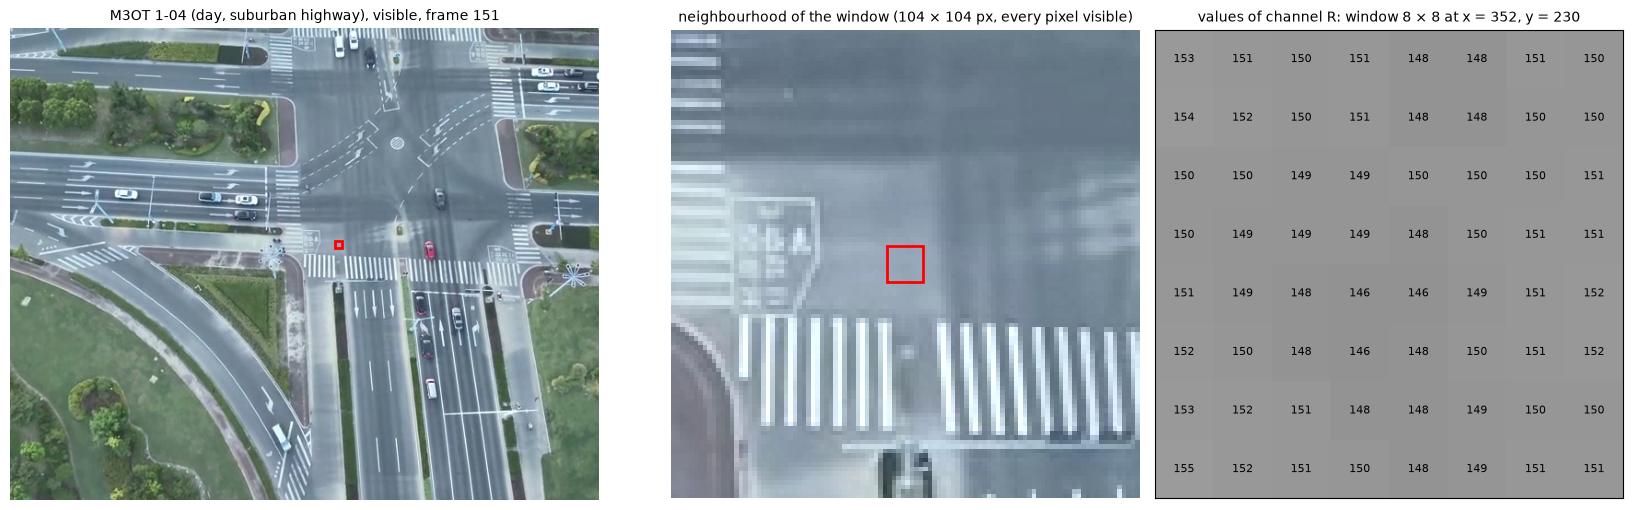

,Value
Property,
"shape of the array (H, W, C)","(512, 640, 3)"
data type; bytes per value b,uint8; 1
informative channels C,3
range of values,9 … 255
"size of the frame S (1), MB",0.98
video of 10 s at 30 frames/s: array T × H × W × C,300 × 512 × 640 × 3
"size of this uncompressed fragment, MB",295
"data rate of the uncompressed stream R0 (2), Mbit/s",235.9
"batch of 16 frames for PyTorch, N × C × H × W",16 × 3 × 512 × 640 (a grey frame is repeated i...


In [4]:
#@title 2.1.1-A A frame is an array [auto] { run: "auto", display-mode: "form" }
SOURCE = "M3OT: visible, day" #@param ["VisDrone: visible, oblique view over a city", "M3OT: visible, day", "M3OT: visible, dusk and night", "M3OT: thermal (black-hot)", "Kust4K: visible", "Kust4K: thermal (colour palette)", "HIT-UAV: thermal (white-hot)", "GOOSE: ground vehicle, front camera", "own frame (block 0.3)"]
FRAME_NUMBER = 1 #@param {type:"slider", min:1, max:8, step:1}
WINDOW_X = 0.55 #@param {type:"slider", min:0, max:1, step:0.01}
WINDOW_Y = 0.45 #@param {type:"slider", min:0, max:1, step:0.01}
WINDOW_PX = 8 #@param {type:"slider", min:4, max:12, step:1}
CHANNEL = "R" #@param ["R", "G", "B", "grey"]
VIDEO_SECONDS = 10 #@param {type:"slider", min:1, max:60, step:1}
FPS = 30 #@param {type:"slider", min:1, max:60, step:1}

fr = load_frame(SOURCE, FRAME_NUMBER)
img = fr["img"]
H, W = img.shape[:2]
n = int(WINDOW_PX)
x0 = int(np.clip(WINDOW_X * W, 0, W - n))
y0 = int(np.clip(WINDOW_Y * H, 0, H - n))
plane = aitbc.gray(img) if CHANNEL == "grey" else img[..., "RGB".index(CHANNEL)]
win = plane[y0:y0 + n, x0:x0 + n]

fig, ax = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw=dict(width_ratios=[1.5, 1, 1]))
ax[0].imshow(img)
ax[0].add_patch(plt.Rectangle((x0, y0), n, n, fill=False, ec="red", lw=2))
ax[0].set_title(fr["caption"], fontsize=10)
ax[0].axis("off")
pad = 6 * n
cx0, cy0 = max(0, x0 - pad), max(0, y0 - pad)
crop = img[cy0:y0 + n + pad, cx0:x0 + n + pad]
ax[1].imshow(crop, interpolation="nearest")
ax[1].add_patch(plt.Rectangle((x0 - cx0 - 0.5, y0 - cy0 - 0.5), n, n, fill=False, ec="red", lw=2))
ax[1].set_title(f"neighbourhood of the window ({crop.shape[1]} × {crop.shape[0]} px, every pixel visible)", fontsize=10)
ax[1].axis("off")
ax[2].imshow(win, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
for (i, j), v in np.ndenumerate(win):
    ax[2].text(j, i, str(v), ha="center", va="center", fontsize=8 if n <= 8 else 6, color="black" if v > 127 else "yellow")
ax[2].set_title(f"values of channel {CHANNEL}: window {n} × {n} at x = {x0}, y = {y0}", fontsize=10)
ax[2].set_xticks([])
ax[2].set_yticks([])
plt.tight_layout()
plt.show()

equal_channels = img.ndim == 3 and np.array_equal(img[..., 0], img[..., 1]) and np.array_equal(img[..., 1], img[..., 2])
C = 1 if (img.ndim == 2 or equal_channels) else img.shape[2]
S_frame = H * W * C * img.dtype.itemsize                                  # formula (1)
R0 = 8 * S_frame * FPS                                                     # formula (2)
g = aitbc.gray(img).astype(np.int16)
rng = np.random.default_rng(0)
ya, xa = rng.integers(0, H, 20000), rng.integers(0, W, 20000)
yb, xb = rng.integers(0, H, 20000), rng.integers(0, W, 20000)
rows = [("shape of the array (H, W, C)", str(img.shape)),
        ("data type; bytes per value b", f"{img.dtype}; {img.dtype.itemsize}"),
        ("informative channels C", f"{C}" + (" (three equal channels of a grey image)" if equal_channels else "")),
        ("range of values", f"{img.min()} … {img.max()}"),
        ("size of the frame S (1), MB", f"{S_frame / 1e6:.2f}"),
        (f"video of {VIDEO_SECONDS} s at {FPS} frames/s: array T × H × W × C", f"{VIDEO_SECONDS * FPS} × {H} × {W} × {C}"),
        ("size of this uncompressed fragment, MB", f"{S_frame * FPS * VIDEO_SECONDS / 1e6:.0f}"),
        ("data rate of the uncompressed stream R0 (2), Mbit/s", f"{R0 / 1e6:.1f}"),
        ("batch of 16 frames for PyTorch, N × C × H × W", f"16 × {3 if C == 1 else C} × {H} × {W} (a grey frame is repeated in 3 channels for RGB networks)"),
        ("mean |difference| of horizontal neighbours, grey levels", f"{np.abs(np.diff(g, axis=1)).mean():.1f}"),
        ("mean |difference| of random pixel pairs, grey levels", f"{np.abs(g[ya, xa] - g[yb, xb]).mean():.1f}")]
if SOURCE.startswith("Kust4K"):
    p = kust.pair(KUST_PAIRS[(FRAME_NUMBER - 1) % 8])
    stack = np.dstack([p["rgb"], p["tir_gray"]])
    rows.append(("multimodal tensor of the pair (R, G, B, thermal)", f"{stack.shape}, {stack.nbytes / 1e6:.2f} MB"))
display(pd.DataFrame(rows, columns=["Property", "Value"]).set_index("Property"))

### Block 2.1.1-B. Quantisation of the brightness: number of bits per value [auto]

**Purpose.** To show how the number of bits k per value limits the number of brightness levels to 2<sup>k</sup> and what is lost when the levels are reduced, in visible and in thermal frames.

Quantisation with k bits replaces a value x (0…255) by the centre of its interval of the width Δ = 256 / 2<sup>k</sup>:

$$q(x) = \Delta \left\lfloor x / \Delta \right\rfloor + \Delta / 2. \tag{3}$$

When the values are distributed evenly inside each interval, the quantisation error has the variance Δ²/12, which gives the peak signal-to-noise ratio

$$\mathrm{PSNR}_q \approx 6.02\,k + 10.8 \ \text{dB}. \tag{4}$$

**Parameters.**
- `FRAME` — visible frame by day or at night (M3OT), thermal frame (HIT-UAV, white-hot; M3OT, black-hot) or the own frame.
- `BITS` — number of bits per value k (8 = original frame).

**What to observe.** The measured PSNR follows (4) for all frames: it depends on the width of the interval Δ only. The structural loss differs. The thermal frame of HIT-UAV is a single channel with smooth transitions of brightness: at 4 bits it keeps 15 grey levels, the smooth transitions become steps (false contours), and its SSIM is the lowest. In a colour frame the three channels are quantised separately, their combination keeps many more grey levels, and the texture of the scene masks the steps. Thermal cameras digitise the signal of the sensor with 14 bits (16 384 levels), because the differences of temperature in a scene are small, and their automatic gain control maps the occupied part of this range to the 8 bits of the video.

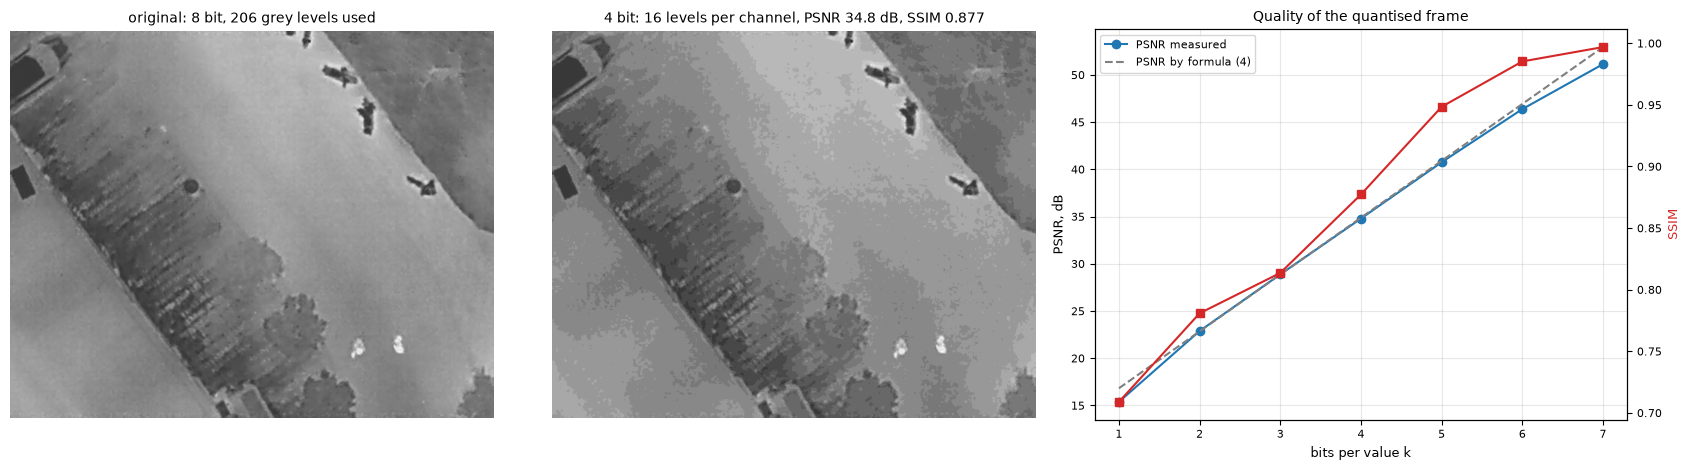

,levels,PSNR_dB,formula_4_dB,SSIM,grey_levels_used
bits,,,,,
1,2,15.378,16.82,0.709,2
2,4,22.882,22.84,0.781,4
3,8,28.877,28.86,0.814,8
4,16,34.787,34.88,0.877,15
5,32,40.748,40.90,0.948,29
6,64,46.373,46.92,0.985,55
7,128,51.134,52.94,0.997,106
8,256,inf,58.96,1.000,206


In [5]:
#@title 2.1.1-B Quantisation of the brightness [auto] { run: "auto", display-mode: "form" }
FRAME = "HIT-UAV: thermal, night (70 m, vertical view)" #@param ["M3OT: visible, day (1-04)", "M3OT: visible, night (1-02)", "HIT-UAV: thermal, night (70 m, vertical view)", "M3OT: thermal, night (1-02)", "own frame (block 0.3)"]
BITS = 4 #@param {type:"slider", min:1, max:8, step:1}

if FRAME.startswith("M3OT: visible, day"):
    img = m3ot.frames("1-04", "rgb", start=150, count=1)[0]
elif FRAME.startswith("M3OT: visible, night"):
    img = m3ot.frames("1-02", "rgb", start=679, count=1)[0]
elif FRAME.startswith("HIT-UAV"):
    img = aitbc.to_rgb(hit.load(hit.EXAMPLES[2])[0])
elif FRAME.startswith("M3OT: thermal"):
    img = m3ot.frames("1-02", "ir", start=679, count=1)[0]
else:
    img = load_frame("own", 1)["img"]

q = aitbc.quantize(img, BITS)                                             # formula (3)
rows = []
for k in range(1, 9):
    qk = aitbc.quantize(img, k)
    rows.append(dict(bits=k, levels=2 ** k, PSNR_dB=aitbc.psnr(img, qk), formula_4_dB=6.02 * k + 10.8,
                     SSIM=aitbc.ssim(img, qk), grey_levels_used=len(np.unique(aitbc.gray(qk)))))
tab = pd.DataFrame(rows).set_index("bits")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw=dict(width_ratios=[1, 1, 1.1]))
ax[0].imshow(img)
ax[0].set_title(f"original: 8 bit, {len(np.unique(aitbc.gray(img)))} grey levels used", fontsize=10)
ax[1].imshow(q)
ax[1].set_title(f"{BITS} bit: {2 ** BITS} levels per channel, PSNR {tab.PSNR_dB[BITS]:.1f} dB, SSIM {tab.SSIM[BITS]:.3f}", fontsize=10)
for a in ax[:2]:
    a.axis("off")
k_ = tab.index[tab.index < 8]
ax[2].plot(k_, tab.PSNR_dB[k_], "o-", label="PSNR measured")
ax[2].plot(k_, tab.formula_4_dB[k_], "--", color="gray", label="PSNR by formula (4)")
ax[2].set_xlabel("bits per value k")
ax[2].set_ylabel("PSNR, dB")
ax[2].grid(alpha=0.3)
a2 = ax[2].twinx()
a2.plot(k_, tab.SSIM[k_], "s-", color="C3", label="SSIM")
a2.set_ylabel("SSIM", color="C3")
ax[2].legend(loc="upper left")
ax[2].set_title("Quality of the quantised frame", fontsize=10)
plt.tight_layout()
plt.show()
display(tab.round(3))

### Block 2.1.2-A. Colour models RGB, HSV and grey on labelled real frames [auto]

**Purpose.** To compare the colour models on a typical task of the video systems of UAVs and UGVs: separation of a class of surfaces by thresholds. The result of a threshold rule is compared with the pixel labels made by the authors of the data sets.

**Colour models.**
- **RGB** — intensities of the red, green and blue channels of the sensor; a change of illumination changes all three.
- **HSV** — hue H (angle 0…360°: red 0°, yellow 60°, green 120°, blue 240°), saturation S (0 = grey) and value V (brightness). The colour (H, S) is separated from the brightness (V), therefore a rule on H and S is less sensitive to shadows. OpenCV stores the hue of 8-bit images as H / 2 (0…179); the course library converts it to degrees.
- **Grey** — one channel, the luma $Y = 0.299R + 0.587G + 0.114B$; it is three times smaller and is used by most classical detectors of edges and features; the colour is lost.

**Parameters.**
- `TARGET` — trees in the UAV frames of Kust4K (hue range), road surface in Kust4K (low saturation), vegetation in the frames of the ground vehicle of GOOSE (hue range), sky in GOOSE (blue hue).
- `FRAME_NUMBER` — frame of the target; the Kust4K frames alternate day and night, the GOOSE frames cover summer, March, December and rain.
- `USE_PRESET` — thresholds of the course for the target; when it is off, the sliders `H_MIN` … `V_MAX` are used.
- `ALL_FRAMES` — the rule is applied to all eight frames of the target.

**Measures.** IoU (intersection over union) of the mask of the rule and of the labelled mask, precision (share of the mask of the rule that is correct) and recall (share of the labelled pixels found). For comparison, two rules on the grey level are evaluated: the best single interval of grey levels for all eight frames of the target, chosen on their labels (the grey counterpart of a fixed HSV rule), and the best interval for this frame alone, chosen on its own labels (an upper bound that no grey threshold can exceed on this frame).

**What to observe.** The feature that separates a class depends on the class and on the scene. Trees of the day frames of Kust4K are found by the hue range with IoU 0.45–0.77, the fixed grey interval reaches 0.18–0.35, and no grey interval exceeds 0.38 even when it is chosen on the labels of the frame: the information is in the colour. The low saturation finds the asphalt better than the fixed grey interval in three of the four day frames; in the pair 00355D (low sun) the asphalt has a blue cast (hue about 210°, saturation about 45) and the rule fails. At night the hue and the saturation of the dark pixels are not reliable and the colour rules fail — the thermal channel takes over (Notebook 01). In the frames of the ground vehicle (GOOSE) the vegetation is darker than the road and the sky: the fixed grey interval finds it better than the hue range in seven of the eight frames, and the hue fails in March and December, when the vegetation is not green. The blue hue finds a clear sky but not an overcast sky, which has no hue (S ≈ 0). Colour thresholds are simple and fast, but depend on season, illumination and camera; segmentation learned from data (Topic 5) is used when the conditions change.

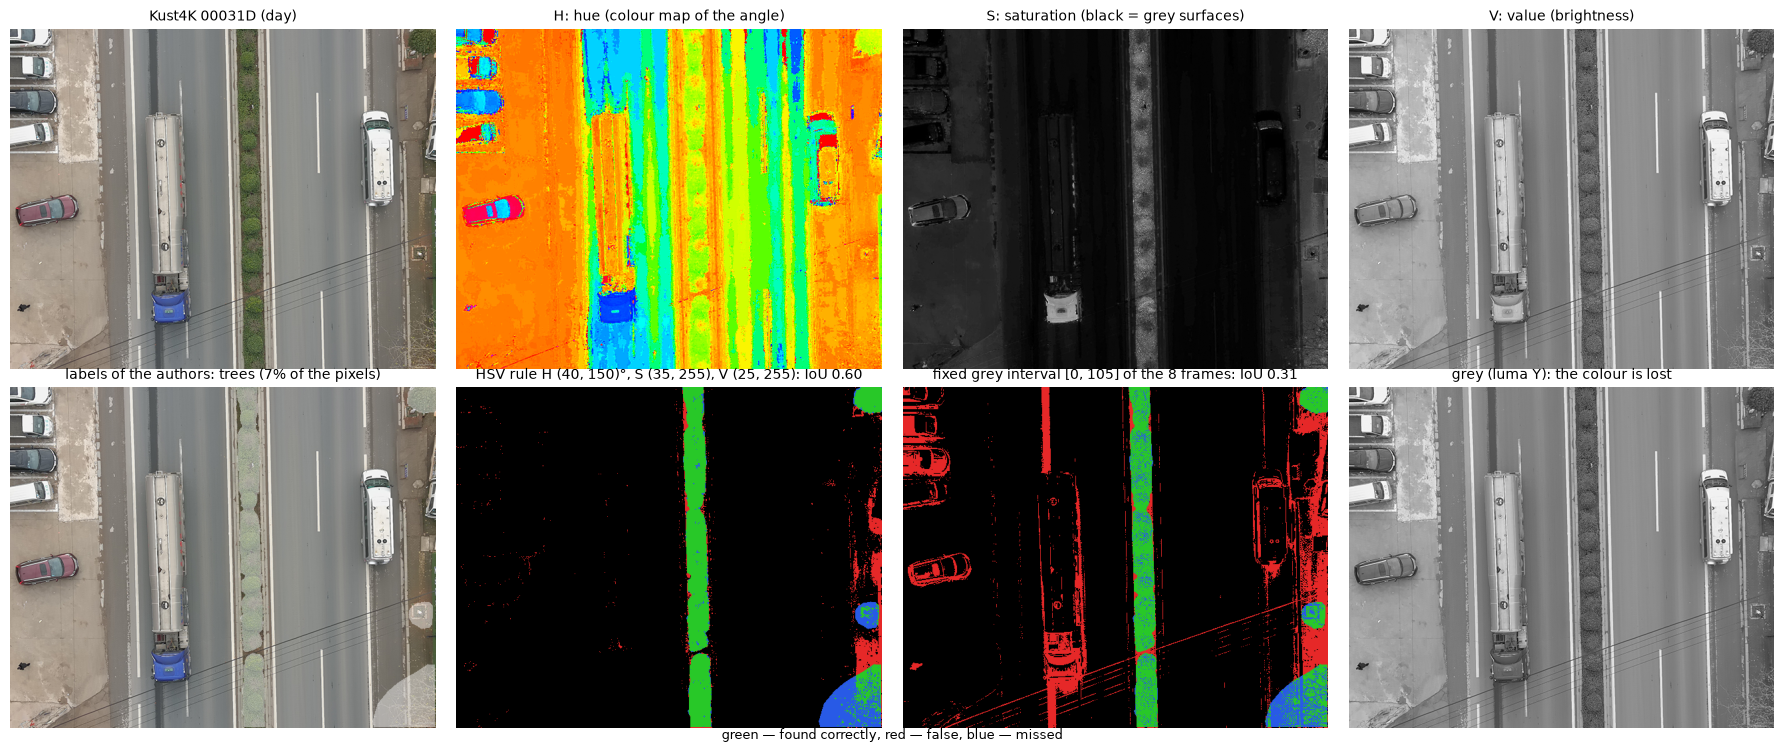

,iou,precision,recall
rule,,,
"HSV, fixed thresholds of the course",0.596,0.743,0.752
"grey interval [0, 105], best for the 8 frames of the target",0.314,0.355,0.731
"grey interval [38, 102], best for this frame (upper bound)",0.322,0.380,0.679


In [6]:
#@title 2.1.2-A Colour models on labelled real frames [auto] { run: "auto", display-mode: "form" }
TARGET = "trees — Kust4K, UAV (hue range)" #@param ["trees — Kust4K, UAV (hue range)", "road surface — Kust4K, UAV (low saturation)", "vegetation — GOOSE, UGV (hue range)", "sky — GOOSE, UGV (blue hue)"]
FRAME_NUMBER = 1 #@param {type:"slider", min:1, max:8, step:1}
USE_PRESET = True #@param {type:"boolean"}
H_MIN = 40 #@param {type:"slider", min:0, max:360, step:5}
H_MAX = 150 #@param {type:"slider", min:0, max:360, step:5}
S_MIN = 35 #@param {type:"slider", min:0, max:255, step:5}
S_MAX = 255 #@param {type:"slider", min:0, max:255, step:5}
V_MIN = 25 #@param {type:"slider", min:0, max:255, step:5}
V_MAX = 255 #@param {type:"slider", min:0, max:255, step:5}
ALL_FRAMES = False #@param {type:"boolean"}

KEY = TARGET.split(" ")[0]
PRESETS = {"trees": dict(h=(40, 150), s=(35, 255), v=(25, 255)), "road": dict(h=(0, 360), s=(0, 30), v=(30, 255)),
           "vegetation": dict(h=(35, 100), s=(30, 255), v=(30, 255)), "sky": dict(h=(180, 260), s=(30, 255), v=(100, 255))}
RULE = PRESETS[KEY] if USE_PRESET else dict(h=(H_MIN, H_MAX), s=(S_MIN, S_MAX), v=(V_MIN, V_MAX))
TREE_PAIRS = ("00031D", "02807N", "00580D", "02921N", "00355D", "04004N", "02094D", "03685N")


def target_frame(n):
    # frame, labelled mask of the target and mask of the valid pixels
    if KEY in ("trees", "road"):
        p = kust.pair((TREE_PAIRS if KEY == "trees" else KUST_PAIRS)[(n - 1) % 8])
        truth = p["labels"] == (6 if KEY == "trees" else 1)
        return p["rgb"], truth, np.ones_like(truth), f"Kust4K {p['id']} ({'night' if p['night'] else 'day'})"
    name = GOOSE_FRAMES[(n - 1) % 8]
    img, lab = goose.load(name, scale=0.5)
    if KEY == "vegetation":
        truth = np.isin(lab, [goose.id_of[c] for c in VEG_CLASSES])
        valid = goose.traversability(lab) > 0                         # sky and own vehicle ignored
    else:
        truth = lab == goose.id_of["sky"]
        valid = lab != goose.id_of["ego_vehicle"]
    return img, truth, valid, f"GOOSE {name.split('/')[2]}"


def best_interval_from_histograms(ht, hn):
    # interval [lo, hi] of grey levels with the largest IoU for the histograms of the target (ht) and of the rest (hn)
    ct, cn = np.r_[0, np.cumsum(ht)], np.r_[0, np.cumsum(hn)]
    best = (0.0, 0, 255)
    for lo in range(0, 256, 2):
        hi = np.arange(lo, 256)
        tp = ct[hi + 1] - ct[lo]
        iou = tp / np.maximum(tp + (cn[hi + 1] - cn[lo]) + (ct[-1] - tp), 1)
        j = int(np.argmax(iou))
        if iou[j] > best[0]:
            best = (float(iou[j]), lo, int(hi[j]))
    return best


def grey_histograms(grey, truth, valid):
    return (np.bincount(grey[truth & valid], minlength=256).astype(float),
            np.bincount(grey[~truth & valid], minlength=256).astype(float))


def best_grey_interval(grey, truth, valid):
    # best interval for this frame alone, chosen on its labels (upper bound of grey thresholds)
    return best_interval_from_histograms(*grey_histograms(grey, truth, valid))


if "FIXED_GREY" not in globals():
    FIXED_GREY = {}
if KEY not in FIXED_GREY:                                                # best single interval for the 8 frames
    ht_, hn_ = np.zeros(256), np.zeros(256)
    for n_ in range(1, 9):
        im_, tr_, va_, _ = target_frame(n_)
        a_, b_ = grey_histograms(cv2.cvtColor(im_, cv2.COLOR_RGB2GRAY), tr_, va_)
        ht_ += a_
        hn_ += b_
    FIXED_GREY[KEY] = best_interval_from_histograms(ht_, hn_)[1:]


def error_map(pred, truth, valid):
    out = np.zeros(pred.shape + (3,), np.uint8)
    out[pred & truth & valid] = (40, 200, 40)                            # found correctly
    out[pred & ~truth & valid] = (230, 40, 40)                           # false
    out[~pred & truth & valid] = (40, 90, 230)                           # missed
    return out


img, truth, valid, caption = target_frame(FRAME_NUMBER)
grey = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
pred = aitbc.hsv_mask(img, **RULE)
s_hsv = aitbc.mask_scores(pred, truth, valid)
f_lo, f_hi = FIXED_GREY[KEY]
pred_f = (grey >= f_lo) & (grey <= f_hi)
s_fixed = aitbc.mask_scores(pred_f, truth, valid)
g_iou, g_lo, g_hi = best_grey_interval(grey, truth, valid)
s_grey = aitbc.mask_scores((grey >= g_lo) & (grey <= g_hi), truth, valid)

fig, ax = plt.subplots(2, 4, figsize=(18, 7.4))
ax[0, 0].imshow(img)
ax[0, 0].set_title(caption, fontsize=10)
ax[0, 1].imshow(hsv[..., 0], cmap="hsv", vmin=0, vmax=179)
ax[0, 1].set_title("H: hue (colour map of the angle)", fontsize=10)
ax[0, 2].imshow(hsv[..., 1], cmap="gray", vmin=0, vmax=255)
ax[0, 2].set_title("S: saturation (black = grey surfaces)", fontsize=10)
ax[0, 3].imshow(hsv[..., 2], cmap="gray", vmin=0, vmax=255)
ax[0, 3].set_title("V: value (brightness)", fontsize=10)
ax[1, 0].imshow(aitbc.overlay(img, np.dstack([truth * 255] * 3).astype(np.uint8), 0.45, truth))
ax[1, 0].set_title(f"labels of the authors: {KEY} ({truth[valid].mean():.0%} of the pixels)", fontsize=10)
ax[1, 1].imshow(error_map(pred, truth, valid))
ax[1, 1].set_title(f"HSV rule H {RULE['h']}°, S {RULE['s']}, V {RULE['v']}: IoU {s_hsv['iou']:.2f}", fontsize=10)
ax[1, 2].imshow(error_map(pred_f, truth, valid))
ax[1, 2].set_title(f"fixed grey interval [{f_lo}, {f_hi}] of the 8 frames: IoU {s_fixed['iou']:.2f}", fontsize=10)
ax[1, 3].imshow(grey, cmap="gray", vmin=0, vmax=255)
ax[1, 3].set_title("grey (luma Y): the colour is lost", fontsize=10)
for a in ax.ravel():
    a.axis("off")
fig.text(0.5, 0.005, "green — found correctly, red — false, blue — missed", ha="center", fontsize=9)
plt.tight_layout()
plt.show()
pd.set_option("display.max_colwidth", 100)
display(pd.DataFrame([dict(rule=f"HSV, fixed thresholds of {'the course' if USE_PRESET else 'the sliders'}", **s_hsv),
                      dict(rule=f"grey interval [{f_lo}, {f_hi}], best for the 8 frames of the target", **s_fixed),
                      dict(rule=f"grey interval [{g_lo}, {g_hi}], best for this frame (upper bound)", **s_grey)]).set_index("rule").round(3))

if ALL_FRAMES:
    rows = []
    for n_ in range(1, 9):
        im_, tr_, va_, cap_ = target_frame(n_)
        if tr_[va_].sum() < 500:
            rows.append(dict(frame=cap_, target_share=float(tr_[va_].mean()), IoU_HSV=np.nan, IoU_fixed_grey=np.nan,
                             IoU_best_grey_of_frame=np.nan))
            continue
        gr_ = cv2.cvtColor(im_, cv2.COLOR_RGB2GRAY)
        rows.append(dict(frame=cap_, target_share=float(tr_[va_].mean()),
                         IoU_HSV=aitbc.mask_scores(aitbc.hsv_mask(im_, **RULE), tr_, va_)["iou"],
                         IoU_fixed_grey=aitbc.mask_scores((gr_ >= f_lo) & (gr_ <= f_hi), tr_, va_)["iou"],
                         IoU_best_grey_of_frame=best_grey_interval(gr_, tr_, va_)[0]))
    tab = pd.DataFrame(rows).set_index("frame")
    display(tab.round(2))
    if KEY in ("trees", "road"):
        night_ = tab.index.str.contains("night")
        print(f"Median IoU of the HSV rule: day {tab.IoU_HSV[~night_].median():.2f}, night {tab.IoU_HSV[night_].median():.2f}; "
              f"fixed grey interval: day {tab.IoU_fixed_grey[~night_].median():.2f}, night {tab.IoU_fixed_grey[night_].median():.2f}")
    else:
        print(f"Frames where the HSV rule is better than the fixed grey interval: "
              f"{int((tab.IoU_HSV > tab.IoU_fixed_grey).sum())} of {int(tab.IoU_HSV.notna().sum())}")

### Block 2.1.3-A. Formation of the frame of an FPV drone: wide-angle lens and motion of the platform [auto]

**Purpose.** To follow a real frame through the first stages of the formation of an FPV video frame and to see what the optical system and the dynamics of the platform add to it. The stages are modelled on a real frame of a narrow-angle camera; they are not recorded effects.

**Stages.**
1. **Wide-angle lens.** FPV cameras use lenses with a horizontal field of view of 120–170°. Their barrel distortion bends straight lines outwards from the centre, the vignetting darkens the corners. The model of the library magnifies the centre by 1 + b and keeps the corners in place (parameter `BARREL` = b); the brightness is multiplied by 1 − v r² (`VIGNETTING` = v).
2. **Motion during the exposure.** A turn of the drone with the angular rate ω (deg/s) during the exposure time t<sub>e</sub> smears the frame by

$$b_\omega = \omega \, t_e \, \frac{W}{\alpha} \tag{5}$$

pixels, where W is the width of the frame, px, and α the horizontal field of view, deg (W / α pixels per degree in the centre of the frame).

3. **Rolling shutter.** A CMOS sensor reads its rows one after another during the readout time t<sub>r</sub>. During a turn the lower rows are read later than the upper ones, and vertical lines lean by

$$\Delta x = \omega \, t_r \, \frac{W}{\alpha} \tag{6}$$

pixels between the top and the bottom of the frame. The vibration of the motors with the frequency f<sub>v</sub> gives f<sub>v</sub> t<sub>r</sub> waves of horizontal wobble ("jello") over the height of the frame.

**Parameters.** `SOURCE`, `FRAME_NUMBER` — real frame; `HFOV_DEG` — field of view α; `BARREL`, `VIGNETTING` — lens; `EXPOSURE_MS` — t<sub>e</sub>; `ANGULAR_RATE_DPS` — ω; `READOUT_MS` — t<sub>r</sub>; `VIBRATION_PX`, `VIBRATION_HZ` — amplitude and frequency of the vibration; `SHOW_GRID` — a grid of straight lines drawn on the frame before the lens.

**What to observe.** The lines of the grid bend near the edges: the scale of the frame is not constant, and the measurements of size and position in a wide-angle frame need a calibrated camera model and the correction of the distortion (function `cv2.undistort` of OpenCV). With the default parameters (ω = 300 °/s, t<sub>e</sub> = 8 ms) the blur (5) is about 22 px for a frame of 1360 px and 150°: small objects disappear. The skew (6) and the jello change the geometry of the frame without blur; they are reduced by the vibration dampers of the camera mount, short readout times and electronic stabilisation (Lesson 3.4).

In [7]:
#@title 2.1.3-A FPV frame: wide-angle lens and motion of the platform [auto] { run: "auto", display-mode: "form" }
SOURCE = "VisDrone: visible, oblique view over a city" #@param ["VisDrone: visible, oblique view over a city", "GOOSE: ground vehicle, front camera", "HIT-UAV: thermal (white-hot)", "own frame (block 0.3)"]
FRAME_NUMBER = 3 #@param {type:"slider", min:1, max:8, step:1}
HFOV_DEG = 150 #@param {type:"slider", min:60, max:170, step:5}
BARREL = 0.3 #@param {type:"slider", min:0, max:0.8, step:0.05}
VIGNETTING = 0.4 #@param {type:"slider", min:0, max:0.9, step:0.05}
EXPOSURE_MS = 8.0 #@param {type:"slider", min:0.5, max:33, step:0.5}
ANGULAR_RATE_DPS = 300 #@param {type:"slider", min:0, max:1000, step:10}
READOUT_MS = 15 #@param {type:"slider", min:0, max:33, step:1}
VIBRATION_PX = 3.0 #@param {type:"slider", min:0, max:20, step:0.5}
VIBRATION_HZ = 120 #@param {type:"slider", min:10, max:300, step:10}
SHOW_GRID = True #@param {type:"boolean"}

fr = load_frame(SOURCE, FRAME_NUMBER)
ideal = fr["img"].copy()
H, W = ideal.shape[:2]
if SHOW_GRID:
    for x in np.linspace(0, W - 1, 9).astype(int):
        cv2.line(ideal, (x, 0), (x, H - 1), (255, 255, 255), 1)
    for y in np.linspace(0, H - 1, 7).astype(int):
        cv2.line(ideal, (0, y), (W - 1, y), (255, 255, 255), 1)

px_per_deg = W / HFOV_DEG
blur_px = ANGULAR_RATE_DPS * EXPOSURE_MS / 1000 * px_per_deg              # formula (5)
skew_px = ANGULAR_RATE_DPS * READOUT_MS / 1000 * px_per_deg               # formula (6)
waves = VIBRATION_HZ * READOUT_MS / 1000

lens = aitbc.wide_angle_lens(ideal, barrel=BARREL, vignetting=VIGNETTING)
blurred = aitbc.motion_blur(lens, length=blur_px, angle=0.0) if blur_px >= 1 else lens.copy()
shear = np.float32([[1, skew_px / H, -skew_px / 2], [0, 1, 0]])
rolled = cv2.warpAffine(blurred, shear, (W, H), borderMode=cv2.BORDER_REFLECT)
if VIBRATION_PX > 0 and waves > 0:
    rolled = aitbc.rolling_shutter(rolled, amplitude=VIBRATION_PX, cycles=waves)

stages = [("1. frame of a narrow-angle camera (real)", ideal), (f"2. wide-angle lens: {HFOV_DEG}°, barrel {BARREL}, vignetting {VIGNETTING}", lens),
          (f"3. + blur of the turn (5): {blur_px:.1f} px", blurred), (f"4. + rolling shutter (6): skew {skew_px:.0f} px, {waves:.1f} waves of jello", rolled)]
fig, ax = plt.subplots(2, 2, figsize=(16, 16 * H / W + 1.6))
for a, (t_, im_) in zip(ax.ravel(), stages):
    a.imshow(im_)
    a.set_title(t_, fontsize=10)
    a.axis("off")
plt.suptitle(fr["caption"], fontsize=11)
plt.tight_layout()
plt.show()
rows = [("pixels per degree in the centre W / α", f"{px_per_deg:.1f}"),
        ("blur of the turn b_ω (5), px", f"{blur_px:.1f}"),
        ("skew of the rolling shutter Δx (6), px", f"{skew_px:.1f}"),
        ("waves of the vibration over the frame f_v t_r", f"{waves:.2f}"),
        ("sharpness: real frame → lens → blur → rolling shutter",
         " → ".join(f"{aitbc.sharpness(im_):.0f}" for _, im_ in stages)),
        ("SSIM of every stage to the previous stage", " / ".join(f"{aitbc.ssim(stages[i][1], stages[i + 1][1]):.3f}" for i in range(3)))]
display(pd.DataFrame(rows, columns=["Quantity", "Value"]).set_index("Quantity"))

*[Figure omitted in the public copy of the repository. It shows frames of the VisDrone2019-DET data set (Zhu P. et al., IEEE TPAMI 44(11), 2022), which is distributed for non-commercial use and is therefore not redistributed here. Run the cell in Google Colab to obtain the figure.]*

,Value
Quantity,
pixels per degree in the centre W / α,9.1
"blur of the turn b_ω (5), px",21.8
"skew of the rolling shutter Δx (6), px",40.8
waves of the vibration over the frame f_v t_r,1.80
sharpness: real frame → lens → blur → rolling shutter,4086 → 1018 → 162 → 162
SSIM of every stage to the previous stage,0.550 / 0.859 / 0.911


### Block 2.1.3-B. Formation of the frame of an FPV drone: the radio channel [auto]

**Purpose.** To estimate the quality of the received video for a given radio link: transmitter power, antennas, distance, additional losses and interference (jamming), and to compare an analog and a digital video link.

**Link budget in free space.** The path loss at the distance d, km, and the frequency f, MHz, is

$$L_{fs} = 20 \lg d + 20 \lg f + 32.44 \ \text{dB}. \tag{7}$$

The received power, dBm, is

$$P_{rx} = P_{tx} + G_{tx} + G_{rx} - L_{fs} - L_{add}, \tag{8}$$

where $P_{tx}$ is the power of the transmitter, dBm ($10 \lg$ of the power in mW), $G$ are the gains of the antennas, dBi, and $L_{add}$ are additional losses (terrain, vegetation, body of the drone, polarisation). The power of the thermal noise in the band B, Hz, of a receiver with the noise figure NF, dB, is

$$N = -174 + 10 \lg B + NF \ \text{dBm}, \tag{9}$$

and interference (jamming) raises it by `INTERFERENCE_DB`. The carrier-to-noise ratio is

$$\mathrm{CNR} = P_{rx} - N \ \text{dB}. \tag{10}$$

The CNR falls by 6 dB for every doubling of the distance; 20 dB of additional loss or interference reduce the range ten times.

**From the CNR to the frame (illustrative model of the course).** *Analog FM video* (720 × 576, 25 frames/s): above the FM threshold (10 dB) the picture has weak noise with SNR = CNR + 25 dB; below the threshold impulse noise ("sparkles"), loss of colour and torn lines appear and grow; 6 dB below the threshold the picture is lost. *Digital video* (1280 × 720): the frame is compressed to the bit rate of the link (shown by the JPEG quality whose file fits into the budget of one frame; the codecs of digital links use also the similarity of neighbouring frames and reach the same quality at a lower bit rate); near the sensitivity of the receiver (8 dB) the share of lost packets grows from 0.1 % to 50 % within about 3 dB (cliff effect), and the lost blocks of the frame are filled with errors. The threshold values are typical, not values of a specific product.

**Parameters.** `SOURCE`, `FRAME_NUMBER` — real frame; `LINK` — analog or digital; `TX_POWER_MW`, `ANTENNA_GAIN_DBI` (each of the two antennas), `DISTANCE_KM`, `EXTRA_LOSS_DB`, `INTERFERENCE_DB`; `BITRATE_MBPS`, `FPS` — bit rate and frame rate of the digital link.

**What to observe.** The analog picture degrades gradually: between the FM threshold and the loss of the picture (6 dB) the distance grows about twice, and a pilot still sees a noisy picture with sparkles. The digital picture keeps its quality (compression artefacts only) almost to the edge of the range and is lost within about 3 dB, that is within about 40 % of the distance. A jamming level of 20 dB above the noise of the receiver reduces the range ten times. The delay of the video link adds to the delays of Lesson 1.1 (block 1.1.4-B of Notebook 01).

In [8]:
#@title 2.1.3-B FPV frame: the radio channel [auto] { run: "auto", display-mode: "form" }
SOURCE = "VisDrone: visible, oblique view over a city" #@param ["VisDrone: visible, oblique view over a city", "GOOSE: ground vehicle, front camera", "HIT-UAV: thermal (white-hot)", "own frame (block 0.3)"]
FRAME_NUMBER = 3 #@param {type:"slider", min:1, max:8, step:1}
LINK = "analog FM video, 5.8 GHz, 720 × 576" #@param ["analog FM video, 5.8 GHz, 720 × 576", "digital video, 5.8 GHz, 1280 × 720"]
TX_POWER_MW = 200 #@param {type:"slider", min:10, max:1000, step:10}
ANTENNA_GAIN_DBI = 2.0 #@param {type:"slider", min:0, max:12, step:0.5}
DISTANCE_KM = 2.2 #@param {type:"slider", min:0.1, max:10, step:0.1}
EXTRA_LOSS_DB = 0 #@param {type:"slider", min:0, max:40, step:1}
INTERFERENCE_DB = 0 #@param {type:"slider", min:0, max:40, step:1}
BITRATE_MBPS = 8 #@param {type:"slider", min:1, max:50, step:1}
FPS = 30 #@param {type:"slider", min:25, max:120, step:5}

ANALOG = LINK.startswith("analog")
SIZE = (720, 576) if ANALOG else (1280, 720)
BAND_MHZ, NF_DB, FREQ_MHZ = 20.0, 6.0, 5800.0
THRESHOLD_DB = 10.0 if ANALOG else 8.0
fr = load_frame(SOURCE, FRAME_NUMBER)
frame = cv2.resize(fr["img"], SIZE, interpolation=cv2.INTER_AREA)
lb = aitbc.link_budget(TX_POWER_MW, DISTANCE_KM * 1000, FREQ_MHZ, ANTENNA_GAIN_DBI, ANTENNA_GAIN_DBI,
                       EXTRA_LOSS_DB, BAND_MHZ, NF_DB, INTERFERENCE_DB)          # formulas (7)-(10)
margin = lb["cnr_db"] - THRESHOLD_DB
# distance at which the CNR equals the threshold: from (7)-(10) with CNR = threshold
d_max_km = 10 ** ((lb["p_tx_dbm"] + 2 * ANTENNA_GAIN_DBI - EXTRA_LOSS_DB - lb["noise_dbm"] - THRESHOLD_DB
                   - 20 * math.log10(FREQ_MHZ) - 32.44) / 20)
rows = [("transmitter power P_tx, dBm", f"{lb['p_tx_dbm']:.1f}"), ("path loss L_fs (7), dB", f"{lb['fspl_db']:.1f}"),
        ("received power P_rx (8), dBm", f"{lb['p_rx_dbm']:.1f}"), ("noise and interference N (9), dBm", f"{lb['noise_dbm']:.1f}"),
        ("carrier-to-noise ratio CNR (10), dB", f"{lb['cnr_db']:.1f}"),
        (f"margin over the {'FM threshold' if ANALOG else 'sensitivity of the receiver'} ({THRESHOLD_DB:.0f} dB), dB", f"{margin:.1f}"),
        ("range at the threshold, km", f"{d_max_km:.2f}")]
if ANALOG:
    rx = aitbc.analog_link_frame(frame, lb["cnr_db"], threshold_db=THRESHOLD_DB, fm_gain_db=25.0, seed=1)
    state = "clean picture with weak noise" if margin > 3 else "near the threshold: noise" if margin > 0 else \
            "below the threshold: sparkles and torn lines" if margin > -6 else "picture lost"
else:
    budget = BITRATE_MBPS * 1e6 / FPS / 8                                     # bytes of one frame
    enc, quality, nbytes = aitbc.jpeg_for_budget(frame, budget)
    plr = aitbc.digital_packet_loss_rate(lb["cnr_db"], THRESHOLD_DB)
    rx = aitbc.packet_loss(enc, rate=plr, block=16, seed=1) if plr < 0.5 else np.full_like(enc, 40)
    state = "clean picture (compression only)" if plr < 0.001 else f"lost packets {plr:.1%}" if plr < 0.5 else "no picture (link lost)"
    rows += [("bits per pixel R / (f W H)", f"{BITRATE_MBPS * 1e6 / (FPS * SIZE[0] * SIZE[1]):.3f}"),
             ("JPEG quality that fits into one frame", f"{quality} ({nbytes / 1024:.0f} KB of {budget / 1024:.0f} KB)"),
             ("share of lost packets (illustrative model)", f"{plr:.2e}")]
rows.append(("state of the picture", state))

d = np.logspace(np.log10(0.05), np.log10(20), 200)
cnr = [aitbc.link_budget(TX_POWER_MW, x * 1000, FREQ_MHZ, ANTENNA_GAIN_DBI, ANTENNA_GAIN_DBI, EXTRA_LOSS_DB,
                         BAND_MHZ, NF_DB, INTERFERENCE_DB)["cnr_db"] for x in d]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw=dict(width_ratios=[1.1, 1, 1]))
ax[0].semilogx(d, cnr)
ax[0].axhline(THRESHOLD_DB, color="C3", ls="--", lw=1, label=f"threshold {THRESHOLD_DB:.0f} dB")
ax[0].plot([DISTANCE_KM], [lb["cnr_db"]], "o", color="k", label=f"d = {DISTANCE_KM} km: CNR {lb['cnr_db']:.1f} dB")
ax[0].set_xlabel("distance, km")
ax[0].set_ylabel("CNR, dB")
ax[0].set_title("Carrier-to-noise ratio against the distance (7)-(10)", fontsize=10)
ax[0].grid(alpha=0.3, which="both")
ax[0].legend(fontsize=8)
ax[1].imshow(frame)
ax[1].set_title(f"frame at the transmitter, {SIZE[0]} × {SIZE[1]}", fontsize=10)
ax[2].imshow(rx)
ax[2].set_title(f"frame at the receiver: {state}", fontsize=10)
for a in ax[1:]:
    a.axis("off")
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows, columns=["Quantity", "Value"]).set_index("Quantity"))

*[Figure omitted in the public copy of the repository. It shows frames of the VisDrone2019-DET data set (Zhu P. et al., IEEE TPAMI 44(11), 2022), which is distributed for non-commercial use and is therefore not redistributed here. Run the cell in Google Colab to obtain the figure.]*

,Value
Quantity,
"transmitter power P_tx, dBm",23.0
"path loss L_fs (7), dB",114.6
"received power P_rx (8), dBm",-87.5
"noise and interference N (9), dBm",-95.0
"carrier-to-noise ratio CNR (10), dB",7.4
"margin over the FM threshold (10 dB), dB",-2.6
"range at the threshold, km",1.64
state of the picture,below the threshold: sparkles and torn lines


### Block 2.1.4-A. Resolution of the frame and processing time (measured in this runtime)

**Purpose.** To measure how the processing time of typical algorithms depends on the resolution of the frame and to check the condition of real-time processing for a required frame rate.

**Computational load.** For an algorithm with c operations per pixel the load of a stream of frames W × H at f frames per second is $L = c \, W H f$ operations per second. Real-time processing requires that all stages of the processing of one frame end before the next frame arrives:

$$t_{frame} = \sum_i t_i(W, H) \le \frac{1}{f}. \tag{11}$$

At 30 frames per second the budget of a frame is 33 ms for all stages together; the utilisation $u = f \, t_{frame}$ must stay below 1 with a margin for the other tasks of the on-board computer.

**Parameters.**
- check boxes of the algorithms: Gaussian filter 5 × 5, median filter 5 × 5, Canny edges, CLAHE, ORB features (up to 1000 points), convolutional neural network MobileNetV3-Small (the processing time of a network does not depend on the values of its weights; untrained weights are used and nothing is downloaded);
- `USE_GPU` — run the network on the GPU, if the runtime has one;
- `REQUIRED_FPS` — required frame rate f; `REPEATS` — repetitions of each measurement (the median is shown).

The frame is a real VisDrone frame 1920 × 1080 resized to the sizes from 320 × 180 to 3840 × 2160 (4K); the size 640 × 512 is the frame of the thermal cameras of the course.

**What to observe.** The time of every operation grows with the number of pixels; a 4K frame has 36 times more pixels than a frame 640 × 360. For large frames the time of the filters grows almost in proportion to the number of pixels (slope about 1 in the logarithmic plot); for small frames fixed costs dominate (start of the threads). The time of ORB grows more slowly, because the number of points is limited to 1000. On a CPU the neural network takes more than half of the time of the pipeline; on a GPU runtime compare its time with the CPU (`USE_GPU`). Reducing the resolution is the first way to reach real time; its price is the loss of small objects (block 2.2.4-A). The times depend on the runtime: a CPU runtime of Colab has two cores, the results of a laptop or of an on-board computer differ.

Measured in 4 s; 16 CPU cores; network on CPU; budget of a frame at 30 frames/s: 33.3 ms


,Mpixel,Gaussian 5×5,median 5×5,Canny,CLAHE 8×8,"ORB, 1000 points",MobileNetV3-Small (CPU),"all stages, ms (11)",frames per second,utilisation u at 30 frames/s,real time
size,,,,,,,,,,,
320 × 180,0.06,0.03,0.40,0.45,1.01,1.88,9.88,13.65,73.23,0.41,yes
640 × 360,0.23,0.08,1.25,0.72,1.50,7.05,13.69,24.28,41.19,0.73,yes
640 × 512,0.33,0.11,1.79,0.85,1.87,8.66,16.72,30.00,33.33,0.90,yes
1280 × 720,0.92,0.89,4.45,1.92,5.05,15.84,46.56,74.72,13.38,2.24,no
1920 × 1080,2.07,2.38,9.00,5.30,12.31,32.85,141.01,202.85,4.93,6.09,no
3840 × 2160,8.29,10.42,32.27,16.34,42.70,76.06,654.11,831.89,1.20,24.96,no


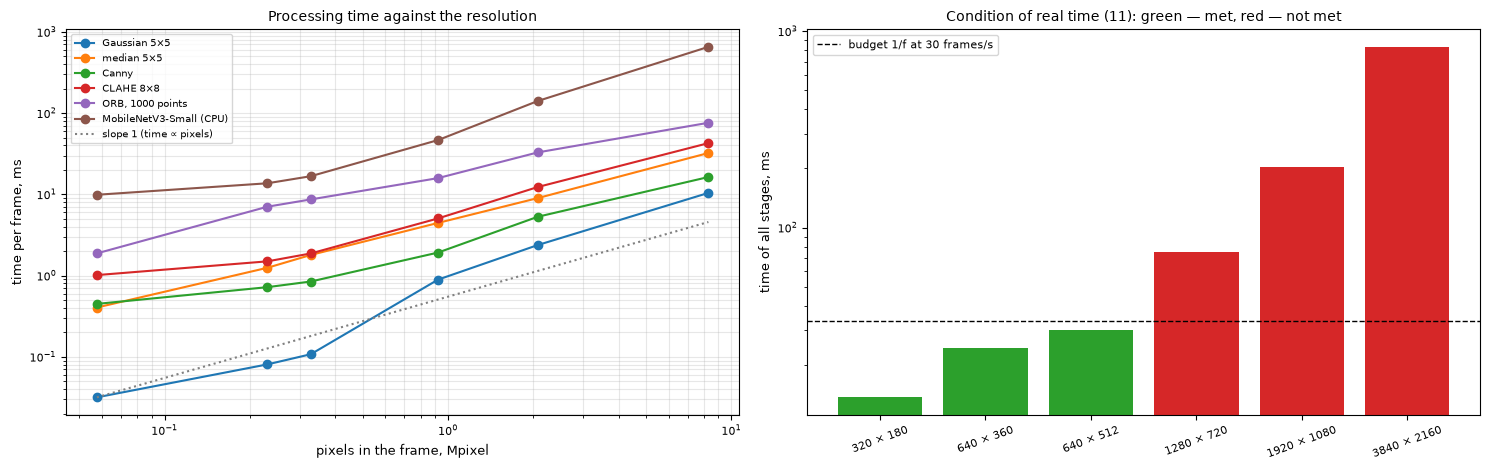

In [9]:
#@title 2.1.4-A Resolution and processing time (measured) { display-mode: "form" }
GAUSSIAN_5x5 = True #@param {type:"boolean"}
MEDIAN_5x5 = True #@param {type:"boolean"}
CANNY_EDGES = True #@param {type:"boolean"}
CLAHE_8x8 = True #@param {type:"boolean"}
ORB_FEATURES = True #@param {type:"boolean"}
CNN_MOBILENET = True #@param {type:"boolean"}
USE_GPU = True #@param {type:"boolean"}
REQUIRED_FPS = 30 #@param {type:"slider", min:5, max:120, step:5}
REPEATS = 3 #@param {type:"slider", min:1, max:10, step:1}

SIZES = [(320, 180), (640, 360), (640, 512), (1280, 720), (1920, 1080), (3840, 2160)]
base = load_frame("VisDrone", 4)["img"]                                    # real frame 1920 x 1080
orb = cv2.ORB_create(nfeatures=1000)
algos = {}
if GAUSSIAN_5x5:
    algos["Gaussian 5×5"] = lambda im, g: cv2.GaussianBlur(im, (5, 5), 0)
if MEDIAN_5x5:
    algos["median 5×5"] = lambda im, g: cv2.medianBlur(im, 5)
if CANNY_EDGES:
    algos["Canny"] = lambda im, g: cv2.Canny(g, 60, 140)
if CLAHE_8x8:
    algos["CLAHE 8×8"] = lambda im, g: aitbc.equalize(im, "clahe", 2.0, 8)
if ORB_FEATURES:
    algos["ORB, 1000 points"] = lambda im, g: orb.detectAndCompute(g, None)
net, dev = None, "cpu"
if CNN_MOBILENET:
    try:
        import torchvision
        dev = "cuda" if (USE_GPU and CUDA_OK) else "cpu"
        net = torchvision.models.mobilenet_v3_small(weights=None).eval().to(dev)
    except Exception as e:
        print("The neural network is skipped:", e)

rows = []
t0 = time.time()
for (w, h) in SIZES:
    im = cv2.resize(base, (w, h), interpolation=cv2.INTER_AREA if w <= base.shape[1] else cv2.INTER_LINEAR)
    g = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
    r_ = {"size": f"{w} × {h}", "Mpixel": w * h / 1e6}
    for name, fn in algos.items():
        r_[name] = aitbc.time_call(lambda: fn(im, g), repeats=REPEATS)
    if net is not None:
        x = torch.from_numpy(aitbc.to_input_tensor(im)).to(dev)

        def run_net():
            with torch.inference_mode():
                net(x)
            if dev == "cuda":
                torch.cuda.synchronize()
        r_[f"MobileNetV3-Small ({dev.upper()})"] = aitbc.time_call(run_net, repeats=max(1, REPEATS - 1))
    rows.append(r_)
tab = pd.DataFrame(rows).set_index("size")
algo_cols = [c for c in tab.columns if c != "Mpixel"]
tab["all stages, ms (11)"] = tab[algo_cols].sum(axis=1)
tab["frames per second"] = 1000 / tab["all stages, ms (11)"]
tab[f"utilisation u at {REQUIRED_FPS} frames/s"] = tab["all stages, ms (11)"] * REQUIRED_FPS / 1000
tab["real time"] = np.where(tab[f"utilisation u at {REQUIRED_FPS} frames/s"] <= 1, "yes", "no")
print(f"Measured in {time.time() - t0:.0f} s; {os.cpu_count()} CPU cores; network on {dev.upper()}; "
      f"budget of a frame at {REQUIRED_FPS} frames/s: {1000 / REQUIRED_FPS:.1f} ms")
display(tab.round(2))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for c in algo_cols:
    ax[0].loglog(tab.Mpixel, tab[c], "o-", label=c)
mp = np.array([tab.Mpixel.min(), tab.Mpixel.max()])
ax[0].loglog(mp, tab[algo_cols[0]].iloc[0] * mp / mp[0], ":", color="gray", label="slope 1 (time ∝ pixels)")
ax[0].set_xlabel("pixels in the frame, Mpixel")
ax[0].set_ylabel("time per frame, ms")
ax[0].set_title("Processing time against the resolution", fontsize=10)
ax[0].grid(alpha=0.3, which="both")
ax[0].legend(fontsize=7)
ax[1].bar(tab.index, tab["all stages, ms (11)"], color=np.where(tab["real time"] == "yes", "C2", "C3"))
ax[1].axhline(1000 / REQUIRED_FPS, color="k", ls="--", lw=1, label=f"budget 1/f at {REQUIRED_FPS} frames/s")
ax[1].set_yscale("log")
ax[1].set_ylabel("time of all stages, ms")
ax[1].set_title("Condition of real time (11): green — met, red — not met", fontsize=10)
ax[1].legend(fontsize=8)
ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### Block 2.1.4-B. Processing rate and motion between the processed frames: annotated vehicles of M3OT [auto]

**Purpose.** To show the second side of the frame rate. When only every N-th frame of a stream of f frames per second is processed (processing rate f / N), the load falls N times, but the objects move further between the processed frames. Many trackers link the detections of neighbouring frames by the overlap of their boxes; this works while a box overlaps with its position in the previous processed frame.

**Overlap of a moving box.** Two equal square boxes of the size a, shifted by d along one axis, have

$$\mathrm{IoU} = \frac{a - d}{a + d}, \qquad \mathrm{IoU} \ge \theta \iff d \le a \, \frac{1 - \theta}{1 + \theta}. \tag{12}$$

For a vehicle of 10 px and θ = 0.3 the displacement must not exceed 5.4 px.

**Data.** The annotation of all frames of an M3OT sequence (10 frames per second; vehicles about 8–12 px from 100–120 m): for every vehicle and every step N the IoU of its boxes in the frames t and t + N and the displacement of its centre are calculated.

**Parameters.** `SEQUENCE` — sequence of M3OT; `CHANNEL` — annotation of the visible or of the thermal sequence; `IOU_THRESHOLD` — θ.

**What to observe.** At 10 frames per second almost every vehicle overlaps with its previous position. At 5 frames per second the share is 0.50–0.97 in the nine sequences (lowest for the fast traffic of 1-03, a city road), at 2 frames per second 0.03–0.70, at 1 frame per second below 0.30 in all sequences. Halving the processing rate halves the load (block 2.1.4-A), but then the tracker needs a prediction of the motion instead of the overlap of the boxes (Topic 5).

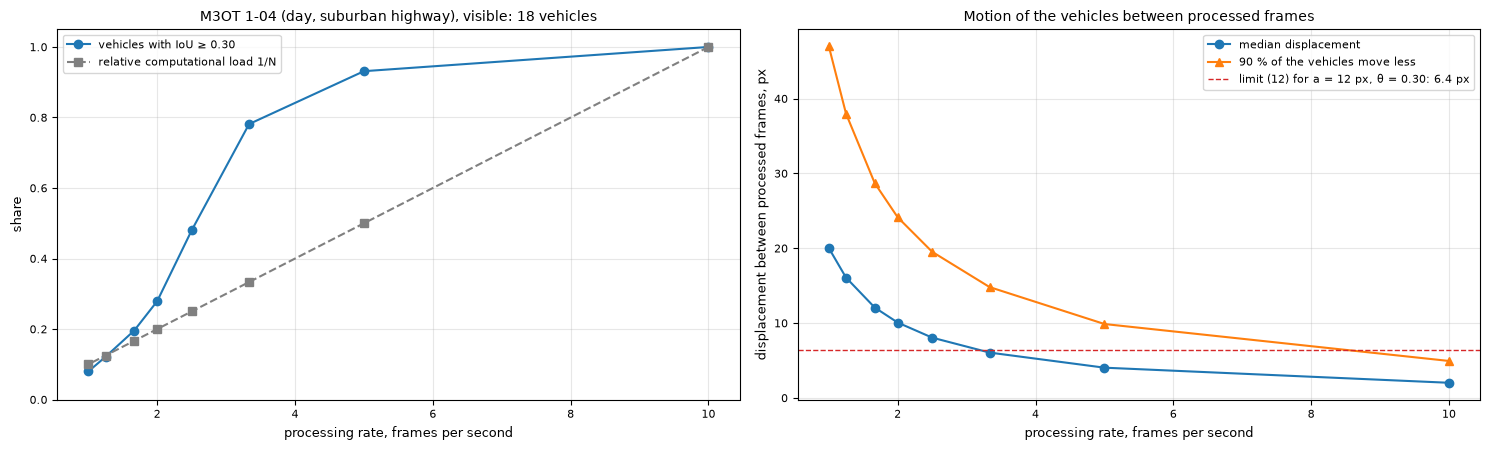

,processing_rate,relative_load,pairs,share_IoU_ok,displacement_median_px,displacement_90_px,box_size_px
step_N,,,,,,,
1,10.000,1.000,2959,1.000,2.023,4.939,11.92
2,5.000,0.500,2941,0.931,4.040,9.876,11.92
3,3.333,0.333,2923,0.781,6.058,14.812,11.91
4,2.500,0.250,2905,0.480,8.056,19.528,11.91
5,2.000,0.200,2887,0.279,10.071,24.137,11.91
6,1.667,0.167,2869,0.196,12.079,28.703,11.91
8,1.250,0.125,2833,0.121,16.082,37.992,11.91
10,1.000,0.100,2797,0.080,20.032,47.011,11.91


In [10]:
#@title 2.1.4-B Processing rate and motion between processed frames [auto] { run: "auto", display-mode: "form" }
SEQUENCE = "1-04" #@param ["1-01", "1-02", "1-03", "1-04", "1-05", "1-06", "1-07", "1-08", "1-09"]
CHANNEL = "visible" #@param ["visible", "thermal"]
IOU_THRESHOLD = 0.3 #@param {type:"slider", min:0.1, max:0.7, step:0.05}

tracks = m3ot.tracks(SEQUENCE, "rgb" if CHANNEL == "visible" else "ir")
F = m3ot.CAMERA["fps"]
rows = []
for N in (1, 2, 3, 4, 5, 6, 8, 10):
    so = aitbc.step_overlap(tracks, N)
    rows.append(dict(step_N=N, processing_rate=F / N, relative_load=1 / N, pairs=len(so),
                     share_IoU_ok=float((so.iou >= IOU_THRESHOLD).mean()),
                     displacement_median_px=float(so.displacement_px.median()),
                     displacement_90_px=float(so.displacement_px.quantile(0.9)), box_size_px=float(so.size_px.median())))
tab = pd.DataFrame(rows).set_index("step_N")
a = tab.box_size_px.median()
d_lim = a * (1 - IOU_THRESHOLD) / (1 + IOU_THRESHOLD)                       # formula (12)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
ax[0].plot(tab.processing_rate, tab.share_IoU_ok, "o-", label=f"vehicles with IoU ≥ {IOU_THRESHOLD:.2f}")
ax[0].plot(tab.processing_rate, tab.relative_load, "s--", color="gray", label="relative computational load 1/N")
ax[0].set_xlabel("processing rate, frames per second")
ax[0].set_ylabel("share")
ax[0].set_ylim(0, 1.05)
ax[0].set_title(f"M3OT {SEQUENCE} ({m3ot.SEQUENCES[SEQUENCE]}), {CHANNEL}: {tracks.id.nunique()} vehicles", fontsize=10)
ax[0].grid(alpha=0.3)
ax[0].legend(fontsize=8)
ax[1].plot(tab.processing_rate, tab.displacement_median_px, "o-", label="median displacement")
ax[1].plot(tab.processing_rate, tab.displacement_90_px, "^-", label="90 % of the vehicles move less")
ax[1].axhline(d_lim, color="C3", ls="--", lw=1, label=f"limit (12) for a = {a:.0f} px, θ = {IOU_THRESHOLD:.2f}: {d_lim:.1f} px")
ax[1].set_xlabel("processing rate, frames per second")
ax[1].set_ylabel("displacement between processed frames, px")
ax[1].set_title("Motion of the vehicles between processed frames", fontsize=10)
ax[1].grid(alpha=0.3)
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
display(tab.round(3))

### Summary of Lesson 2.1

- A digital frame is an array: a matrix H × W for a grey or thermal frame, a tensor H × W × C for a colour frame, T × H × W × C for a video fragment and N × C × H × W for a batch of a neural network. Its size (1) and the uncompressed data rate (2) grow with the resolution and the frame rate; neighbouring pixels are strongly correlated.
- The number of bits per value limits the levels of brightness (3); the PSNR of the quantisation follows (4), while the structural loss is largest for single-channel frames with smooth transitions of brightness, such as thermal frames.
- HSV separates the colour from the brightness: on the labelled day frames of Kust4K the hue finds trees much better than any grey threshold. The separating feature depends on the class and on the scene: vegetation in the frames of the ground vehicle is separated better by its low brightness. Colour rules fail at night and depend on season and illumination; grey frames are smaller and sufficient for many classical algorithms.
- The frame of an FPV drone is formed by a wide-angle lens with distortion and vignetting, by the motion during the exposure (5) and the readout of a rolling shutter (6), and by the radio link (7)–(10): an analog link degrades gradually, a digital link keeps the quality and breaks down near the edge of its range.
- The processing time grows with the number of pixels, for large frames almost in proportion; the condition of real time (11) limits the resolution and the set of algorithms. Lowering the processing rate reduces the load but increases the motion between processed frames (12).

### Control questions
1. What are the shape and the size in bytes of one frame 1280 × 720 of a colour camera and of one frame 640 × 512 of a thermal camera (8 bit)? What is the uncompressed data rate of each at 30 frames per second? *(2.76 MB and 0.33 MB; 663.6 Mbit/s and 78.6 Mbit/s.)*
2. In which order of axes does OpenCV store a frame, and in which order does PyTorch expect a batch? Why must the order of the channels B, G, R be converted?
3. What PSNR does a quantisation to 6 bits give by formula (4)? Why does a thermal frame suffer more from a reduction of the bits than a daylight frame? *(About 46.9 dB.)*
4. Why does a threshold on the hue find trees better than a threshold on the grey level? Why does the same rule fail at night?
5. A camera with a field of view of 150° and a width of 1280 px is turned at 400 °/s with an exposure of 5 ms. What is the blur (5)? *(About 17 px.)*
6. How many times does the range of a link decrease when interference raises the noise of the receiver by 12 dB? *(About 4 times: 12 dB = 20 lg 4.)*
7. Why does the picture of an analog link degrade gradually, while a digital link breaks down suddenly? Which behaviour is easier for a pilot near the edge of the range?
8. An algorithm needs 20 ms for a frame 1280 × 720. Can it process a stream 1920 × 1080 at 30 frames per second in real time, if the time is proportional to the number of pixels? *(No: 45 ms > 33 ms.)*
9. Vehicles of 10 px move by 2 px per frame at 10 frames per second. Up to which processing rate does the overlap with θ = 0.3 still link them by (12)? *(d ≤ 5.4 px: every second frame, 5 frames per second.)*

---
# Lesson 2.2 (Group class). Stages of preprocessing of video frame data

**Learning questions**
1. Typical factors of degradation of the video signal depending on the conditions of use of military robotic complexes.
2. Basic methods of noise reduction of video frames based on Gaussian Blur and Median Blur.
3. The method of contrast-limited adaptive histogram equalisation CLAHE for the increase of the contrast of night and thermal frames.
4. Change of the geometric parameters of a frame to ensure compatibility with the requirements of real time.
5. The principle of the letterbox transformation and the conversion of a frame to the standard input format of neural network models.

**Order of preprocessing.** Diagnosis of the frame (block 2.2.1) → noise reduction (2.2.2) → contrast (2.2.3) → size of the frame (2.2.4) → input of the model (2.2.5). The noise is reduced before the contrast is increased, because the contrast enhancement amplifies the noise too.

**Expected outcome.** After the group class a participant measures the quality indicators of a frame and chooses the preprocessing steps for it; chooses between the Gaussian and the median filter for a given kind of noise and checks the effect on a detector; applies CLAHE with justified parameters and knows its limits; chooses the size of the processed frame from the time budget and the size of the objects; converts a frame to the input of a detector and maps the boxes back to the frame.

### Block 2.2.1-A. Degradation factors and quality indicators of real frames [auto]

**Purpose.** To relate the conditions of use of UAVs and UGVs to the degradations of the frames and to measurable indicators that decide which preprocessing step is needed.

| Condition of use | Factor | Effect in the frame | Indicator | Preprocessing step |
|---|---|---|---|---|
| night, dusk, smoke screen | low illumination | dark frame, few levels, noise after the gain of the camera | mean, entropy, noise σ | noise reduction, CLAHE (2.2.2, 2.2.3) |
| fog, haze, dust | scattering of light | veil, low contrast | RMS contrast | CLAHE, dehazing |
| manoeuvres, wind, vibration | motion of the camera | blur, rolling-shutter distortion | sharpness relative to the other frames of the stream | short exposure, stabilisation (3.4), rejection of the frame |
| long range, obstacles, jamming | radio link | noise, sparkles, torn lines, lost blocks | noise σ, share of impulses | median filter, rejection of the frame |
| low bit rate | compression | blocks, loss of fine details | — | choice of the bit rate |
| sun, fires, flashes; thermal crossover | dynamic range | clipped black or white pixels; object and background of equal thermal brightness | share of clipped pixels, SCR | exposure control, second channel |
| rain, snow, mud | weather, lens | drops and spots, low local contrast | local contrast | protection of the lens |

**Indicators.** Mean brightness and RMS contrast (standard deviation) of the grey levels, entropy (bit), sharpness (variance of the Laplacian; it depends on the camera and the scene and is compared between frames of the same stream), share of clipped pixels (0–2 or 253–255) and the standard deviation of the noise by the method of Immerkær:

$$\sigma_n = \sqrt{\frac{\pi}{2}} \, \frac{1}{6 \, |\Omega|} \sum_{(x, y) \in \Omega} \left| (I * M)(x, y) \right|, \quad M = \begin{bmatrix} 1 & -2 & 1 \\ -2 & 4 & -2 \\ 1 & -2 & 1 \end{bmatrix}. \tag{13}$$

The mask M suppresses the smooth structure of the scene and leaves the noise; Ω are the pixels without strong edges (10 % of the pixels with the strongest gradient of the smoothed frame are excluded); for a colour frame the estimate is averaged over the channels.

**Parameters.** Thresholds of the diagnosis: `DARK_MEAN`, `LOW_CONTRAST`, `NOISE_MAX`, `CLIPPED_MAX`, `BLUR_RATIO` (sharpness relative to the sharpest frame of the same stream).

**What to observe.** The gallery contains real frames of the data sets and two degradations modelled on a real day frame (marked "modelled"). The noise of the real night frames is low (σ below 1 grey level): the cameras of the data sets reduce the noise and compress the video before recording; the night frames are found by their low mean brightness, as is the GOOSE frame in the rain under a bridge. In the night frame Kust4K 02807N 7.5 % of the pixels are clipped at black, in the winter GOOSE frame 8.9 % of the pixels (the overcast sky) are clipped at white: this information is lost and cannot be restored by preprocessing. Frame 92 of the thermal video shows the same scene as frame 112 with almost the same contrast (RMS 20.0 and 22.3), but its sharpness is 2.3 times lower: a blurred frame is found by comparison with sharp frames of the same stream. Absolute thresholds of sharpness are not transferred between cameras: the sharp thermal frame 112 has a lower sharpness than the night visible frames. In the modelled low light the gain of the camera restores most of the brightness (mean 105 against 133 of the day frame), but the noise grows to about 6 grey levels; the modelled analog link raises it to about 45.

In [11]:
#@title 2.2.1-A Degradation factors and quality indicators of real frames [auto] { run: "auto", display-mode: "form" }
DARK_MEAN = 70 #@param {type:"slider", min:20, max:120, step:5}
LOW_CONTRAST = 15 #@param {type:"slider", min:5, max:50, step:1}
NOISE_MAX = 4.0 #@param {type:"slider", min:1, max:15, step:0.5}
CLIPPED_MAX = 0.05 #@param {type:"slider", min:0.01, max:0.3, step:0.01}
BLUR_RATIO = 0.5 #@param {type:"slider", min:0.1, max:0.9, step:0.05}

if "GALLERY" not in globals():
    day = m3ot.frames("1-04", "rgb", start=150, count=1)[0]
    video = {k: fr for k, t, fr in aitbc.iter_video(hit.video("130m-60_3.mov"), every_n=1, max_frames=120) if k in (92, 112)}
    GALLERY = [
        ("day, UAV, visible — M3OT 1-04", day, None),
        ("dusk, UAV, visible — M3OT 1-06", m3ot.frames("1-06", "rgb", start=300, count=1)[0], None),
        ("night, UAV, visible — M3OT 1-02", m3ot.frames("1-02", "rgb", start=300, count=1)[0], None),
        ("night, UAV, visible, street lights — Kust4K 02807N", kust.pair("02807N")["rgb"], None),
        ("night, street, visible — VisDrone", vis.load(vis.CURATED[2])[0], None),
        ("night, UAV, thermal — HIT-UAV", aitbc.to_rgb(hit.load(hit.EXAMPLES[2])[0]), None),
        ("unstable part of a thermal video — HIT-UAV, frame 92", video[92], "HIT-UAV video 130m-60_3"),
        ("same video and scene, frame 112", video[112], "HIT-UAV video 130m-60_3"),
        ("rain, UGV — GOOSE", goose.load(goose.CURATED[11], scale=0.5)[0], None),
        ("winter, UGV — GOOSE", goose.load(goose.CURATED[8], scale=0.5)[0], None),
        ("modelled: low light and sensor gain on the day frame", aitbc.low_light(day, level=0.12, seed=1), None),
        ("modelled: analog link 3 dB below the threshold", aitbc.analog_link_frame(day, 7.0, threshold_db=10.0, seed=1), None),
    ]

rows = []
for name, img, stream in GALLERY:
    g = aitbc.gray(img)
    rows.append(dict(frame=name, stream=stream, mean=float(g.mean()), rms_contrast=aitbc.rms_contrast(img),
                     entropy_bit=aitbc.entropy(img), sharpness=aitbc.sharpness(img), noise_sigma_13=aitbc.noise_sigma(img),
                     clipped=float(((g <= 2) | (g >= 253)).mean())))
tab = pd.DataFrame(rows)
best_in_stream = tab.groupby("stream").sharpness.transform("max")
tab["sharpness_to_best_of_stream"] = tab.sharpness / best_in_stream


def diagnosis(r):
    steps = []
    if r.noise_sigma_13 > NOISE_MAX:
        steps.append("noise: filter (2.2.2)")
    if r["mean"] < DARK_MEAN or r.rms_contrast < LOW_CONTRAST:
        steps.append("dark or low contrast: CLAHE (2.2.3)")
    if r.clipped > CLIPPED_MAX:
        steps.append("clipped pixels: lost, not restorable")
    if pd.notna(r.sharpness_to_best_of_stream) and r.sharpness_to_best_of_stream < BLUR_RATIO:
        steps.append("blurred: reject or stabilise")
    return "; ".join(steps) if steps else "no correction of brightness or noise"


tab["diagnosis"] = tab.apply(diagnosis, axis=1)
fig, ax = plt.subplots(3, 4, figsize=(18, 11))
for a, (name, img, _), d in zip(ax.ravel(), GALLERY, tab.diagnosis):
    a.imshow(img)
    a.set_title(name, fontsize=9)
    a.text(0.01, 0.02, d, transform=a.transAxes, fontsize=7.5, color="yellow", va="bottom",
           bbox=dict(facecolor="black", alpha=0.6, pad=2, lw=0))
    a.axis("off")
plt.tight_layout()
plt.show()
display(tab.drop(columns=["stream"]).set_index("frame").round(3))

*[Figure omitted in the public copy of the repository. It shows frames of the VisDrone2019-DET data set (Zhu P. et al., IEEE TPAMI 44(11), 2022), which is distributed for non-commercial use and is therefore not redistributed here. Run the cell in Google Colab to obtain the figure.]*

,mean,rms_contrast,entropy_bit,sharpness,noise_sigma_13,clipped,sharpness_to_best_of_stream,diagnosis
frame,,,,,,,,
"day, UAV, visible — M3OT 1-04",132.592,35.636,6.954,1037.577,1.692,0.001,NaN,no correction of brightness or noise
"dusk, UAV, visible — M3OT 1-06",106.513,40.115,7.020,437.744,0.952,0.000,NaN,no correction of brightness or noise
"night, UAV, visible — M3OT 1-02",67.553,47.691,6.221,136.983,0.516,0.000,NaN,dark or low contrast: CLAHE (2.2.3)
"night, UAV, visible, street lights — Kust4K 02807N",26.691,34.258,6.028,397.647,0.705,0.076,NaN,"dark or low contrast: CLAHE (2.2.3); clipped pixels: lost, not restorable"
"night, street, visible — VisDrone",50.480,29.844,6.485,120.326,0.484,0.001,NaN,dark or low contrast: CLAHE (2.2.3)
"night, UAV, thermal — HIT-UAV",132.208,29.227,6.860,38.995,0.433,0.000,NaN,no correction of brightness or noise
"unstable part of a thermal video — HIT-UAV, frame 92",120.277,19.984,6.182,9.960,0.275,0.000,0.432,blurred: reject or stabilise
"same video and scene, frame 112",120.160,22.339,6.425,23.045,0.576,0.000,1.000,no correction of brightness or noise
"rain, UGV — GOOSE",68.151,58.624,6.818,398.333,0.883,0.033,NaN,dark or low contrast: CLAHE (2.2.3)


### Block 2.2.2-A. Noise reduction with Gaussian Blur and Median Blur [auto]

**Purpose.** To compare the two basic filters of noise reduction on a real frame with noise of a known level and kind, so that the result can be compared with the clean frame.

**Gaussian filter.** Every pixel is replaced by a weighted mean of its k × k neighbourhood with the weights

$$G(x, y) = \frac{1}{2 \pi \sigma^2} \exp\left(-\frac{x^2 + y^2}{2 \sigma^2}\right), \tag{14}$$

normalised to the sum 1; OpenCV sets $\sigma = 0.3\,((k - 1)/2 - 1) + 0.8$ when σ = 0 is given. The filter is linear and separable (two one-dimensional passes), therefore fast; it suppresses Gaussian noise and smooths edges.

**Median filter.** Every pixel is replaced by the median of the values of its k × k neighbourhood:

$$I'(x, y) = \operatorname{med}\{\, I(u, v) : |u - x| \le r, \ |v - y| \le r \,\}, \quad k = 2r + 1. \tag{15}$$

The filter is non-linear: a single extreme value (an impulse) does not change the median, therefore it removes impulse noise; it keeps step edges between large uniform regions, but removes lines and textures thinner than about half of its window.

**Noise.** *Gaussian* — noise of the sensor and of the amplifier at a weak signal, added independently to every pixel with the standard deviation `NOISE_SIGMA`; *impulse* — isolated black and white pixels ("sparkles" of an analog link near its threshold, defective pixels), share `IMPULSE_SHARE`; *both*; *none* — the frame as recorded (then there is no clean reference and only the estimate (13) is shown).

**Parameters.** `SOURCE`, `FRAME_NUMBER`; `NOISE`, `NOISE_SIGMA`, `IMPULSE_SHARE`; `KERNEL` — size k of both filters; `GAUSS_SIGMA` — σ of (14), 0 = from the kernel; `ZOOM` — show the central part of the frame enlarged.

**What to observe.** For Gaussian noise the Gaussian filter gives a higher PSNR and SSIM than the median filter of the same size. For impulse noise the median filter removes the impulses already with a 3 × 3 window, while the Gaussian filter spreads them into grey spots. The best kernel depends on the frame: for detailed visible frames 3 × 3 is best, larger kernels destroy the details (the curves of PSNR fall); for smooth thermal frames with Gaussian noise larger kernels are better.

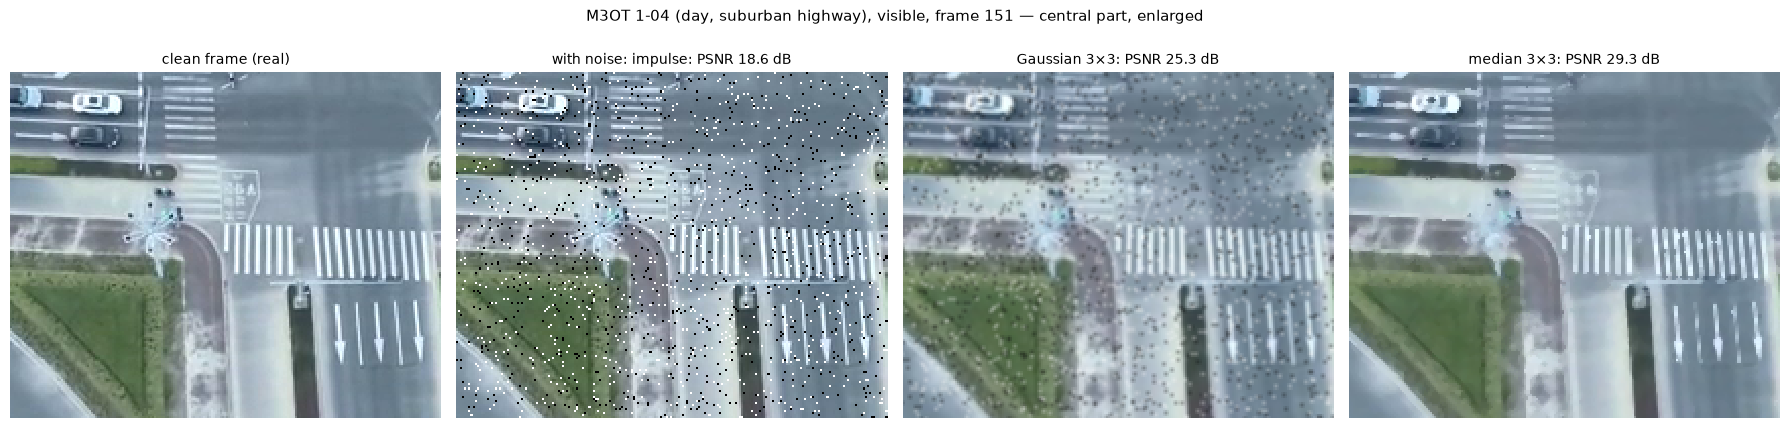

,PSNR_dB,SSIM,noise_sigma_13,average_gradient,time_ms
frame,,,,,
noisy frame,18.620,0.408,19.880,29.035,NaN
Gaussian 3×3,25.317,0.661,1.482,16.559,0.067
median 3×3,29.275,0.927,1.396,10.965,0.239


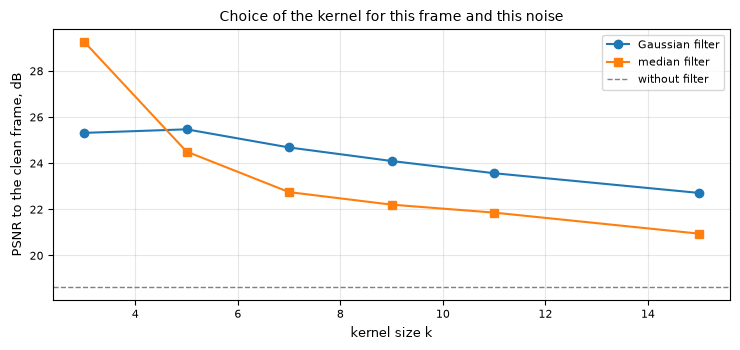

In [12]:
#@title 2.2.2-A Gaussian Blur and Median Blur [auto] { run: "auto", display-mode: "form" }
SOURCE = "M3OT: visible, day" #@param ["VisDrone: visible, oblique view over a city", "M3OT: visible, day", "HIT-UAV: thermal (white-hot)", "Kust4K: thermal (colour palette)", "GOOSE: ground vehicle, front camera", "own frame (block 0.3)"]
FRAME_NUMBER = 1 #@param {type:"slider", min:1, max:8, step:1}
NOISE = "impulse" #@param ["Gaussian", "impulse", "Gaussian and impulse", "none (frame as recorded)"]
NOISE_SIGMA = 20 #@param {type:"slider", min:0, max:60, step:1}
IMPULSE_SHARE = 0.05 #@param {type:"slider", min:0, max:0.3, step:0.01}
KERNEL = 3 #@param {type:"slider", min:3, max:15, step:2}
GAUSS_SIGMA = 0.0 #@param {type:"slider", min:0, max:5, step:0.1}
ZOOM = True #@param {type:"boolean"}

fr = load_frame(SOURCE, FRAME_NUMBER)
clean = fr["img"]
if NOISE.startswith("none"):
    noisy = clean
else:
    noisy = clean
    if NOISE.startswith("Gaussian") and NOISE_SIGMA > 0:
        noisy = aitbc.add_gaussian_noise(noisy, NOISE_SIGMA, seed=1)
    if "impulse" in NOISE and IMPULSE_SHARE > 0:
        noisy = aitbc.add_impulse_noise(noisy, IMPULSE_SHARE, seed=2)
k = int(KERNEL)
t_g = aitbc.time_call(lambda: cv2.GaussianBlur(noisy, (k, k), GAUSS_SIGMA), repeats=3)
t_m = aitbc.time_call(lambda: cv2.medianBlur(noisy, k), repeats=3)
out_g = cv2.GaussianBlur(noisy, (k, k), GAUSS_SIGMA)                      # formula (14)
out_m = cv2.medianBlur(noisy, k)                                          # formula (15)
has_ref = not NOISE.startswith("none")

H, W = clean.shape[:2]
ys, xs = (slice(H // 2 - H // 6, H // 2 + H // 6), slice(W // 2 - W // 6, W // 2 + W // 6)) if ZOOM else (slice(None), slice(None))
panels = [("clean frame (real)" if has_ref else "frame as recorded", clean), (f"with noise: {NOISE}", noisy),
          (f"Gaussian {k}×{k}", out_g), (f"median {k}×{k}", out_m)]
fig, ax = plt.subplots(1, 4, figsize=(18, 4.6))
for a, (t_, im_) in zip(ax, panels):
    a.imshow(im_[ys, xs], interpolation="nearest")
    a.set_title(t_ + (f": PSNR {aitbc.psnr(clean, im_):.1f} dB" if has_ref and im_ is not clean else ""), fontsize=10)
    a.axis("off")
plt.suptitle(fr["caption"] + (" — central part, enlarged" if ZOOM else ""), fontsize=11)
plt.tight_layout()
plt.show()

rows = []
for name, im_, t_ in (("noisy frame", noisy, None), (f"Gaussian {k}×{k}", out_g, t_g), (f"median {k}×{k}", out_m, t_m)):
    rows.append(dict(frame=name, PSNR_dB=aitbc.psnr(clean, im_) if has_ref else np.nan, SSIM=aitbc.ssim(clean, im_) if has_ref else np.nan,
                     noise_sigma_13=aitbc.noise_sigma(im_), average_gradient=aitbc.average_gradient(im_), time_ms=t_))
display(pd.DataFrame(rows).set_index("frame").round(3))
if has_ref:
    ks = [3, 5, 7, 9, 11, 15]
    pg = [aitbc.psnr(clean, cv2.GaussianBlur(noisy, (q, q), 0)) for q in ks]
    pm = [aitbc.psnr(clean, cv2.medianBlur(noisy, q)) for q in ks]
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    ax.plot(ks, pg, "o-", label="Gaussian filter")
    ax.plot(ks, pm, "s-", label="median filter")
    ax.axhline(aitbc.psnr(clean, noisy), color="gray", ls="--", lw=1, label="without filter")
    ax.set_xlabel("kernel size k")
    ax.set_ylabel("PSNR to the clean frame, dB")
    ax.set_title("Choice of the kernel for this frame and this noise", fontsize=10)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

### Block 2.2.2-B. Noise reduction before detection: warm objects in annotated thermal frames

**Purpose.** To measure the effect of noise and of noise reduction on the result of a detector instead of the effect on the picture. The detector of warm spots of the course library (Notebook 01) is applied to real night frames of HIT-UAV with annotated persons; noise of a given level is added and the frames are processed without a filter, with the Gaussian and with the median filter before the detector.

**Measures.** Recall — share of the annotated persons found; precision — share of the detections that are persons. A detection is correct when its centre lies in the box of a person.

**Parameters.** `NOISE` — Gaussian or impulse; `KERNEL` — size of both filters; `N_FRAMES` — number of night frames (4–20, about 13 persons per frame); `DETECTOR_K` — threshold of the detector in standard deviations of the background.

**What to observe.** Without a filter the recall falls quickly with the noise: at σ = 40 it is about half of the recall of the clean frames. A filter 5 × 5 before the detector restores most of it; for impulse noise the median filter returns the recall of the clean frames, the Gaussian filter a part of it. The precision without a filter even grows with the noise: the threshold of the detector follows the spread of the background, so it reports fewer but more contrasting spots. Noise reduction is a part of the detection chain, and its effect is checked by the measures of the detector.

12 night frames, 153 annotated persons; computed in 3 s


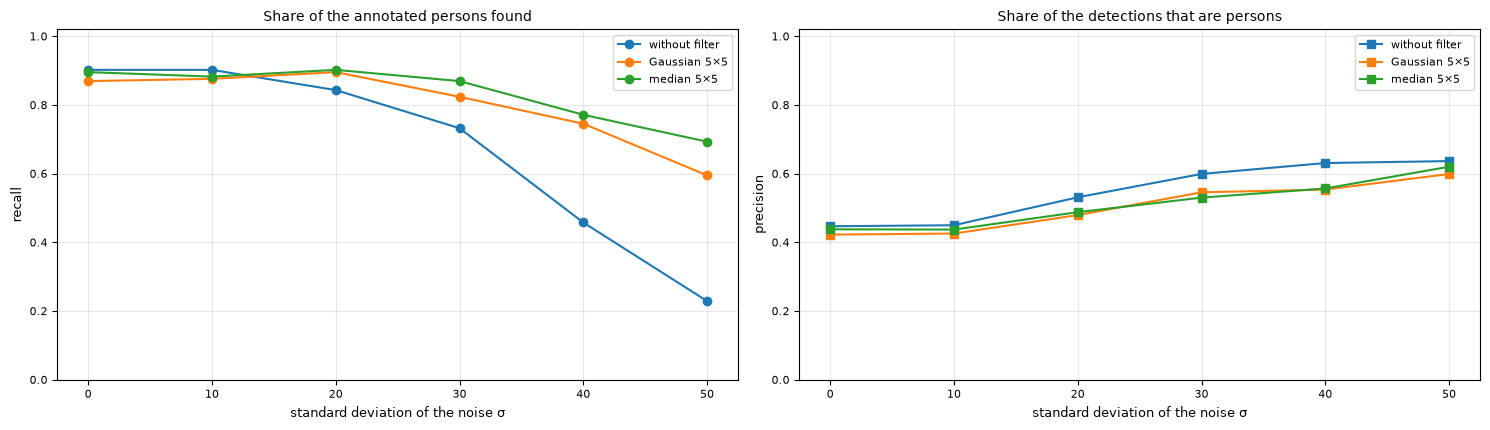

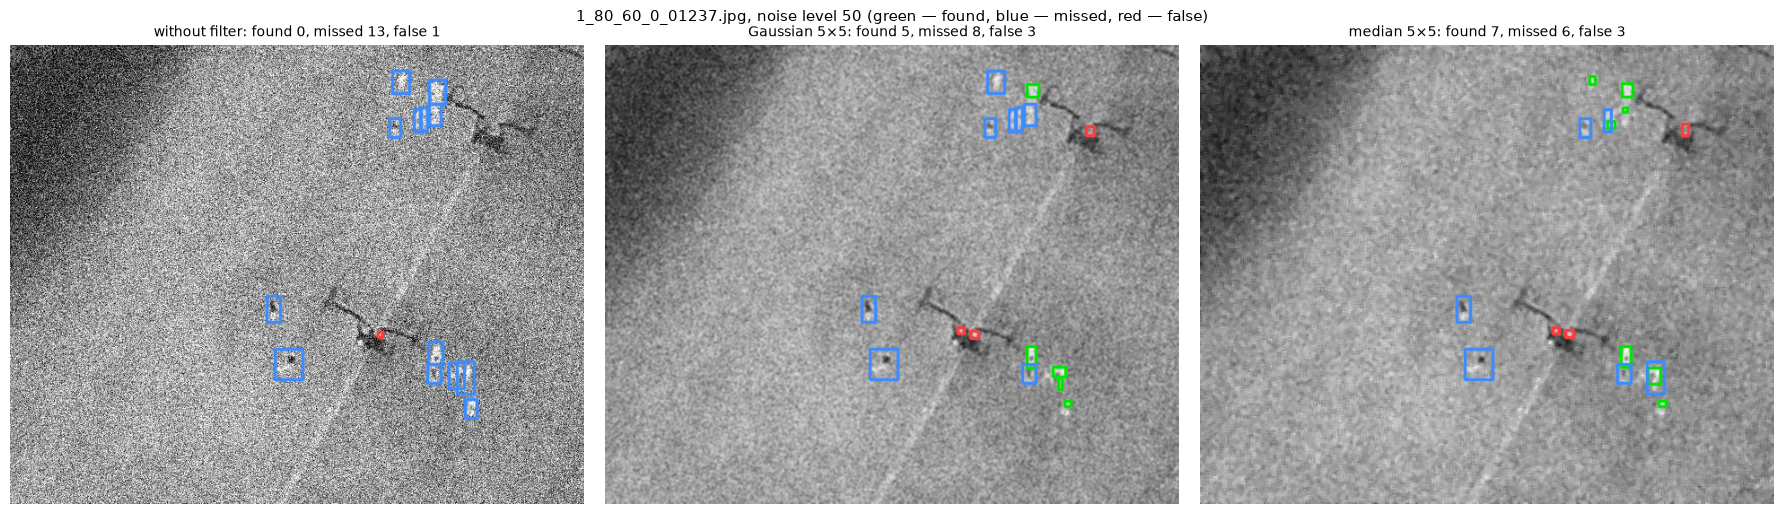

recall                              precision               \
filter without filter Gaussian 5×5 median 5×5 without filter Gaussian 5×5   
level                                                                       
0                0.90         0.87       0.90           0.45         0.42   
10               0.90         0.88       0.88           0.45         0.43   
20               0.84         0.90       0.90           0.53         0.48   
30               0.73         0.82       0.87           0.60         0.55   
40               0.46         0.75       0.77           0.63         0.55   
50               0.23         0.59       0.69           0.64         0.60   

                   
filter median 5×5  
level              
0            0.44  
10           0.44  
20           0.49  
30           0.53  
40           0.56  
50           0.62

In [13]:
#@title 2.2.2-B Noise reduction before detection on annotated thermal frames { display-mode: "form" }
NOISE = "Gaussian" #@param ["Gaussian", "impulse"]
KERNEL = 5 #@param {type:"slider", min:3, max:9, step:2}
N_FRAMES = 12 #@param {type:"slider", min:4, max:20, step:1}
DETECTOR_K = 5.0 #@param {type:"slider", min:3, max:8, step:0.5}

LEVELS = [0, 10, 20, 30, 40, 50] if NOISE == "Gaussian" else [0.0, 0.01, 0.02, 0.04, 0.06, 0.10]
FILTERS = {"without filter": lambda x: x, f"Gaussian {KERNEL}×{KERNEL}": lambda x: cv2.GaussianBlur(x, (KERNEL, KERNEL), 0),
           f"median {KERNEL}×{KERNEL}": lambda x: cv2.medianBlur(x, KERNEL)}
t0 = time.time()
counts, example = [], None
for f in HIT_NIGHT[:N_FRAMES]:
    img, objs = hit.load(f)
    r = hit.images.set_index("file").loc[f]
    gsd = hit.gsd(r.altitude, r.angle)
    for lev in LEVELS:
        noisy = img if lev == 0 else (aitbc.add_gaussian_noise(img, lev, seed=3) if NOISE == "Gaussian" else aitbc.add_impulse_noise(img, lev, seed=3))
        for name, flt in FILTERS.items():
            boxes, _ = aitbc.detect_warm_objects(flt(noisy), gsd, k=DETECTOR_K)
            m = aitbc.match_detections(boxes, objs, ("Person",))
            counts.append(dict(level=lev, filter=name, tp=len(m["tp"]), fp=len(m["fp"]), missed=len(m["missed"])))
            if f == HIT_NIGHT[0] and lev == LEVELS[-1]:
                example = example or {}
                example[name] = (flt(noisy), m)
res = pd.DataFrame(counts).groupby(["level", "filter"], sort=False).sum()
res["recall"] = res.tp / (res.tp + res.missed)
res["precision"] = res.tp / (res.tp + res.fp).clip(lower=1)
print(f"{N_FRAMES} night frames, {int((res.tp + res.missed).iloc[0])} annotated persons; computed in {time.time() - t0:.0f} s")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
for name in FILTERS:
    sub = res.xs(name, level="filter")
    ax[0].plot(LEVELS, sub.recall.values, "o-", label=name)
    ax[1].plot(LEVELS, sub.precision.values, "s-", label=name)
xl = "standard deviation of the noise σ" if NOISE == "Gaussian" else "share of impulse pixels"
for a, yl in zip(ax, ("recall", "precision")):
    a.set_xlabel(xl)
    a.set_ylabel(yl)
    a.set_ylim(0, 1.02)
    a.grid(alpha=0.3)
    a.legend(fontsize=8)
ax[0].set_title("Share of the annotated persons found", fontsize=10)
ax[1].set_title("Share of the detections that are persons", fontsize=10)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
for a, (name, (im_, m)) in zip(ax, example.items()):
    objs_ = ([dict(cls="found", box=b) for b in m["tp"]] + [dict(cls="false", box=b) for b in m["fp"]] +
             [dict(cls="missed", box=o["box"]) for o in m["missed"]])
    a.imshow(aitbc.draw_boxes(im_, objs_, {"found": (0, 230, 0), "false": (255, 60, 60), "missed": (60, 140, 255)}, labels=False, thickness=2))
    a.set_title(f"{name}: found {len(m['tp'])}, missed {len(m['missed'])}, false {len(m['fp'])}", fontsize=10)
    a.axis("off")
plt.suptitle(f"{HIT_NIGHT[0]}, noise level {LEVELS[-1]} (green — found, blue — missed, red — false)", fontsize=11)
plt.tight_layout()
plt.show()
display(res[["recall", "precision"]].unstack("filter").round(2))

### Block 2.2.3-A. CLAHE for night and thermal frames [auto]

**Purpose.** To increase the contrast of night and thermal frames by histogram equalisation, to measure the gain in visual informativeness, and to check what happens to the noise and to the contrast of annotated objects.

**Global histogram equalisation (HE).** The grey level k is replaced by the value of the cumulative distribution of the levels:

$$s_k = \operatorname{round}\Big((L - 1) \sum_{j=0}^{k} p_j\Big), \tag{16}$$

where $p_j$ is the share of pixels with the level j and L = 256. Frequent levels are spread apart, rare levels are merged; the large uniform background of a frame receives most of the levels.

**CLAHE** (contrast-limited adaptive histogram equalisation) divides the frame into `TILES` × `TILES` regions. The histogram of every region is clipped at

$$\beta = c \, \frac{N_{tile}}{L}, \tag{17}$$

where c is `CLIP_LIMIT` and $N_{tile}$ the number of pixels of the region; the clipped excess is distributed over all levels, the mapping (16) is computed for every region, and the mappings of neighbouring regions are interpolated bilinearly. The clipping limits the slope of the mapping, that is the local gain of the contrast and of the noise, to about c. A colour frame is equalised in its lightness L* (CIE L\*a\*b\*), so that the colours are kept.

**Measures.** Entropy and average gradient (mean magnitude of the brightness gradient) — indicators of visual informativeness; noise σ (13); median SCR of the annotated objects of the frame — vehicles of M3OT, cars and persons of Kust4K, persons of HIT-UAV (signal-to-clutter ratio, Notebook 01: the difference of the object and its background ring divided by the spread of the background).

**Parameters.** `FRAME`; `METHOD` — CLAHE, global HE or none; `CLIP_LIMIT` c; `TILES`; `DENOISE_FIRST` — filter before the equalisation.

**What to observe.** Equalisation raises the entropy and the average gradient: more details become visible to the operator. It raises the noise as well: CLAHE with c = 2 raises σ (13) by 1.6–2.9 times in the six frames of the block; a median filter 3 × 3 before CLAHE reduces the increase. The SCR of the annotated objects does not grow significantly: with CLAHE, c = 2, it changes between −30 % and +11 % in the six frames, because the local contrast of the background (clutter) is amplified as much as the contrast of the objects. Global HE is unsuitable for thermal frames with small warm objects: the background dominates the histogram and receives most of the levels (for the 15 persons of the HIT-UAV frame the median SCR falls from 3.8 to 1.1 with global HE and to 2.7 with CLAHE, c = 2). CLAHE is therefore a step for the display to the operator; for an automatic detector its use is checked by the measures of the detector (Lesson 2.4).

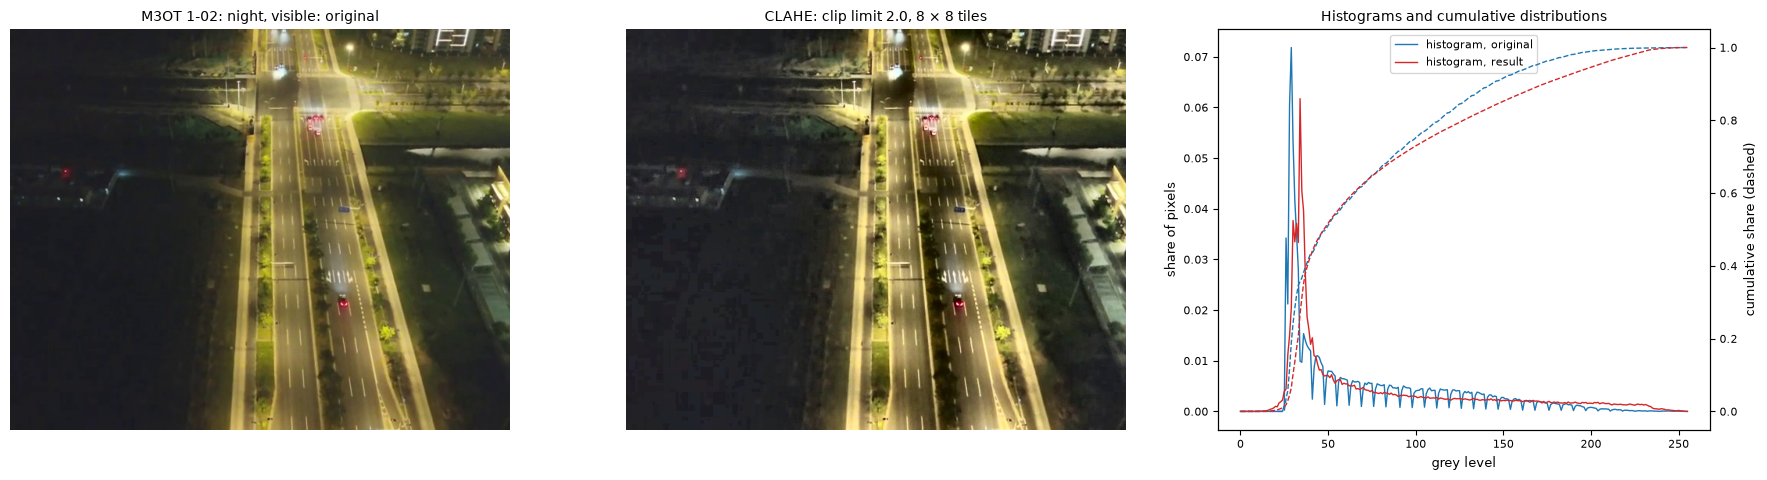

,mean,entropy_bit,rms_contrast,average_gradient,noise_sigma_13,SCR_objects_median,objects
processing,,,,,,,
original,69.65,6.58,47.50,5.83,0.60,0.62,8
"CLAHE: clip limit 2.0, 8 × 8 tiles",76.85,6.89,57.25,9.73,1.18,0.58,8
"CLAHE c = 1, 8 × 8",72.37,6.65,52.27,8.05,0.95,0.60,8
"CLAHE c = 2, 8 × 8",76.85,6.89,57.25,9.73,1.18,0.58,8
"CLAHE c = 4, 8 × 8",84.41,7.21,61.74,11.51,1.53,0.58,8
"CLAHE c = 8, 8 × 8",92.39,7.48,61.75,12.87,1.90,0.59,8
global HE,124.68,6.84,67.96,7.28,1.17,0.46,8


In [14]:
#@title 2.2.3-A CLAHE for night and thermal frames [auto] { run: "auto", display-mode: "form" }
FRAME = "M3OT 1-02: night, visible" #@param ["M3OT 1-02: night, visible", "M3OT 1-02: night, thermal (black-hot)", "M3OT 1-08: dusk, visible", "Kust4K 02807N: night, visible", "Kust4K 02807N: night, thermal (luminance of the palette)", "HIT-UAV: night, thermal (white-hot), 15 persons", "own frame (block 0.3)"]
METHOD = "CLAHE" #@param ["CLAHE", "global histogram equalisation (HE)", "none"]
CLIP_LIMIT = 2.0 #@param {type:"slider", min:1, max:10, step:0.5}
TILES = 8 #@param {type:"slider", min:2, max:16, step:1}
DENOISE_FIRST = "none" #@param ["none", "median 3×3", "Gaussian 3×3"]


def label_masks(lab, class_ids, min_area=30):
    masks = []
    for cid in class_ids:
        n, cc, stats, _ = cv2.connectedComponentsWithStats((lab == cid).astype(np.uint8), connectivity=8)
        masks += [cc == i for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= min_area]
    return masks


if FRAME.startswith("M3OT"):
    seq = FRAME[5:9]
    ch = "ir" if "thermal" in FRAME else "rgb"
    f0 = {"1-02": 679, "1-08": 300}[seq]                                   # frames with 8 and 16 annotated vehicles
    img = m3ot.frames(seq, ch, start=f0, count=1)[0]
    masks = [aitbc.box_mask(img.shape, o["box"]) for o in m3ot.objects(m3ot.tracks(seq, ch), f0 + 1)]
elif FRAME.startswith("Kust4K"):
    p = kust.pair("02807N")
    img = p["rgb"] if "visible" in FRAME else aitbc.to_rgb(p["tir_gray"])
    masks = label_masks(p["labels"], (4, 7))
elif FRAME.startswith("HIT-UAV"):
    im0, objs = hit.load(HIT_NIGHT[1])
    img = aitbc.to_rgb(im0)
    masks = [aitbc.box_mask(img.shape, o["box"]) for o in objs if o["cls"] == "Person"]
else:
    img, masks = load_frame("own", 1)["img"], []

pre = img if DENOISE_FIRST == "none" else (cv2.medianBlur(img, 3) if DENOISE_FIRST.startswith("median") else cv2.GaussianBlur(img, (3, 3), 0))
if METHOD == "CLAHE":
    out = aitbc.equalize(pre, "clahe", CLIP_LIMIT, TILES)                    # formula (17)
elif METHOD.startswith("global"):
    out = aitbc.equalize(pre, "he")                                         # formula (16)
else:
    out = pre


def measures(x):
    v = [aitbc.signal_to_clutter(x, m) for m in masks]
    v = [s for s in v if np.isfinite(s)]
    return dict(mean=float(aitbc.gray(x).mean()), entropy_bit=aitbc.entropy(x), rms_contrast=aitbc.rms_contrast(x),
                average_gradient=aitbc.average_gradient(x), noise_sigma_13=aitbc.noise_sigma(x),
                SCR_objects_median=float(np.median(v)) if v else np.nan, objects=len(v))


fig, ax = plt.subplots(1, 3, figsize=(18, 4.9), gridspec_kw=dict(width_ratios=[1, 1, 0.9]))
ax[0].imshow(img)
ax[0].set_title(f"{FRAME}: original", fontsize=10)
ax[1].imshow(out)
ttl = METHOD if METHOD != "CLAHE" else f"CLAHE: clip limit {CLIP_LIMIT}, {TILES} × {TILES} tiles"
ax[1].set_title(ttl + ("" if DENOISE_FIRST == "none" else f", after {DENOISE_FIRST}"), fontsize=10)
for a in ax[:2]:
    a.axis("off")
for x, name, c in ((img, "original", "C0"), (out, "result", "C3")):
    h = np.bincount(aitbc.gray(x).ravel(), minlength=256)
    ax[2].plot(h / h.sum(), color=c, lw=1, label=f"histogram, {name}")
ax2 = ax[2].twinx()
for x, name, c in ((img, "original", "C0"), (out, "result", "C3")):
    h = np.bincount(aitbc.gray(x).ravel(), minlength=256)
    ax2.plot(np.cumsum(h) / h.sum(), color=c, ls="--", lw=1)
ax2.set_ylabel("cumulative share (dashed)")
ax[2].set_xlabel("grey level")
ax[2].set_ylabel("share of pixels")
ax[2].legend(fontsize=8, loc="upper center")
ax[2].set_title("Histograms and cumulative distributions", fontsize=10)
plt.tight_layout()
plt.show()

rows = [dict(processing="original", **measures(img))]
if DENOISE_FIRST != "none":
    rows.append(dict(processing=DENOISE_FIRST, **measures(pre)))
rows.append(dict(processing=ttl, **measures(out)))
for c in (1.0, 2.0, 4.0, 8.0):
    rows.append(dict(processing=f"CLAHE c = {c:g}, {TILES} × {TILES}" + ("" if DENOISE_FIRST == "none" else f", after {DENOISE_FIRST}"),
                     **measures(aitbc.equalize(pre, "clahe", c, TILES))))
rows.append(dict(processing="global HE", **measures(aitbc.equalize(pre, "he"))))
display(pd.DataFrame(rows).drop_duplicates("processing").set_index("processing").round(2))

### Block 2.2.4-A. Size of the processed frame, small objects and real time [auto]

**Purpose.** To choose the size of the processed frame from the time budget and from the size of the objects. Downscaling by the factor s reduces the number of pixels and, by block 2.1.4-A, the processing time:

$$N'_{pix} = s^2 N_{pix}, \qquad n' = s \, n, \tag{18}$$

but the size of every object in pixels n decreases by the same factor s (formula (3) of Notebook 01: pixels on the target). Cropping a region of interest (ROI) reduces the number of pixels without changing the scale, but the objects outside the region are lost.

**Parameters.**
- `FRAME_NUMBER` — real VisDrone frame with annotated pedestrians and vehicles;
- `REGION` — the whole frame or a region of interest: the central half, or the lower half (near field of an oblique view);
- `TARGET_WIDTH` — width of the processed frame, px; the height follows the aspect ratio;
- `INTERPOLATION` — method of the resampling: nearest neighbour, bilinear, area (mean of the covered pixels), bicubic, Lanczos;
- `MIN_OBJECT_PX` — smallest short side of a box that a detector of the course is expected to handle;
- `REQUIRED_FPS` — required frame rate for the time budget.

**What to observe.** Halving the width reduces the pixels and the time about four times and halves the objects. In the ten VisDrone frames of the course 96 % of the annotated objects keep a short side of 8 px or more at a width of 1920 px, 46 % at 640 px and 14 % at 320 px. Nearest-neighbour downscaling produces jagged edges and flickering thin lines (aliasing), the "area" method avoids it; for enlargement bilinear or bicubic interpolation is used. The size of the processed frame is a compromise between the condition of real time (11) and the smallest objects that must be detected.

*[Figure omitted in the public copy of the repository. It shows frames of the VisDrone2019-DET data set (Zhu P. et al., IEEE TPAMI 44(11), 2022), which is distributed for non-commercial use and is therefore not redistributed here. Run the cell in Google Colab to obtain the figure.]*

,Value
Quantity,
scale factor s,0.333
pixels: original → processed,2.07 → 0.230 Mpixel
"time of Gaussian 5×5 + Canny: original → processed, ms",6.6 → 0.49 (plus resize 1.43)
"budget of a frame at 30 frames/s, ms",33.3
annotated objects in the frame / in the region,164 / 164
objects with a short side of 8 px or more,67 (41% of the region)


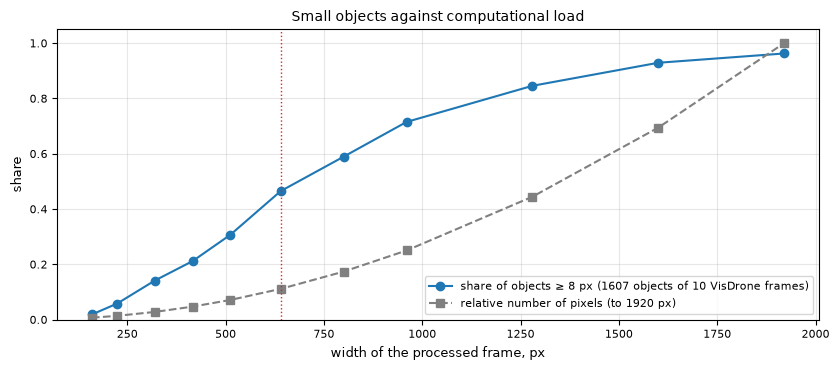

In [15]:
#@title 2.2.4-A Size of the processed frame, small objects and real time [auto] { run: "auto", display-mode: "form" }
FRAME_NUMBER = 4 #@param {type:"slider", min:1, max:8, step:1}
REGION = "whole frame" #@param ["whole frame", "central half (crop)", "lower half: near field (crop)"]
TARGET_WIDTH = 640 #@param {type:"slider", min:160, max:1920, step:32}
INTERPOLATION = "area" #@param ["nearest", "bilinear", "area", "bicubic", "Lanczos"]
MIN_OBJECT_PX = 8 #@param {type:"slider", min:2, max:20, step:1}
REQUIRED_FPS = 30 #@param {type:"slider", min:5, max:120, step:5}

INTERP = {"nearest": cv2.INTER_NEAREST, "bilinear": cv2.INTER_LINEAR, "area": cv2.INTER_AREA,
          "bicubic": cv2.INTER_CUBIC, "Lanczos": cv2.INTER_LANCZOS4}[INTERPOLATION]


def region_box(W, H):
    if REGION.startswith("central"):
        return W // 4, H // 4, W - W // 4, H - H // 4
    if REGION.startswith("lower"):
        return 0, H // 2, W, H
    return 0, 0, W, H


def resize_with_objects(img, objs):
    H, W = img.shape[:2]
    x1, y1, x2, y2 = region_box(W, H)
    crop = img[y1:y2, x1:x2]
    s = TARGET_WIDTH / crop.shape[1]
    out = cv2.resize(crop, (TARGET_WIDTH, max(1, int(round(crop.shape[0] * s)))), interpolation=INTERP)
    res = []
    for o in objs:
        b = o["box"]
        cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
        if not (x1 <= cx < x2 and y1 <= cy < y2):
            res.append(("outside the region", o, None))
            continue
        nb = [(b[0] - x1) * s, (b[1] - y1) * s, (b[2] - x1) * s, (b[3] - y1) * s]                     # formula (18)
        res.append(("kept" if min(nb[2] - nb[0], nb[3] - nb[1]) >= MIN_OBJECT_PX else "too small", o, nb))
    return out, s, res


fr = load_frame("VisDrone", FRAME_NUMBER)
img, objs = fr["img"], fr["objects"]
out, s, res = resize_with_objects(img, objs)
pipeline = lambda x: cv2.Canny(cv2.cvtColor(cv2.GaussianBlur(x, (5, 5), 0), cv2.COLOR_RGB2GRAY), 60, 140)
t_full = aitbc.time_call(lambda: pipeline(img), repeats=3)
t_new = aitbc.time_call(lambda: pipeline(out), repeats=5)
t_resize = aitbc.time_call(lambda: cv2.resize(img, (TARGET_WIDTH, out.shape[0]), interpolation=INTERP), repeats=5)

colors = {"kept": (0, 230, 0), "too small": (255, 60, 60), "outside the region": (150, 150, 150)}
shown_full = aitbc.draw_boxes(img, [dict(cls=st, box=o["box"]) for st, o, _ in res], colors, labels=False, thickness=2)
H, W = img.shape[:2]
x1, y1, x2, y2 = region_box(W, H)
cv2.rectangle(shown_full, (x1, y1), (x2 - 1, y2 - 1), (255, 255, 0), 3)
shown_new = aitbc.draw_boxes(out, [dict(cls=st, box=nb) for st, o, nb in res if nb is not None], colors, labels=False)
fig, ax = plt.subplots(1, 2, figsize=(18, 5.6))
ax[0].imshow(shown_full)
ax[0].set_title(f"{fr['caption']}: {W} × {H}; region of interest in yellow", fontsize=10)
ax[1].imshow(shown_new, interpolation="nearest")
ax[1].set_title(f"processed frame {out.shape[1]} × {out.shape[0]} ({INTERPOLATION}), shown enlarged; "
                f"green — kept, red — smaller than {MIN_OBJECT_PX} px", fontsize=10)
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

n_in = sum(st != "outside the region" for st, _, _ in res)
n_ok = sum(st == "kept" for st, _, _ in res)
rows = [("scale factor s", f"{s:.3f}"), ("pixels: original → processed", f"{W * H / 1e6:.2f} → {out.shape[0] * out.shape[1] / 1e6:.3f} Mpixel"),
        ("time of Gaussian 5×5 + Canny: original → processed, ms", f"{t_full:.1f} → {t_new:.2f} (plus resize {t_resize:.2f})"),
        (f"budget of a frame at {REQUIRED_FPS} frames/s, ms", f"{1000 / REQUIRED_FPS:.1f}"),
        ("annotated objects in the frame / in the region", f"{len(res)} / {n_in}"),
        (f"objects with a short side of {MIN_OBJECT_PX} px or more", f"{n_ok} ({n_ok / max(n_in, 1):.0%} of the region)")]
display(pd.DataFrame(rows, columns=["Quantity", "Value"]).set_index("Quantity"))

widths = [160, 224, 320, 416, 512, 640, 800, 960, 1280, 1600, 1920]
rel = []                                                                  # short side of every object / width of its frame
for name in vis.CURATED:
    im_, ob_ = vis.load(name)
    rel += [min(o["box"][2] - o["box"][0], o["box"][3] - o["box"][1]) / im_.shape[1] for o in ob_]
rel = np.array(rel, float)
share = [(rel * w_ >= MIN_OBJECT_PX).mean() for w_ in widths]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(widths, share, "o-", label=f"share of objects ≥ {MIN_OBJECT_PX} px ({len(rel)} objects of 10 VisDrone frames)")
ax.plot(widths, (np.array(widths) / 1920) ** 2, "s--", color="gray", label="relative number of pixels (to 1920 px)")
ax.axvline(TARGET_WIDTH, color="C3", ls=":", lw=1)
ax.set_xlabel("width of the processed frame, px")
ax.set_ylabel("share")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
ax.set_title("Small objects against computational load", fontsize=10)
plt.tight_layout()
plt.show()

### Block 2.2.5-A. Letterbox transformation and the standard input of a neural network [auto]

**Purpose.** To convert a real frame to the input of a detector of the YOLO family (a square S × S, usually 640 × 640) without a change of the shape of the objects, and to map the boxes between the frame and the input.

**Letterbox.** The frame W × H is scaled by one factor for both axes and padded symmetrically with the grey value 114:

$$r = \min\!\left(\frac{S}{W}, \frac{S}{H}\right), \quad W' = \operatorname{round}(r W), \quad H' = \operatorname{round}(r H), \quad d_x = \frac{S - W'}{2}, \quad d_y = \frac{S - H'}{2}. \tag{19}$$

A point of the frame and a point of the input are related by

$$x' = r x + d_x, \quad y' = r y + d_y; \qquad x = \frac{x' - d_x}{r}, \quad y = \frac{y' - d_y}{r}. \tag{20}$$

The boxes of the training labels are mapped by the direct relation, the boxes found by the detector — by the inverse relation. With minimal padding (`MINIMAL_PADDING`) the input is padded only to the nearest multiple of the stride 32 of the network, so that a 16:9 frame becomes 640 × 384 instead of 640 × 640; detectors use it at inference to save computation.

**Standard input.** After the letterbox the frame is converted to R, G, B, to the type float32 with values 0…1, to the layout C × H × W, and a batch axis is added: a tensor 1 × 3 × S × S. A thermal frame is repeated in the three channels.

**Alternatives for comparison.** *Stretch* — resize to S × S without keeping the aspect ratio: the input is filled, but the objects are deformed. *Centre crop* — scale the shorter side to S and cut the central square: the scale is kept, the objects at the sides are lost.

**Parameters.** `SOURCE`, `FRAME_NUMBER`; `INPUT_SIZE` S; `MODE`; `MINIMAL_PADDING`; `PAD_VALUE`; `SCALE_UP` — allow enlargement of frames smaller than S.

**What to observe.** For a VisDrone frame 1360 × 765 at S = 640 the letterbox gives r = 0.471 and 280 rows of padding: 44 % of the input are grey; with minimal padding the input is 640 × 384 (40 % fewer pixels). Stretching changes the aspect ratio of the objects by 1.78 times. The centre crop loses the objects at the left and right sides. The inverse mapping (20) returns the boxes to the frame exactly (error of the order of 10⁻¹³ px from the rounding of floating-point numbers).

In [16]:
#@title 2.2.5-A Letterbox and the standard input of a neural network [auto] { run: "auto", display-mode: "form" }
SOURCE = "VisDrone: visible, oblique view over a city" #@param ["VisDrone: visible, oblique view over a city", "M3OT: visible, day", "HIT-UAV: thermal (white-hot)", "Kust4K: visible", "GOOSE: ground vehicle, front camera", "own frame (block 0.3)"]
FRAME_NUMBER = 1 #@param {type:"slider", min:1, max:8, step:1}
INPUT_SIZE = "640" #@param ["320", "416", "512", "640", "960", "1280"]
MODE = "letterbox" #@param ["letterbox", "stretch (aspect ratio not kept)", "centre crop"]
MINIMAL_PADDING = False #@param {type:"boolean"}
PAD_VALUE = 114 #@param {type:"slider", min:0, max:255, step:1}
SCALE_UP = True #@param {type:"boolean"}

S = int(INPUT_SIZE)
fr = load_frame(SOURCE, FRAME_NUMBER)
img, objs = fr["img"], fr["objects"]
H, W = img.shape[:2]
boxes = [o["box"] for o in objs]
rows = [("frame W × H", f"{W} × {H}")]
if MODE == "letterbox":
    inp, r, pad = aitbc.letterbox(img, S, stride=32, auto=MINIMAL_PADDING, scaleup=SCALE_UP, color=PAD_VALUE)   # formula (19)
    mapped = aitbc.boxes_to_input(boxes, r, pad)                                                              # formula (20)
    back = aitbc.boxes_from_input(mapped, r, pad)
    err = float(np.abs(np.array(back) - np.array(boxes)).max()) if boxes else 0.0
    pad_share = 1 - (round(W * r) * round(H * r)) / (inp.shape[0] * inp.shape[1])
    rows += [("scale r (19)", f"{r:.4f}"), ("scaled frame W' × H'", f"{round(W * r)} × {round(H * r)}"),
             ("padding left / top, px", f"{pad[0]} / {pad[1]}"), ("share of the padding in the input", f"{pad_share:.1%}"),
             ("change of the aspect ratio of the objects", "none (1.00)"),
             ("largest error of the inverse mapping (20), px", f"{err:.2e}")]
elif MODE.startswith("stretch"):
    inp = cv2.resize(img, (S, S), interpolation=cv2.INTER_AREA if S < W else cv2.INTER_LINEAR)
    sx, sy = S / W, S / H
    mapped = [[b[0] * sx, b[1] * sy, b[2] * sx, b[3] * sy] for b in boxes]
    rows += [("scales along x / y", f"{sx:.4f} / {sy:.4f}"), ("share of the padding in the input", "0 %"),
             ("change of the aspect ratio of the objects", f"{max(sx, sy) / min(sx, sy):.2f} times")]
else:
    r = max(S / W, S / H)
    big = cv2.resize(img, (int(round(W * r)), int(round(H * r))), interpolation=cv2.INTER_AREA if r < 1 else cv2.INTER_LINEAR)
    ox, oy = (big.shape[1] - S) // 2, (big.shape[0] - S) // 2
    inp = big[oy:oy + S, ox:ox + S]
    mapped = [[b[0] * r - ox, b[1] * r - oy, b[2] * r - ox, b[3] * r - oy] for b in boxes]
    rows += [("scale r = max(S / W, S / H)", f"{r:.4f}"), ("cut away left / top, px of the scaled frame", f"{ox} / {oy}")]
inside = [b for b in mapped if (b[0] + b[2]) / 2 >= 0 and (b[1] + b[3]) / 2 >= 0 and (b[0] + b[2]) / 2 < inp.shape[1] and (b[1] + b[3]) / 2 < inp.shape[0]]
shorts = [min(b[2] - b[0], b[3] - b[1]) for b in inside]
x = aitbc.to_input_tensor(inp)
rows += [("input of the network", f"{inp.shape[1]} × {inp.shape[0]}"),
         ("annotated objects in the frame / in the input", f"{len(boxes)} / {len(inside)}"),
         ("short side of the smallest object in the input, px", f"{min(shorts):.1f}" if shorts else "—"),
         ("tensor of the network", f"{tuple(x.shape)}, {x.dtype}, values {x.min():.2f} … {x.max():.2f}, {x.nbytes / 1e6:.2f} MB")]

fig, ax = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw=dict(width_ratios=[W / H, inp.shape[1] / inp.shape[0]]))
ax[0].imshow(aitbc.draw_boxes(img, objs, vis.COLORS if SOURCE.startswith("VisDrone") else None, labels=False,
                               color=None if SOURCE.startswith("VisDrone") else (255, 235, 59)))
ax[0].set_title(f"{fr['caption']}: {W} × {H}, {len(boxes)} annotated objects", fontsize=10)
ax[1].imshow(aitbc.draw_boxes(inp, [dict(cls="object", box=b) for b in inside], {"object": (255, 235, 59)}, labels=False))
ax[1].set_title(f"input of the network ({MODE}): {inp.shape[1]} × {inp.shape[0]}", fontsize=10)
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows, columns=["Quantity", "Value"]).set_index("Quantity"))

*[Figure omitted in the public copy of the repository. It shows frames of the VisDrone2019-DET data set (Zhu P. et al., IEEE TPAMI 44(11), 2022), which is distributed for non-commercial use and is therefore not redistributed here. Run the cell in Google Colab to obtain the figure.]*

,Value
Quantity,
frame W × H,1360 × 765
scale r (19),0.4706
scaled frame W' × H',640 × 360
"padding left / top, px",0 / 140
share of the padding in the input,43.8%
change of the aspect ratio of the objects,none (1.00)
"largest error of the inverse mapping (20), px",2.27e-13
input of the network,640 × 640
annotated objects in the frame / in the input,164 / 164


### Summary of Lesson 2.2

- Preprocessing begins with a diagnosis of the frame: brightness, contrast, entropy, noise (13), clipped pixels and sharpness relative to the other frames of the stream. The cameras of the data sets reduce the noise before recording; at night the loss appears as low brightness, few levels and low sharpness.
- The Gaussian filter (14) is better for Gaussian noise, the median filter (15) for impulse noise; the smallest kernel that removes the noise is chosen. The effect of the filter is checked by the measures of the next step: on annotated thermal frames noise reduction restores most of the recall of the detector.
- Histogram equalisation (16) and CLAHE (17) increase the entropy and the average gradient and make details visible to the operator, but amplify the noise and do not increase the contrast of small objects against their background (SCR); global HE is unsuitable for thermal frames with small warm objects.
- Downscaling reduces the load as s² and the objects as s (18); a region of interest keeps the scale; the size of the processed frame is chosen from the time budget (11) and the size of the smallest objects.
- The letterbox (19)–(20) converts a frame to the square input of a detector without a deformation of the objects; the boxes are mapped forward for training and backward for the results. The standard input is a float32 tensor 1 × 3 × S × S with values 0…1 in the order R, G, B.

### Control questions
1. Which indicators of block 2.2.1-A point to a need of noise reduction, of contrast enhancement and of the rejection of a frame?
2. Why is the noise reduced before CLAHE and not after it?
3. Which filter is chosen against the sparkles of an analog link, and why? Which filter is chosen against the noise of a sensor at low light?
4. What value of σ does OpenCV use for a Gaussian kernel 7 × 7 when σ = 0 is given? *(σ = 0.3 · (3 − 1) + 0.8 = 1.4.)*
5. CLAHE with the clip limit c = 2 is applied to tiles of 80 × 64 pixels. At which height is the histogram of a tile clipped (L = 256)? *(β = 2 · 5120 / 256 = 40 pixels.)*
6. Why can CLAHE make the detection of a small warm object worse, although the picture looks more detailed?
7. A frame 1920 × 1080 is reduced to the width 960. How do the number of pixels, the processing time and the size of a person of 12 px change? *(4 times fewer pixels and about 4 times less time; 6 px.)*
8. Calculate r, W', H', d_x and d_y of the letterbox of a frame 1920 × 1080 to 640 × 640. Where is a box [960, 540, 1000, 600] of the frame on the input? *(r = 1/3; 640 × 360; d_x = 0, d_y = 140; [320, 320, 333.3, 340].)*
9. Why do detectors use the letterbox instead of stretching the frame to a square?

---
## Glossary

| Term | Meaning |
|---|---|
| Tensor, axis, layout | multidimensional array; its dimensions; order of the axes: H × W × C (NumPy, OpenCV), C × H × W and N × C × H × W (PyTorch), T × H × W × C (video) |
| Channel | one plane of values of a frame: R, G, B, thermal |
| Bit depth, quantisation | number of bits per value; replacement of a value by one of 2<sup>k</sup> levels (3) |
| Dynamic range, AGC | range of the signal of the sensor; automatic gain control that maps it to the 8-bit levels of a frame |
| RGB, HSV, luma | colour model of the sensor; hue, saturation, value; weighted grey level Y |
| IoU of masks, precision, recall | overlap of two masks; share of correct pixels of a mask; share of labelled pixels found |
| FOV, barrel distortion, vignetting | field of view; bending of straight lines by a wide-angle lens; darkening of the corners |
| Exposure, rolling shutter, jello | time of the accumulation of light; readout of the rows one after another; wobble from vibration during the readout |
| Link budget, FSPL, dBm, dBi | balance of power of a radio link; free-space path loss (7); power relative to 1 mW; gain of an antenna relative to an isotropic one |
| CNR, FM threshold, cliff effect | carrier-to-noise ratio (10); CNR below which an FM picture breaks into sparkles; sudden loss of a digital link near its sensitivity |
| Bit rate, bits per pixel | data rate of a compressed stream; bit rate divided by the pixels per second |
| Real time, utilisation | processing of every frame before the next one arrives (11); share of the time budget used |
| Processing rate, step N | frames processed per second; only every N-th frame is processed |
| Noise σ, Gaussian noise, impulse noise | standard deviation of the noise (13); noise added to every pixel; isolated black and white pixels |
| Kernel, Gaussian filter, median filter | neighbourhood k × k of a filter; weighted mean (14); median (15) |
| PSNR, SSIM | measures of the difference from a reference frame |
| Histogram, CDF, HE | distribution of the grey levels; its cumulative sum; equalisation by the CDF (16) |
| CLAHE, clip limit, tile | contrast-limited adaptive histogram equalisation; limit of the histogram of a tile (17); region of the frame with its own mapping |
| Entropy, average gradient, SCR | indicators of information and detail; contrast of an object against its background |
| Interpolation | computation of the values of a resampled frame: nearest neighbour, bilinear, area, bicubic, Lanczos |
| ROI, crop | region of interest; cut of a part of the frame |
| Letterbox, padding, stride | scaling with the aspect ratio kept and padding to the input size (19); added grey border; factor of the downsampling of a network (32) |
| Normalisation of the input | conversion to float32 with values 0…1 and to the layout of the network |

## Data sources and licences

The course library reads the files directly from the repositories of the authors; the data are not redistributed with the notebook. When images or results are published, the data sets are cited.

1. **VisDrone.** Zhu P., Wen L., Du D., Bian X., Fan H., Hu Q., Ling H. Detection and tracking meet drones challenge. *IEEE Transactions on Pattern Analysis and Machine Intelligence*, 44(11), 7380–7399 (2022). Data: https://github.com/VisDrone/VisDrone-Dataset · Terms of use: see the data set page.
2. **M3OT.** Nie Z., Xue L., Fang Z., Ren J., Wei Y., Zheng J. M3OT: A Multi-Drone Multi-Modality dataset for Multi-Object Tracking. *Scientific Data*, 12, 1927 (2025). https://doi.org/10.1038/s41597-025-06204-0 · Data: https://doi.org/10.6084/m9.figshare.28308887 · Licence CC BY 4.0.
3. **Kust4K.** Ouyang J., Wang Q., Shang Y., Jin P., Zhong H., Zhou L., Shen T. An RGB-TIR dataset from UAV platform for robust urban traffic scenes semantic segmentation. *Scientific Data*, 12, 1701 (2025). https://doi.org/10.1038/s41597-025-05994-7 · Data: https://doi.org/10.6084/m9.figshare.29476610 · Licence CC BY 4.0.
4. **HIT-UAV.** Suo J., Wang T., Zhang X., Chen H., Zhou W., Shi W. HIT-UAV: A high-altitude infrared thermal dataset for Unmanned Aerial Vehicle-based object detection. *Scientific Data*, 10, 227 (2023). https://doi.org/10.1038/s41597-023-02066-6 · Data: https://github.com/suojiashun/HIT-UAV-Infrared-Thermal-Dataset · Licence CC BY 4.0.
5. **GOOSE.** Mortimer P., Hagmanns R., Granero M., Luettel T., Petereit J., Wuensche H.-J. The GOOSE dataset for perception in unstructured environments. *IEEE ICRA*, 2024. https://arxiv.org/abs/2310.16788 · Data: https://goose-dataset.de · Licence CC BY-SA 4.0.

**Next notebook.** Notebook 04 — Topic 2, Lessons 2.3 and 2.4 (practical): channel decomposition and geometric normalisation of a video frame; filtering methods for the increase of the visual informativeness of video frames.